# ESC operating region on the crossed data set

**Question.** Which ESC settings (optimizer gain $k$, dither amplitude $a$, dither frequency $f$) are *safe* (the fuel
ratio settles close to the ideal ratio) and *optimal* (ESC collects almost all of the energy that tracking the ideal
ratio could add over a fixed $r = 0.5$)? And is this region the same for every plant, or does it depend on the plant?

**Data.** `data/OTO-crossed/` (made by `generators/OTO_ESC_crossed.py`). Every one of 2,005 ESC sets ran on every one
of 600 plants, so the ESC and the plant effects can be separated.
- ESC sets: sets 0-4 are the five sets chosen earlier (reference, fastest, fastest $a \ge 0.15$, fastest $f \le 3$,
  best energy $a \ge 0.1$). Sets 5-2004 are 2,000 quasi-random (Halton) sets: $k$ log-uniform in $[10^{-3}, 5]$,
  $a$ uniform in $[0.005, 0.6]$, $f$ uniform in $[0.5, 10]$ Hz. Shares of "the parameter space" below are taken over
  these 2,000 quasi-random sets only; the chosen five are reported separately.
- Plants, in seven families: static (constant ideal ratio), exp (exponential drift), timescale (plants of the first two
  families with both confinement times $\times 0.5$, $\times 2$ or $\times 3$), linear (ramp), step (jump at 20, 50 or 80 s),
  sine (oscillating ideal ratio) and random (as in OTO-ESC_fix).
- Starts: in the 13 steady blocks the plasma already runs at $r = 0.5$ (steady state, full density) and
  $\hat r_0 = 0.5$. In `from0.3` and `from0.7`, 30 plants start with the plasma and $\hat r$ at 0.3 or 0.7.
  `dt0.002` repeats 205 sets on 50 plants with a time step of 0.002 s instead of 0.01 s.

**Definitions.**
- *Settled* (tolerance 0.01 or 0.02): the dither-averaged applied ratio stays within the tolerance of $r_\mathrm{ideal}$
  until the end of the run. The *settling time* is when it last enters the band. For step plants the time is counted
  from the step, because no ESC can be within 0.01 of the new ideal ratio before the step happens.
- *Margin* $= E_\mathrm{ideal} - E_{r=0.5}$: what the plant offers over the fixed ratio. *Shortfall*
  $= E_\mathrm{ideal} - E_\mathrm{ESC}$. *Gain* $= E_\mathrm{ESC} - E_{r=0.5} =$ margin $-$ shortfall.
- *Energy score* $\eta = $ gain / margin: 1 means ESC collected the whole margin, 0 means it did as well as $r = 0.5$,
  negative means it lost. A plant with $r_\mathrm{ideal}$ (almost) at 0.5 has a margin near zero and $\eta$ is then
  meaningless, so $\eta$ is only computed on plants whose margin is at least the *margin floor* (set below).
- Averaged-ESC quantities, with the plant's own mean loss rate $\bar\alpha$ (= `esc.ALPHA_BAR` / `tau_scale`, so
  the timescale family has its own value): the convergence rate $\lambda_\mathrm{avg}$ (`esc.lam_avg`), the dimensionless
  speed $\lambda_\mathrm{avg} T$ ($T = 100$ s), the predicted dither loss $L_\mathrm{dith}$ (`esc.dither_loss`), and the
  ratio $\rho = \lambda_\mathrm{avg} / (2f)$ of the ESC rate to the cut-off of its filters ($\omega/\pi = 2f$ rad/s).
  $\rho$ is new in this notebook; Section 3 shows why it is needed.
- Sine plants keep moving, so "settling" on them measures tracking, not convergence. They are left out of the
  convergence and energy criteria and reported on their own.

**Sections.** 1 Convergence (safe) region. 2 Energy (optimal) region and the recommended operating window.
3 Does the region depend on the plant? 4 The two peaks of the gain distribution. 5 Time-step sensitivity (for JJ).
6 Conclusion.

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import esc_tools as esc
esc.apply_style()

## 0. Settings and data

The limits that define "safe" and "optimal" are choices, so they are set here in one place. Changing them changes
every number below. The blocks are read and joined with the ESC sets, the plants and the per-block reference
energies (`energy_const` for $r = 0.5$ and `energy_ideal` for $r = r_\mathrm{ideal}(t)$, made from the same start and
time step as the block).

In [2]:
TOL = '0.01'            # settling tolerance used for the region ('0.02' is shown for comparison)
MARGIN_FLOOR = 2.0      # energy units: plants with a smaller margin are left out of the eta statistics
ETA_MIN = 0.9           # optimal: at least this share of the margin collected, on the worst plant
T_MAX = 30.0            # s: worst settling time allowed at the steady start
B_BOOT = 1000           # bootstrap resamples (plants are resampled, each with all its runs)
RNG = np.random.default_rng(0)
T = esc.T_END
STEADY = ['static', 'exp1', 'exp2', 'timescale', 'linear', 'step', 'sine'] + [f'random{i}' for i in range(1, 7)]
FAMILIES = ['static', 'exp', 'timescale', 'linear', 'step', 'random', 'sine']
GROUPS = ['static', 'exp', 'linear', 'step', 'random', 'time x0.5', 'time x2', 'time x3']   # Section 3
FAM_COLOR = dict(zip(FAMILIES, esc.CYCLE))
GROUP_COLOR = dict(zip(GROUPS, esc.CYCLE))

sets = esc.read_data('OTO-crossed-sets.csv')
plants = esc.read_data('OTO-crossed-plants.csv')
refs = esc.read_data('OTO-crossed-references.csv')


def load_block(name):
    """One block joined with its references, the ESC sets and the plants, plus the derived columns."""
    d = esc.read_data(f'OTO-crossed-{name}.csv')
    d = d.merge(refs[refs.block == name].drop(columns='block'), on='plant', how='left')
    d = d.merge(sets[['set', *esc.ESC_PARAMS]], on='set')
    d = d.merge(plants[['plant', 'family', 'drift_class', 'drift_size', 'drift_time', 'tau_scale', 'r_ideal_0',
                        'offset_rms']], on='plant')
    d['block'] = name
    d['log10_gain'] = np.log10(d.optimizer_gain)
    d['alpha_bar'] = esc.ALPHA_BAR / d.tau_scale
    d['lam'] = esc.lam_avg(d.optimizer_gain, d.dither_frequency, d.alpha_bar)
    d['lamT'] = d.lam * T
    d['rho'] = d.lam / (2 * d.dither_frequency)
    d['L_dith'] = esc.dither_loss(d.dither_amplitude, d.dither_frequency, d.alpha_bar)
    d['margin'] = d.energy_ideal - d.energy_const
    d['eta'] = np.where(d.margin >= MARGIN_FLOOR, d.energy_gain / d.margin, np.nan)
    shift = np.where(d.family == 'step', d.drift_time, 0.0)
    for tol in ['0.01', '0.02']:
        d[f'settled_{tol}'] = d[f'settling_time_{tol}'].notna()
        d[f't_{tol}'] = d[f'settling_time_{tol}'] - shift
    d['group'] = np.where(d.family == 'timescale', 'time x' + d.tau_scale.map('{:g}'.format), d.family)
    return d


pairs = pd.concat([load_block(b) for b in STEADY], ignore_index=True)       # steady start, all sets x all plants
off = pd.concat([load_block(b) for b in ['from0.3', 'from0.7']], ignore_index=True)
dt2 = load_block('dt0.002')
conv = pairs[(pairs.family != 'sine') & (pairs.set >= 5)]                    # convergence plants, quasi-random sets
halton = sets.set >= 5

per_plant = pairs.drop_duplicates('plant')
print(f'steady start: {len(pairs):,} runs = {pairs.set.nunique():,} sets x {pairs.plant.nunique()} plants; '
      f'off-0.5 starts: {len(off):,} runs ({off.plant.nunique()} plants, 2 starts); dt = 0.002 s: {len(dt2):,} runs')
print('plants per family:', per_plant.family.value_counts().reindex(FAMILIES).to_dict())
below = per_plant[per_plant.margin < MARGIN_FLOOR]
print(f'margin floor {MARGIN_FLOOR:g} energy units: {len(below)} of {len(per_plant)} plants have a smaller margin and are '
      f'left out of eta: {below.family.value_counts().to_dict()}')
print(f'convergence plants (all but sine): {conv.plant.nunique()}; plants used for eta (not sine, margin >= floor): '
      f'{per_plant[(per_plant.family != "sine") & (per_plant.margin >= MARGIN_FLOOR)].shape[0]}')
print(f'margin over all plants: median {per_plant.margin.median():.1f}, max {per_plant.margin.max():.1f} energy units')

steady start: 1,203,000 runs = 2,005 sets x 600 plants; off-0.5 starts: 120,300 runs (30 plants, 2 starts); dt = 0.002 s: 10,250 runs
plants per family: {'static': 41, 'exp': 72, 'timescale': 30, 'linear': 30, 'step': 36, 'random': 364, 'sine': 27}
margin floor 2 energy units: 58 of 600 plants have a smaller margin and are left out of eta: {'random': 39, 'exp': 6, 'static': 5, 'timescale': 3, 'sine': 3, 'linear': 2}
convergence plants (all but sine): 573; plants used for eta (not sine, margin >= floor): 518
margin over all plants: median 17.0, max 138.8 energy units


Helper functions: smoothed maps over the parameter planes (`esc.binned_map`, 20 x 20 bins for the 2,000 quasi-random
sets, about five sets per bin, smoothed over 1.5 bins), lines of constant $\lambda_\mathrm{avg}$ in the $(k, f)$ plane,
figures drawn panel by panel (each multi-panel figure is followed by the same panels as separate, larger figures), and
bootstrap intervals in which the plants are resampled.

In [3]:
NB = esc.bins_for(2000, runs_per_bin=5)
EDGES = {'log10_gain': np.linspace(-3, np.log10(5), NB + 1), 'dither_frequency': np.linspace(0.5, 10, NB + 1),
         'dither_amplitude': np.linspace(0.005, 0.6, NB + 1)}
PLANES = {'kf': ('log10_gain', 'dither_frequency'), 'ka': ('log10_gain', 'dither_amplitude'),
          'fa': ('dither_frequency', 'dither_amplitude')}
F_LINE = np.linspace(0.5, 10, 200)


def bmap(d, plane, col, statistic='mean'):
    """Smoothed map of column `col` of d over a parameter plane."""
    xc, yc = PLANES[plane]
    return esc.binned_map(d[xc], d[yc], d[col].astype(float), EDGES[xc], EDGES[yc], statistic=statistic)


def draw_map(ax, z, plane, clabel, cmap='viridis', vmin=0, vmax=1, levels=(0.5, 0.9)):
    xc, yc = PLANES[plane]
    xe, ye = EDGES[xc], EDGES[yc]
    mesh = ax.pcolormesh(xe, ye, z.T, cmap=cmap, vmin=vmin, vmax=vmax, shading='flat')
    if levels:
        xm, ym = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
        cs = ax.contour(xm, ym, z.T, levels=list(levels), colors=['white', 'black'][:len(levels)], linewidths=1.2)
        ax.clabel(cs, fmt=lambda v: f'{v:.0%}' if vmax == 1 else f'{v:g}', fontsize=8)
    ax.figure.colorbar(mesh, ax=ax, label=clabel)
    ax.set_xlabel(esc.label(xc)); ax.set_ylabel(esc.label(yc)); ax.grid(False)


def k_for(f, lam=None, rho=None, alpha_bar=esc.ALPHA_BAR):
    """Gain k that gives the averaged rate lam [1/s], or the ratio rho = lam / (2 f), at dither frequency f."""
    if rho is not None:
        lam = rho * 2 * np.asarray(f)
    return lam / (2 * esc.N_REF**2 * esc.c_factor(f, alpha_bar))


def lam_lines(ax, lams=esc.LAM_WINDOW, color='0.85'):
    for lam, ls in zip(lams, ['--', ':']):
        ax.plot(np.log10(k_for(F_LINE, lam=lam)), F_LINE, color=color, ls=ls, lw=1.3,
                label=rf'$\lambda_\mathrm{{avg}}$ = {lam:g} 1/s')
    ax.set_xlim(EDGES['log10_gain'][[0, -1]]); ax.set_ylim(0.5, 10)


def map_legend(ax):
    ax.legend(loc='upper left', fontsize=8, frameon=True, facecolor='white', framealpha=0.85)


def show(panels, ncols, size=(5.4, 4.0)):
    """Combined figure (dpi 200). panels: list of (title, draw(ax))."""
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    fig.dpi = 200
    for i, (ax, (title, draw)) in enumerate(zip(axes.flat, panels)):
        draw(ax); ax.set_title(title); esc.panel_letter(ax, 'abcdefghij'[i])
    for ax in axes.flat[len(panels):]:
        ax.set_visible(False)
    fig.tight_layout(); plt.show()


def show_separate(panels):
    """The same panels, one per figure (dpi 150, 8 x 5.5 in)."""
    for title, draw in panels:
        fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
        draw(ax); ax.set_title(title); fig.tight_layout(); plt.show()


def boot_share(d, col):
    """Share of True in d[col] and its 95 % bootstrap interval (plants resampled with all their runs)."""
    per = d.groupby('plant')[col].agg(['sum', 'count'])
    w = RNG.multinomial(len(per), np.full(len(per), 1 / len(per)), size=B_BOOT)
    boot = (w @ per['sum'].values) / (w @ per['count'].values)
    return per['sum'].sum() / per['count'].sum(), np.percentile(boot, [2.5, 97.5])


def boot_pass(*fails):
    """Number of sets that pass on every plant (fails: DataFrames sets x plants, True = failed) and its 95 % bootstrap
    interval; the plants of each frame are resampled independently. The interval is biased upwards, because a
    resample holds only about 63 % of the distinct plants, so it shows sensitivity to the plant sample, not a
    textbook confidence interval."""
    passed = np.ones((len(fails[0]), B_BOOT), bool)
    for F in fails:
        P = F.shape[1]
        w = RNG.multinomial(P, np.full(P, 1 / P), size=B_BOOT).astype(np.float32)
        passed &= (F.values.astype(np.float32) @ w.T) == 0
    exact = np.logical_and.reduce([~F.values.any(1) for F in fails])
    return int(exact.sum()), np.percentile(passed.sum(0), [2.5, 97.5])


def pct(x, ci=None):
    return f'{x:.1%}' + (f' [{ci[0]:.1%}, {ci[1]:.1%}]' if ci is not None else '')


def crossings(x, y, bins, level=0.5, min_count=30):
    """Lower and upper x where the binned share of y crosses `level` around its maximum (NaN if it does not)."""
    n, _ = np.histogram(x, bins); s, _ = np.histogram(x, bins, weights=np.asarray(y, float))
    c = 0.5 * (bins[1:] + bins[:-1]); share = np.where(n >= min_count, s / np.maximum(n, 1), np.nan)
    i0 = np.nanargmax(share); lo = hi = np.nan
    for i in range(i0, 0, -1):
        if share[i] >= level > share[i - 1]:
            lo = c[i - 1] + (level - share[i - 1]) / (share[i] - share[i - 1]) * (c[i] - c[i - 1]); break
    for i in range(i0, len(c) - 1):
        if share[i] >= level > share[i + 1]:
            hi = c[i] + (share[i] - level) / (share[i] - share[i + 1]) * (c[i + 1] - c[i]); break
    return lo, hi


def share_curve(ax, x, y, bins, min_count=30, **kw):
    n, _ = np.histogram(x, bins); s, _ = np.histogram(x, bins, weights=np.asarray(y, float))
    ax.plot(0.5 * (bins[1:] + bins[:-1]), np.where(n >= min_count, s / np.maximum(n, 1), np.nan), **kw)

## 1. Convergence (safe) region

**What and why.** A setting is safe when the ratio settles close to the ideal ratio. Here a run counts as settled
when the dither-averaged applied ratio ends within 0.01 of $r_\mathrm{ideal}$ (0.02 shown for comparison; 0.02 counts
many runs as settled after their first swing towards the ideal ratio, so 0.01 is used for the region). The maps show,
for each small cell of the $(k, f)$ and $(k, a)$ planes, the share of runs that settled, pooled over the 573
convergence plants (all families but sine). The white and black contours are the 50 % and 90 % levels; the grey lines
are the averaged-ESC window $\lambda_\mathrm{avg} = 0.1$ and $3$ 1/s used in the earlier notebooks (nominal plant).

share of runs settled (quasi-random sets x convergence plants): tol 0.01 61.9% [61.0%, 63.0%], tol 0.02 71.9% [70.8%, 72.9%]
kf01: share of the plane where >= 90 % of runs settle: 34.8%; >= 50 %: 60.5%
kf02: share of the plane where >= 90 % of runs settle: 46.8%; >= 50 %: 72.0%
ka01: share of the plane where >= 90 % of runs settle: 12.8%; >= 50 %: 69.0%
median settling time (tol 0.01) of settled runs: 7.0 s


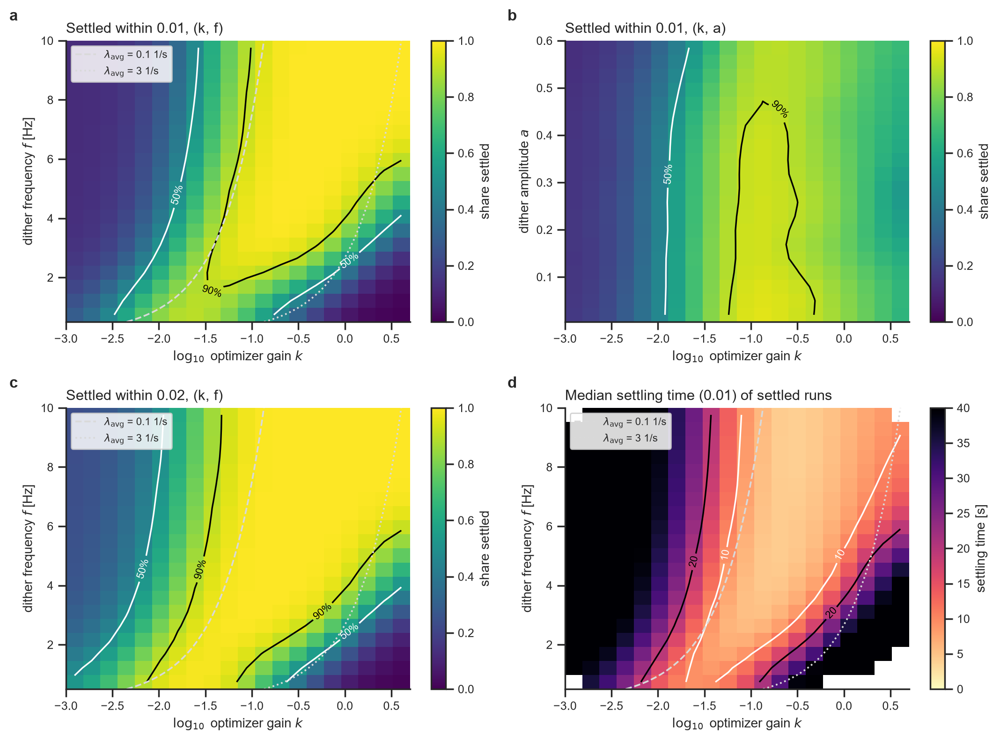

In [4]:
s01, ci01 = boot_share(conv, 'settled_0.01'); s02, ci02 = boot_share(conv, 'settled_0.02')
print(f'share of runs settled (quasi-random sets x convergence plants): tol 0.01 {pct(s01, ci01)}, tol 0.02 {pct(s02, ci02)}')
Z1 = {'kf01': bmap(conv, 'kf', 'settled_0.01'), 'ka01': bmap(conv, 'ka', 'settled_0.01'),
      'kf02': bmap(conv, 'kf', 'settled_0.02'),
      'kft': bmap(conv[conv['settled_0.01']], 'kf', 't_0.01', statistic='median')}
for key in ['kf01', 'kf02', 'ka01']:
    z = Z1[key]; ok = np.isfinite(z)
    print(f'{key}: share of the plane where >= 90 % of runs settle: {np.mean(z[ok] >= 0.9):.1%}; >= 50 %: {np.mean(z[ok] >= 0.5):.1%}')
print(f'median settling time (tol 0.01) of settled runs: {conv.loc[conv["settled_0.01"], "t_0.01"].median():.1f} s')


def p_map(key, plane, clabel, **kw):
    def draw(ax):
        draw_map(ax, Z1[key], plane, clabel, **kw)
        if plane == 'kf':
            lam_lines(ax); map_legend(ax)
    return draw


panels_1a = [('Settled within 0.01, (k, f)', p_map('kf01', 'kf', 'share settled')),
             ('Settled within 0.01, (k, a)', p_map('ka01', 'ka', 'share settled')),
             ('Settled within 0.02, (k, f)', p_map('kf02', 'kf', 'share settled')),
             ('Median settling time (0.01) of settled runs', p_map('kft', 'kf', 'settling time [s]', cmap='magma_r',
                                                                     vmin=0, vmax=40, levels=(10, 20)))]
show(panels_1a, 2)

The same maps, one per figure.

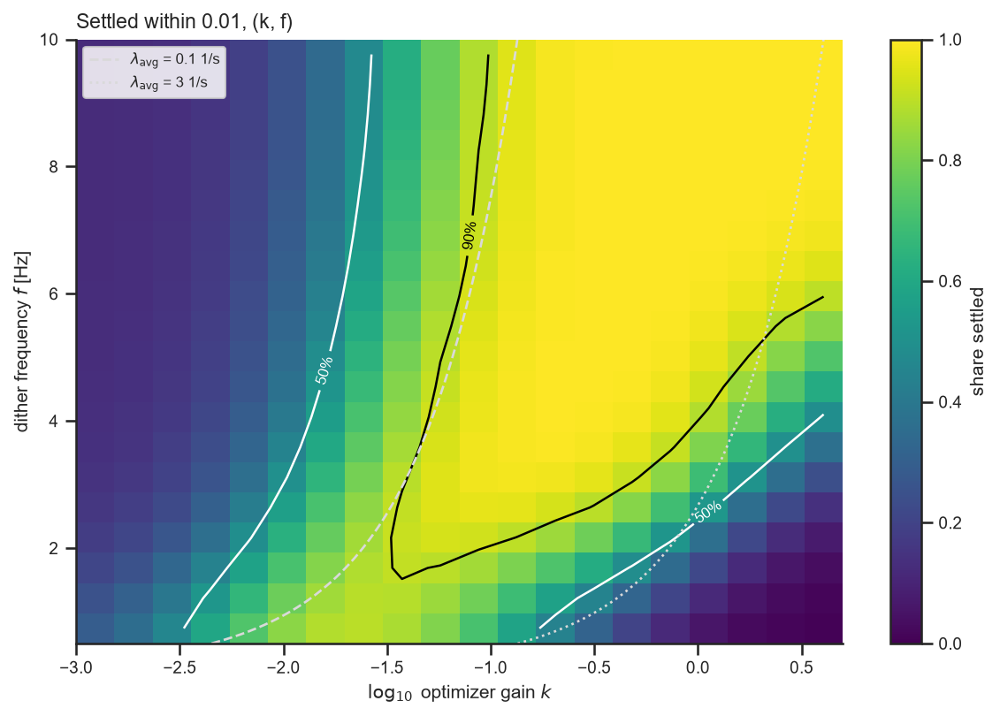

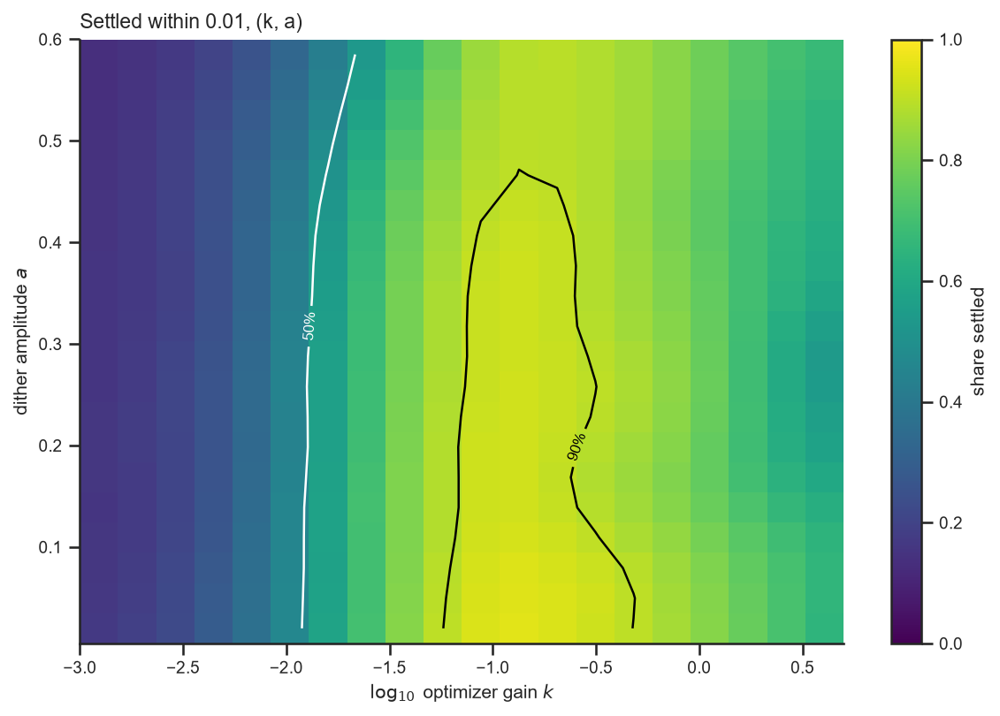

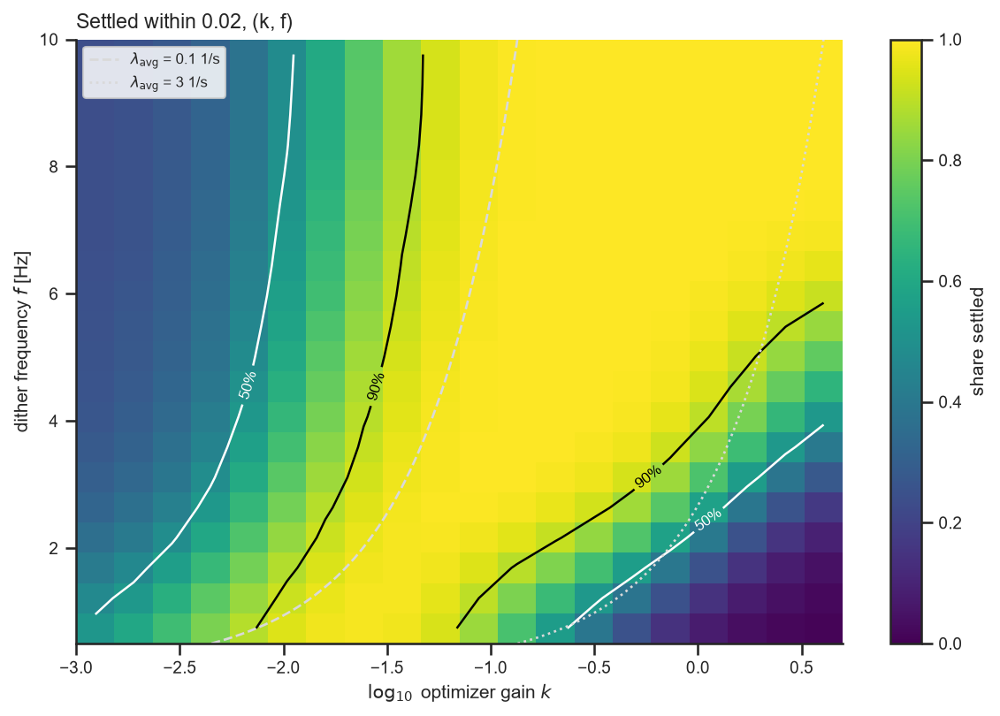

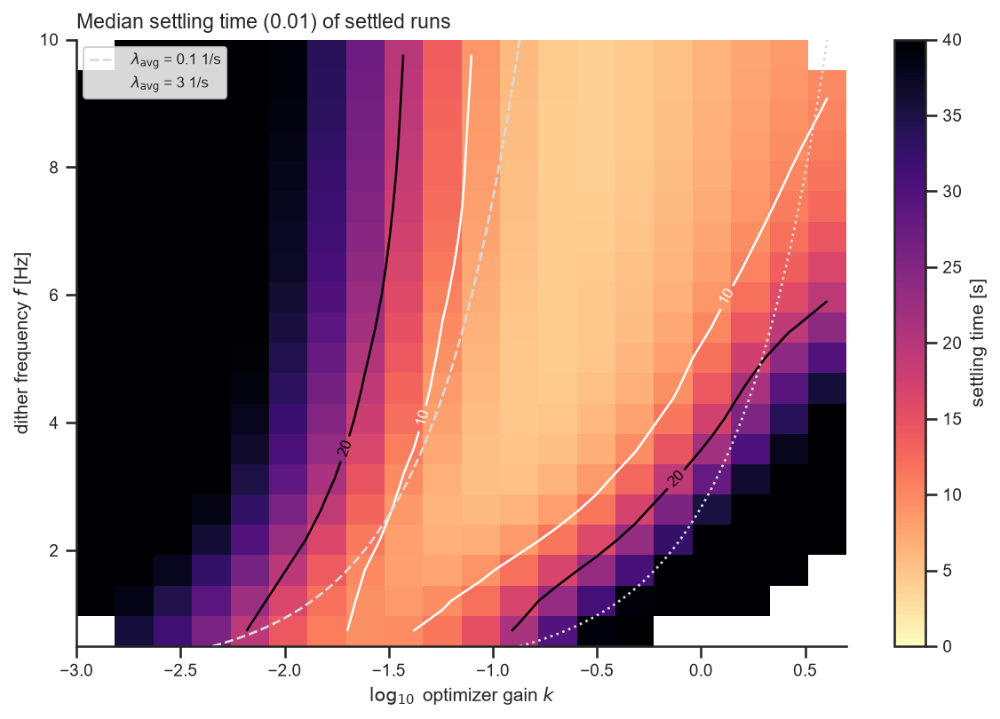

In [5]:
show_separate(panels_1a)

**What this shows.** The safe region is a diagonal band in the $(k, f)$ plane: too small a gain never settles within the
run (left), and too large a gain at a low dither frequency overshoots or goes unstable (lower right). Its left edge follows the line of constant $\lambda_\mathrm{avg}$ at low $f$ and becomes steep at high $f$, as in
the STO notebook. In the $(k, a)$ plane the band hardly depends on $a$, except that very small amplitudes make the
edge ragged. The 0.02 tolerance gives the same shape but a larger safe area (printed above). Inside the band most
runs settle within the times shown in the last map.

### 1.1 Starting away from 0.5

**What and why.** In `from0.3` and `from0.7` the plasma runs at $r = 0.3$ or $0.7$ and $\hat r$ starts there, so the ESC
has to travel about 0.2 instead of a few hundredths. The same 30 plants also ran with the steady start, so the three
starts can be compared run for run.

30 off-start plants per family: {'timescale': 15, 'exp': 10, 'static': 5}
steady 0.5: settled 67.3% [62.9%, 71.7%]; sets settled on all 30 plants 712 of 2000; median settling time 9.1 s (90th percentile 45.5 s)
from 0.3  : settled 57.4% [55.5%, 59.2%]; sets settled on all 30 plants 696 of 2000; median settling time 21.4 s (90th percentile 58.6 s)
from 0.7  : settled 57.9% [55.9%, 59.6%]; sets settled on all 30 plants 695 of 2000; median settling time 21.7 s (90th percentile 59.8 s)
runs settled at the steady start but not at both off starts: 11.2%; the reverse: 0.0%


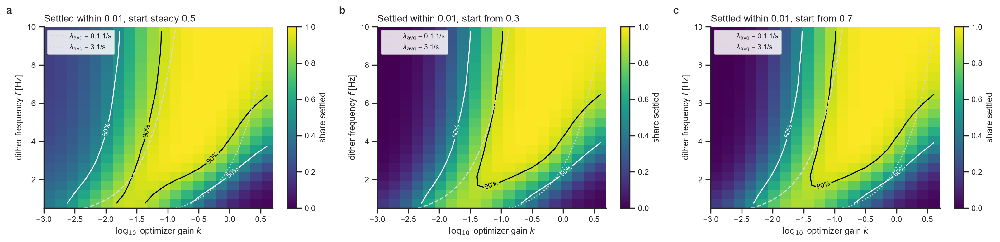

In [6]:
same = pairs[pairs.plant.isin(off.plant.unique()) & (pairs.set >= 5)]
cases = {'steady 0.5': same, 'from 0.3': off[(off.block == 'from0.3') & (off.set >= 5)],
         'from 0.7': off[(off.block == 'from0.7') & (off.set >= 5)]}
print('30 off-start plants per family:', off.drop_duplicates('plant').family.value_counts().to_dict())
Z_off = {}
for name, d in cases.items():
    sh, ci = boot_share(d, 'settled_0.01')
    all_ok = d.groupby('set')['settled_0.01'].all()
    t = d.loc[d['settled_0.01'], 't_0.01']
    Z_off[name] = bmap(d, 'kf', 'settled_0.01')
    print(f'{name:10s}: settled {pct(sh, ci)}; sets settled on all 30 plants {all_ok.sum()} of {len(all_ok)}; '
          f'median settling time {t.median():.1f} s (90th percentile {t.quantile(0.9):.1f} s)')
both = cases['from 0.3'].set_index(['set', 'plant'])['settled_0.01'] & cases['from 0.7'].set_index(['set', 'plant'])['settled_0.01']
st_same = same.set_index(['set', 'plant'])['settled_0.01']
print(f'runs settled at the steady start but not at both off starts: {(st_same & ~both.reindex(st_same.index)).mean():.1%}; '
      f'the reverse: {(~st_same & both.reindex(st_same.index)).mean():.1%}')


def p_off(name):
    def draw(ax):
        draw_map(ax, Z_off[name], 'kf', 'share settled'); lam_lines(ax); map_legend(ax)
    return draw


panels_1b = [(f'Settled within 0.01, start {name}', p_off(name)) for name in cases]
show(panels_1b, 3)

The same maps, one per figure.

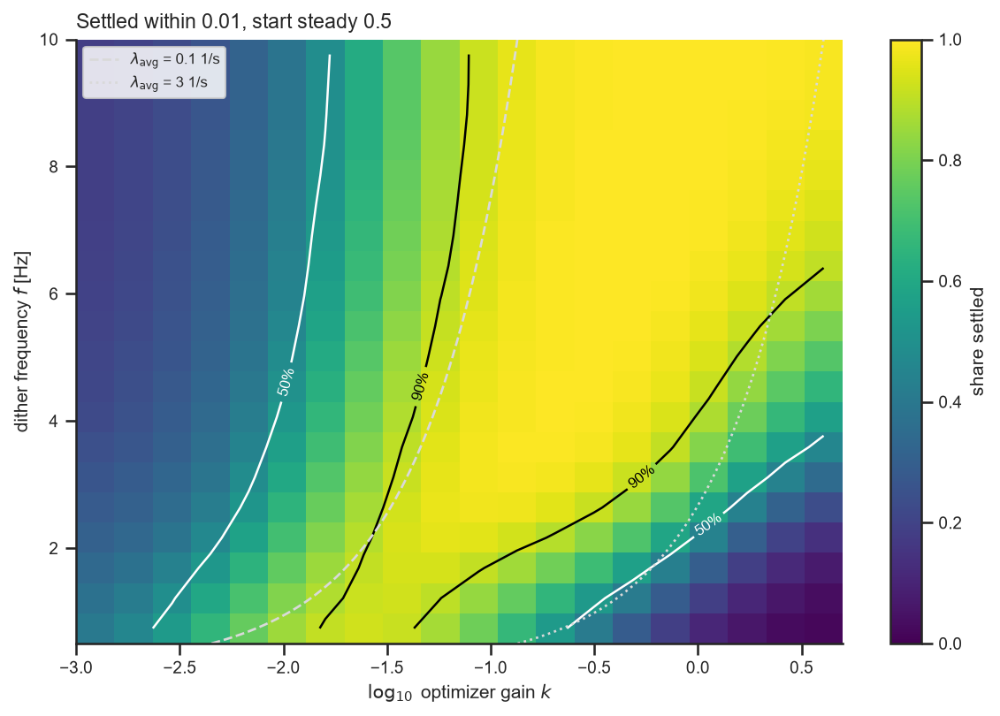

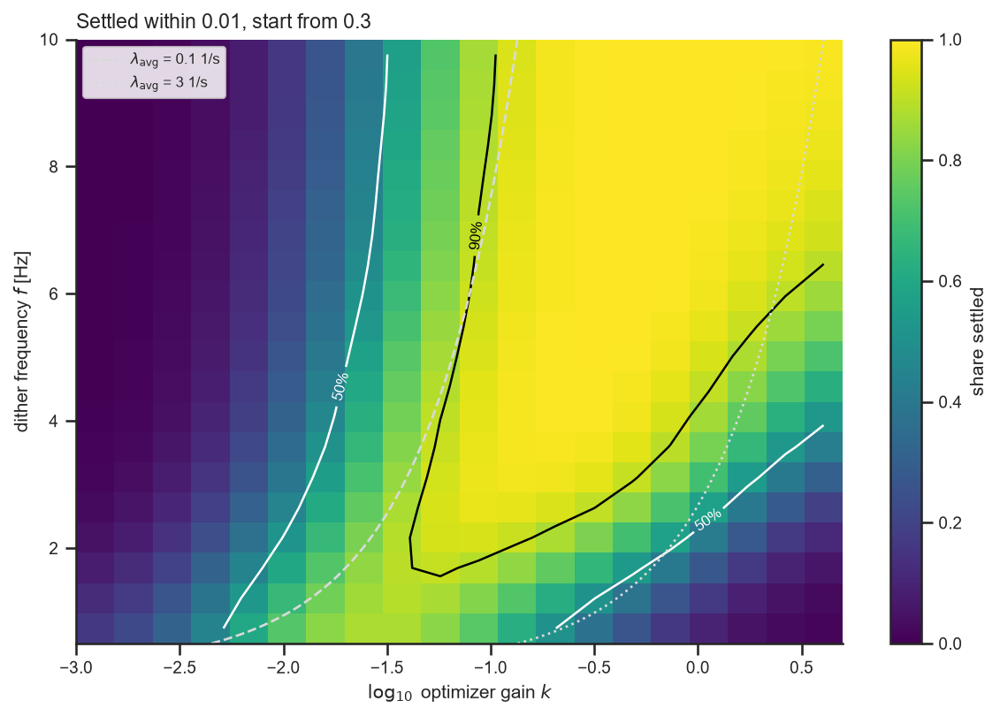

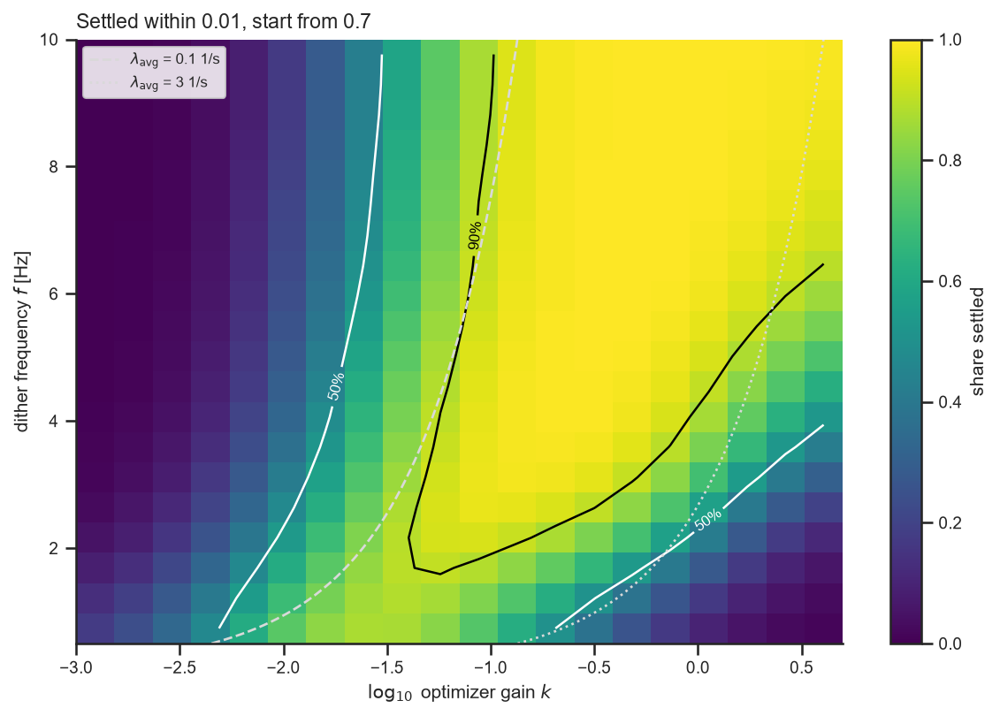

In [7]:
show_separate(panels_1b)

**What this shows.** Starting far from the optimum moves the left edge of the safe band to larger gains: a slow ESC
that would settle from 0.5 runs out of time when it has to cover 0.2. The right (high-gain) edge barely moves. The
settling times are longer than at the steady start (printed above). The two off starts behave almost the same, so
the direction of the offset (deuterium-rich or tritium-rich) does not matter with the steady-state start.

### 1.2 Per plant family

**What and why.** The same map for each family separately, to see whether some plants need other settings. The last
panel overlays the 90 % contours of all families. Sine plants are included here for comparison only: their ideal
ratio keeps moving, so "settled" means "tracks within 0.01 until the end".

   family  plants              settled  sets settled on every plant  median settling time [s]
   static      41 72.0% [69.4%, 74.7%]                         1193                      10.3
      exp      72 58.3% [55.9%, 60.9%]                          822                       9.0
timescale      30 63.1% [57.9%, 68.4%]                          521                      11.4
   linear      30 60.8% [57.3%, 65.0%]                          891                       8.0
     step      36 60.8% [56.3%, 65.8%]                          715                       8.0
   random     364 61.6% [60.3%, 62.9%]                          840                       5.9
     sine      27 31.9% [24.0%, 41.5%]                           18                      10.4


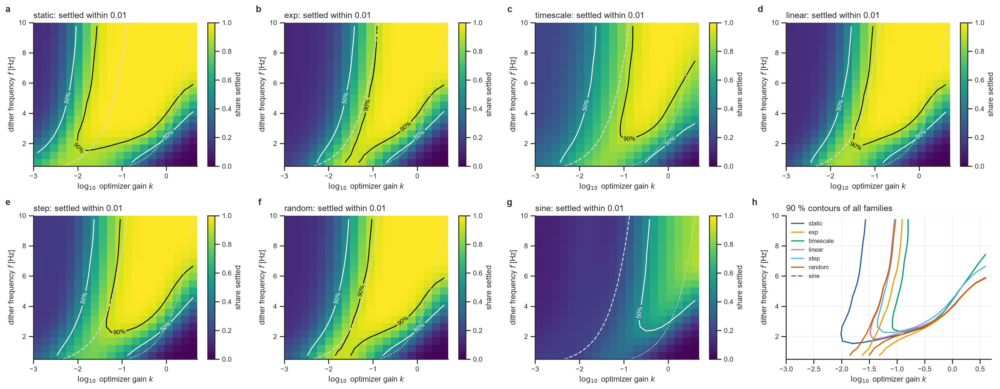

In [8]:
pairs_h = pairs[pairs.set >= 5]
Z_fam = {fam: bmap(pairs_h[pairs_h.family == fam], 'kf', 'settled_0.01') for fam in FAMILIES}
rows = []
for fam in FAMILIES:
    d = pairs_h[pairs_h.family == fam]
    sh, ci = boot_share(d, 'settled_0.01')
    rows.append({'family': fam, 'plants': d.plant.nunique(), 'settled': pct(sh, ci),
                 'sets settled on every plant': int(d.groupby('set')['settled_0.01'].all().sum()),
                 'median settling time [s]': round(d.loc[d['settled_0.01'], 't_0.01'].median(), 1)})
print(pd.DataFrame(rows).to_string(index=False))


def p_fam(fam):
    def draw(ax):
        draw_map(ax, Z_fam[fam], 'kf', 'share settled'); lam_lines(ax)
    return draw


def p_fam_overlay(ax):
    xe, ye = EDGES['log10_gain'], EDGES['dither_frequency']
    xm, ym = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
    for fam in FAMILIES:
        ax.contour(xm, ym, Z_fam[fam].T, levels=[0.9], colors=[FAM_COLOR[fam]], linewidths=1.6,
                   linestyles='--' if fam == 'sine' else '-')
        ax.plot([], [], color=FAM_COLOR[fam], ls='--' if fam == 'sine' else '-', label=fam)
    ax.legend(fontsize=8, loc='upper left'); ax.set_xlim(xe[[0, -1]]); ax.set_ylim(ye[[0, -1]])
    ax.set_xlabel(esc.label('log10_gain')); ax.set_ylabel(esc.label('dither_frequency'))


panels_1c = [(f'{fam}: settled within 0.01', p_fam(fam)) for fam in FAMILIES] + [('90 % contours of all families', p_fam_overlay)]
show(panels_1c, 4, size=(4.6, 3.6))

The same maps, one per figure.

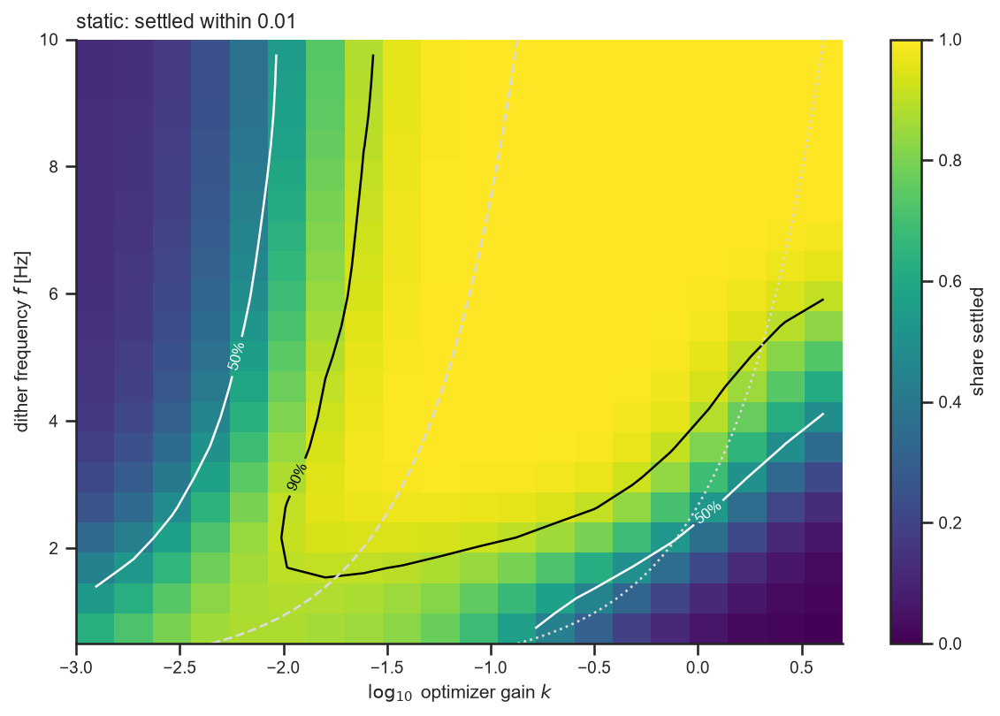

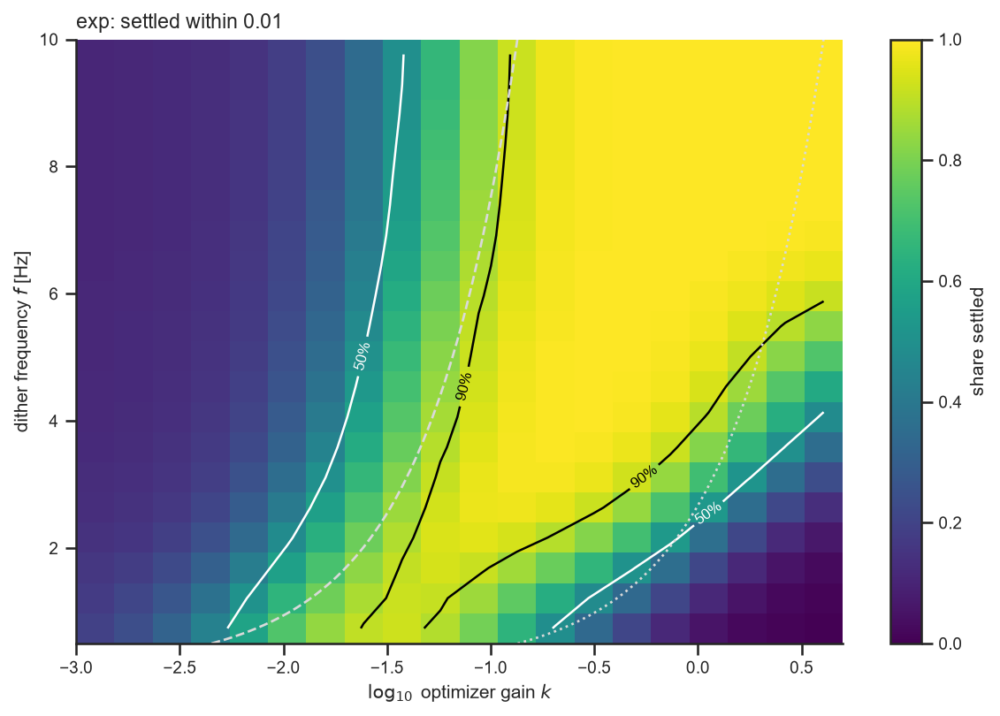

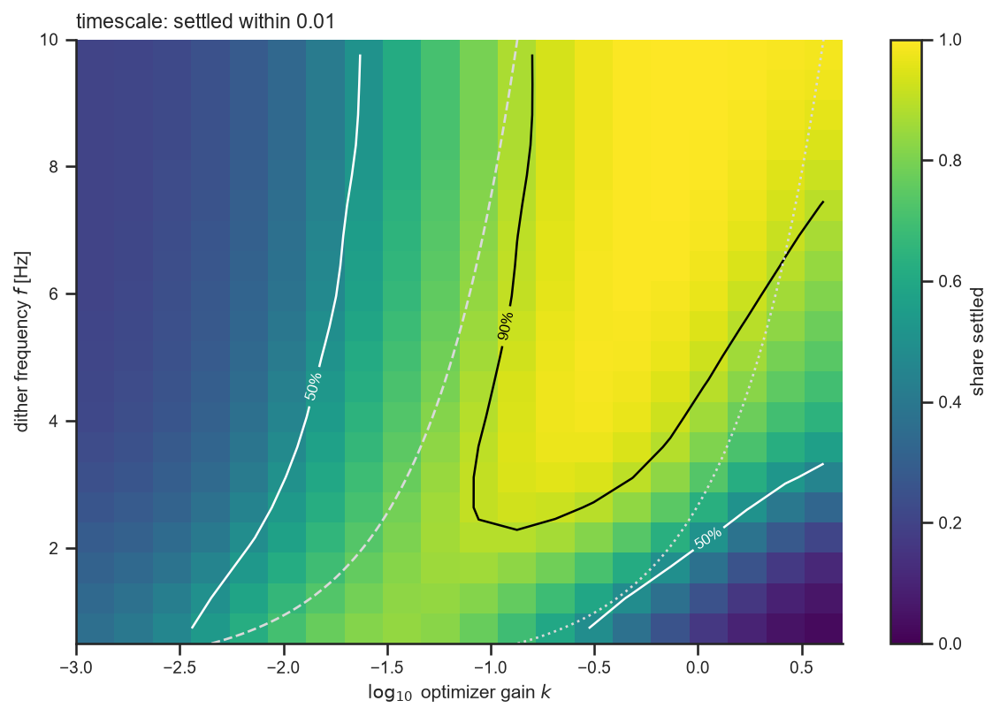

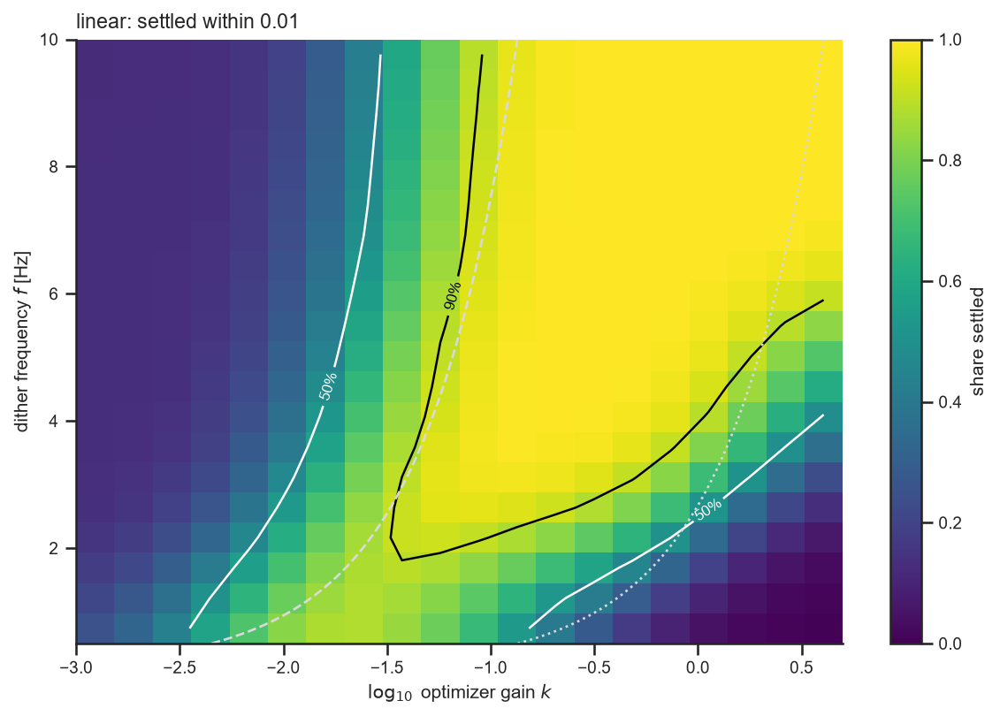

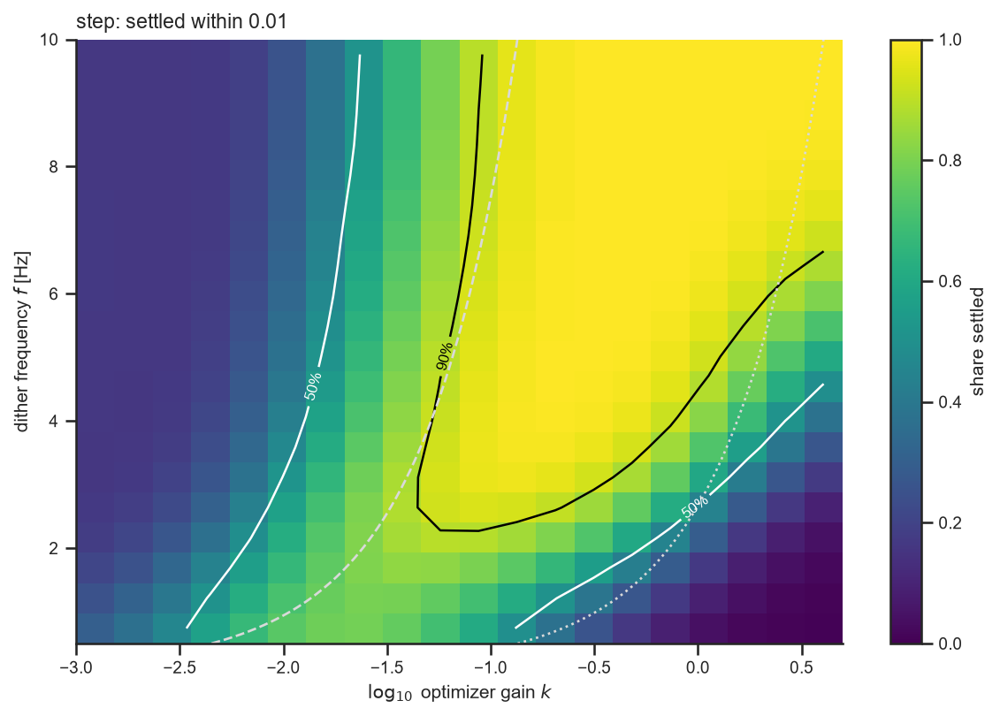

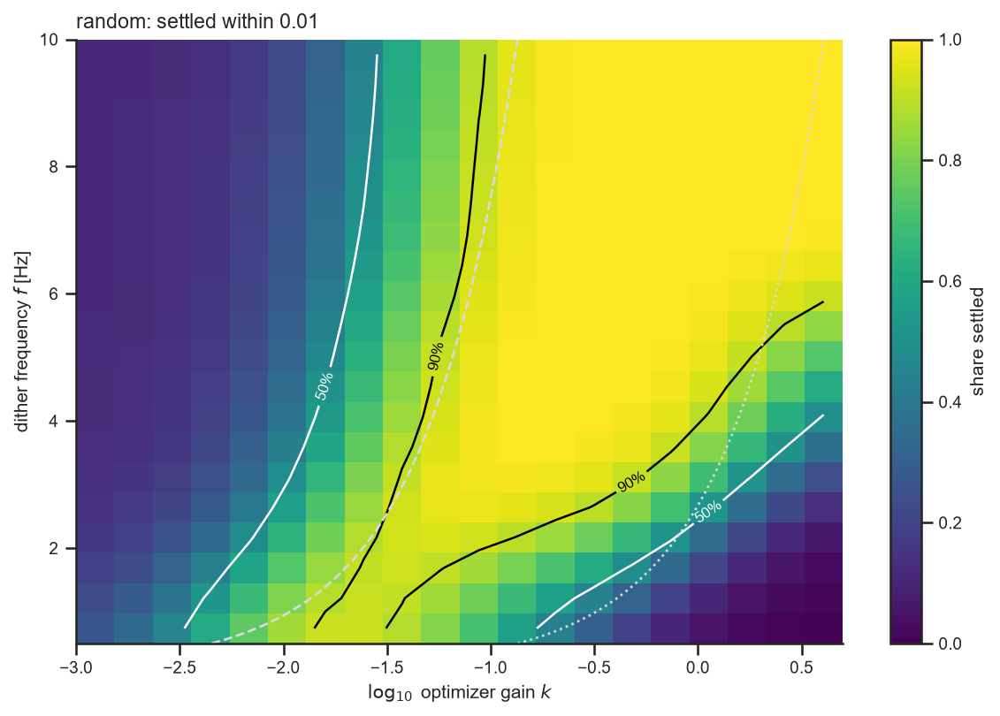

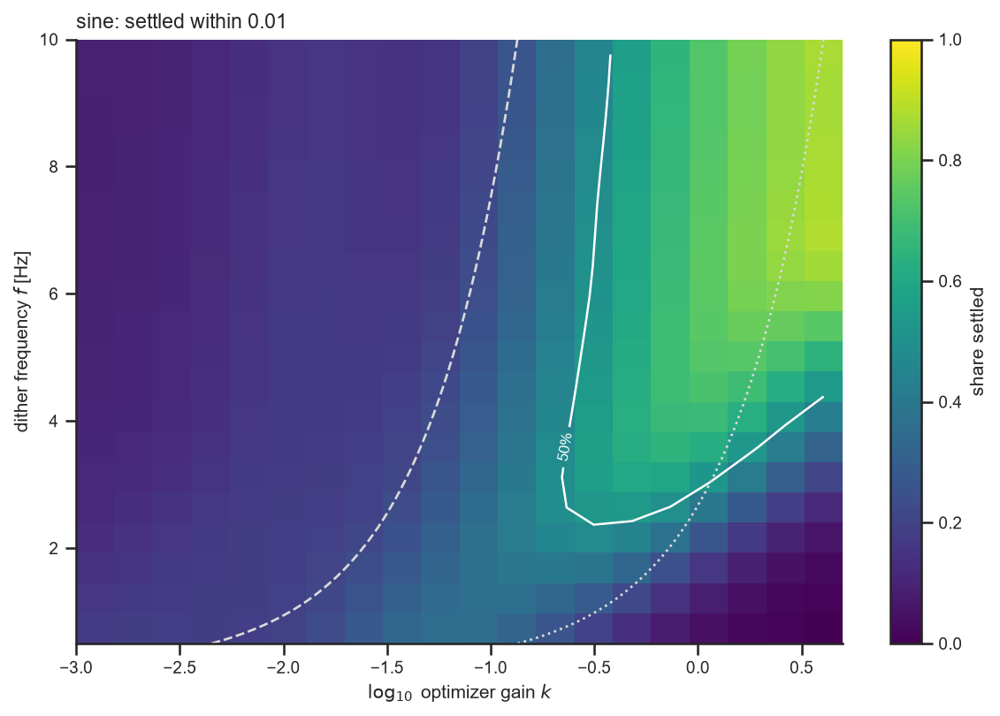

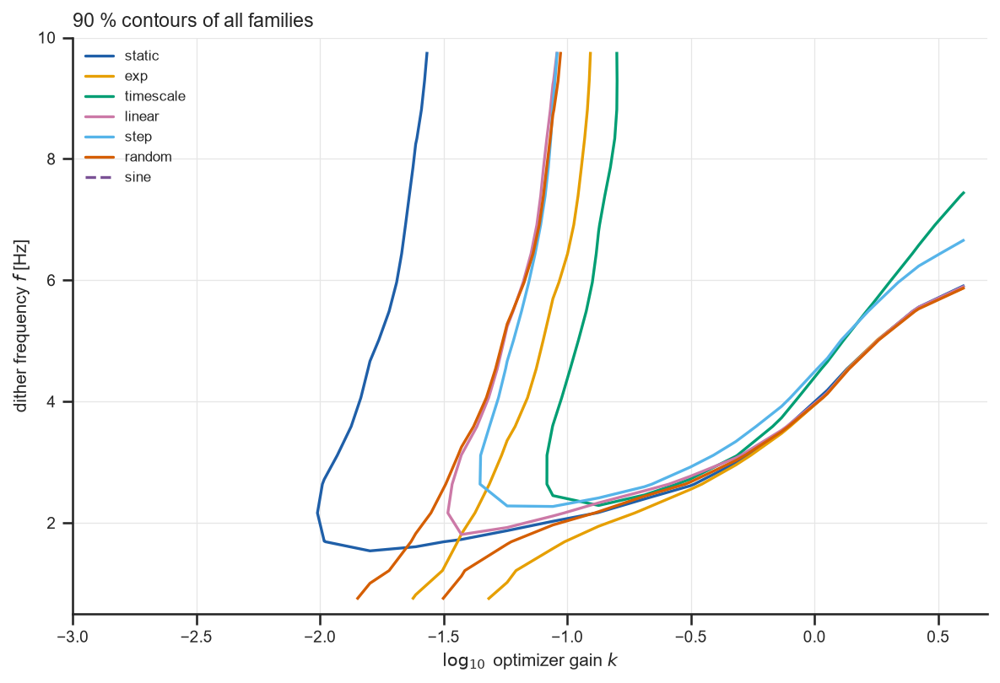

In [9]:
show_separate(panels_1c)

**What this shows.** The non-sine families share the same band in outline. Static plants settle with the smallest gains
(nothing moves, so a slow ESC still arrives); the drifting families need somewhat larger gains; the timescale family is
shifted at both edges, because it mixes slower and faster plants (Section 3 splits it by time scale). On sine plants the 90 % region is small
or absent: tracking a moving ideal ratio within 0.01 is harder than converging to a fixed one, and it needs the fast
settings at the right of the band.

### 1.3 Worst case over the plants

**What and why.** An operator does not know the plant in advance, so a set should settle on *every* plant. For each
set: does it settle on all 573 convergence plants, and what is its worst settling time? The maps show the share of
sets in each cell that pass, and the median worst settling time of those that do. The bracket is the bootstrap
interval over plants (see `boot_pass`).

quasi-random sets settled within 0.01 on all 573 convergence plants: 506 of 2000 (25.3%); bootstrap 95 % range 506-588
with tolerance 0.02: 783 sets
worst settling time of these sets: median 23.9 s, range 14.4-86.3 s
plant group that sets the worst settling time: {'time x3': 487, 'time x0.5': 16, 'static': 2, 'time x2': 1}


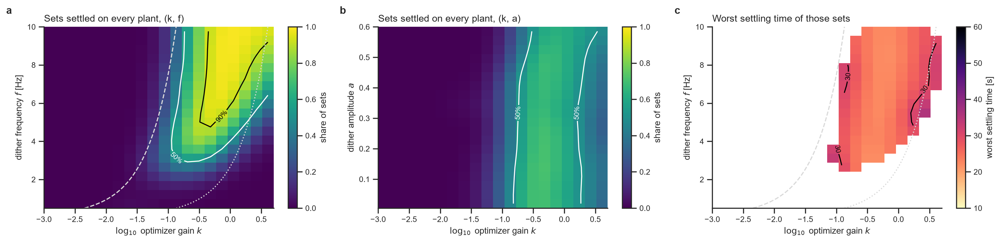

In [10]:
fail_settle = ~conv.set_index(['set', 'plant'])['settled_0.01'].unstack()
t_settle = conv.set_index(['set', 'plant'])['t_0.01'].unstack()
n_all, ci_all = boot_pass(fail_settle)
print(f'quasi-random sets settled within 0.01 on all {fail_settle.shape[1]} convergence plants: {n_all} of {len(fail_settle)} '
      f'({n_all / len(fail_settle):.1%}); bootstrap 95 % range {ci_all[0]:.0f}-{ci_all[1]:.0f}')
n02 = (~conv.set_index(['set', 'plant'])['settled_0.02'].unstack()).any(axis=1)
print(f'with tolerance 0.02: {(~n02).sum()} sets')
ok_sets = fail_settle.index[~fail_settle.any(axis=1)]
w_ok = conv[conv.set.isin(ok_sets)]
w_ok = w_ok.loc[w_ok.groupby('set')['t_0.01'].idxmax()]
print(f'worst settling time of these sets: median {w_ok["t_0.01"].median():.1f} s, range {w_ok["t_0.01"].min():.1f}-{w_ok["t_0.01"].max():.1f} s')
print('plant group that sets the worst settling time:', w_ok.group.value_counts().to_dict())
per_set = sets[halton].set_index('set').assign(log10_gain=lambda s: np.log10(s.optimizer_gain))
per_set['settled_all'] = ~fail_settle.any(axis=1)
per_set['t_worst'] = np.where(per_set.settled_all, t_settle.max(axis=1), np.nan)
Z1w = {'kf': bmap(per_set, 'kf', 'settled_all'), 'ka': bmap(per_set, 'ka', 'settled_all'),
       'kft': bmap(per_set[per_set.settled_all], 'kf', 't_worst', statistic='median')}

panels_1d = [('Sets settled on every plant, (k, f)', lambda ax: (draw_map(ax, Z1w['kf'], 'kf', 'share of sets'), lam_lines(ax))),
             ('Sets settled on every plant, (k, a)', lambda ax: draw_map(ax, Z1w['ka'], 'ka', 'share of sets')),
             ('Worst settling time of those sets', lambda ax: (draw_map(ax, Z1w['kft'], 'kf', 'worst settling time [s]',
                                                                       cmap='magma_r', vmin=10, vmax=60, levels=(20, 30)), lam_lines(ax)))]
show(panels_1d, 3)

The same maps, one per figure.

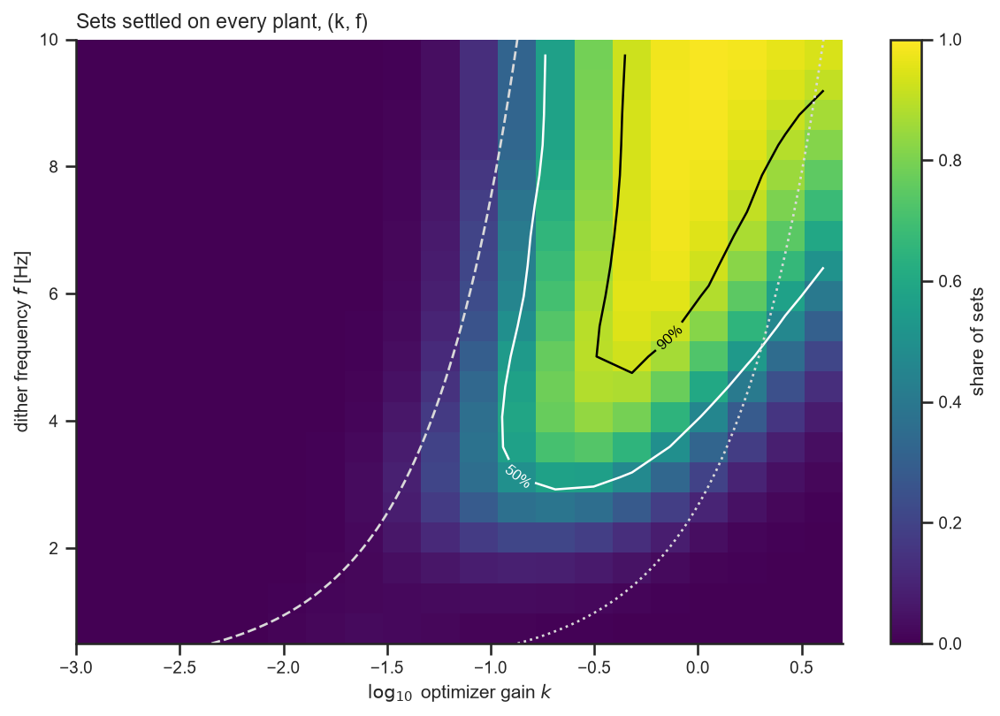

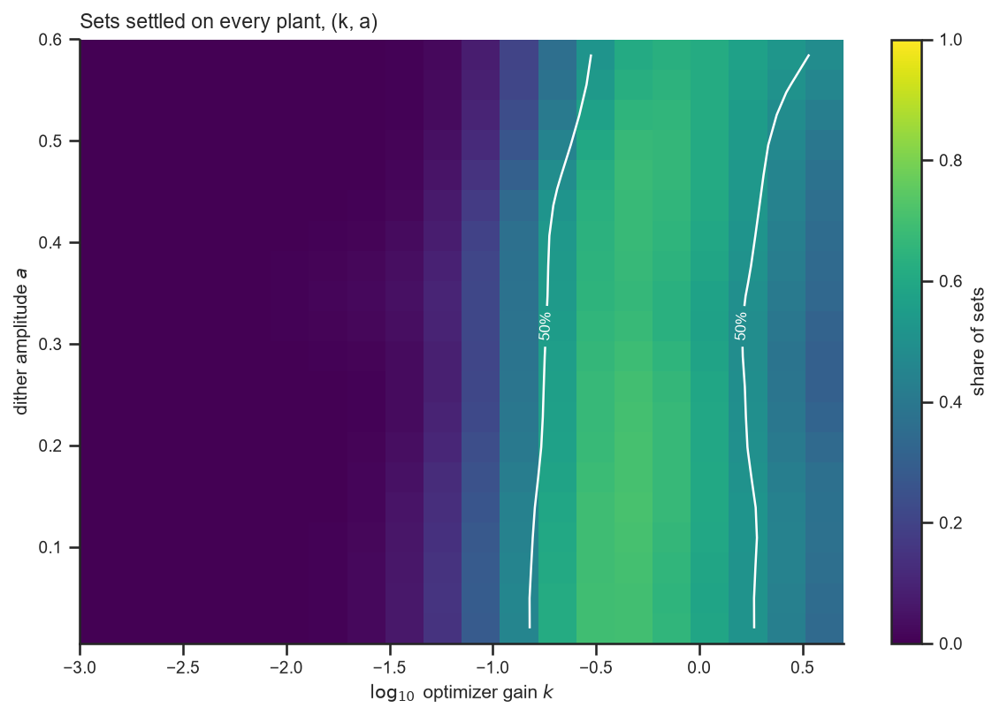

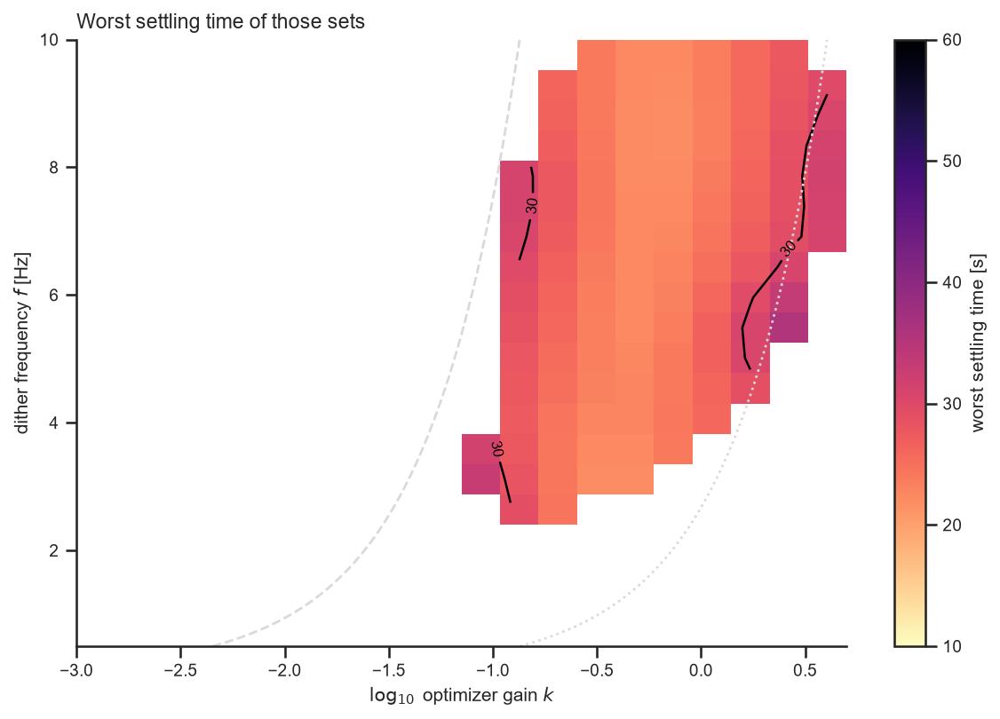

In [11]:
show_separate(panels_1d)

**What this shows.** Requiring convergence on every plant shrinks the band from both sides, and what is left lies at
dither frequencies above a few hertz. The worst settling time is almost always set by the slowest plants (confinement
times $\times 3$, printed above): in seconds, a set can never be faster than the slowest plant allows. Section 3
checks whether this is just the plant's time scale.

### 1.4 Against the averaged rate $\lambda_\mathrm{avg} T$

**What and why.** The averaged-ESC theory predicts that convergence is set by $\lambda_\mathrm{avg} T$, the number of
e-folding times of the ESC in one run. Here $\lambda_\mathrm{avg}$ uses each plant's own $\bar\alpha$. If the theory
holds, all families should follow one curve.

   family  lower 50 % edge, lamT  upper 50 % edge, lamT settled inside 0.1 < lam_avg < 3 1/s
   static                   1.04                  498.0                                95.6%
      exp                   4.13                  500.0                                97.1%
timescale                   1.88                  442.0                                96.3%
   linear                   3.12                  499.0                                95.4%
     step                   2.19                  450.0                                93.8%
   random                   3.04                  501.0                                96.2%
     sine                  38.88                  488.0                                52.2%


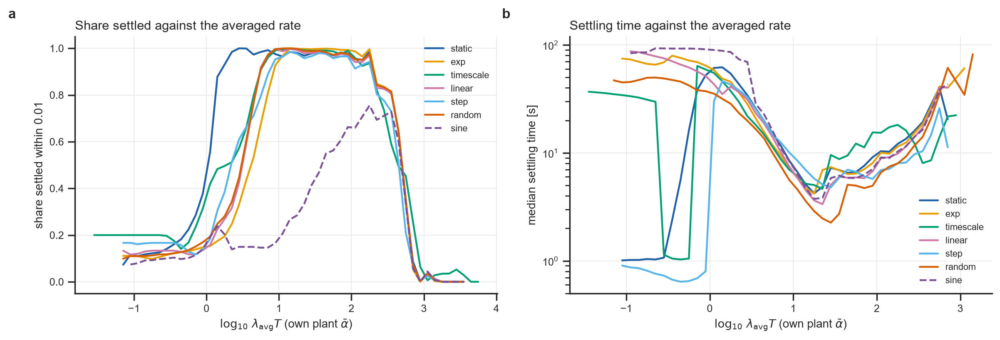

In [12]:
LB = np.arange(-2.0, 3.81, 0.1)
x_all = np.log10(pairs_h.lamT)
rows = []
for fam in FAMILIES:
    d = pairs_h[pairs_h.family == fam]
    lo, hi = crossings(np.log10(d.lamT), d['settled_0.01'], LB)
    inside = d[(d.lam > esc.LAM_WINDOW[0]) & (d.lam < esc.LAM_WINDOW[1])]
    rows.append({'family': fam, 'lower 50 % edge, lamT': round(10**lo, 2), 'upper 50 % edge, lamT': round(10**hi, 0),
                 'settled inside 0.1 < lam_avg < 3 1/s': f'{inside["settled_0.01"].mean():.1%}'})
print(pd.DataFrame(rows).to_string(index=False))


def p_curve_settled(ax):
    for fam in FAMILIES:
        d = pairs_h[pairs_h.family == fam]
        share_curve(ax, np.log10(d.lamT), d['settled_0.01'], LB, color=FAM_COLOR[fam], label=fam,
                    ls='--' if fam == 'sine' else '-')
    ax.set_xlabel(r'$\log_{10}\,\lambda_\mathrm{avg} T$ (own plant $\bar\alpha$)'); ax.set_ylabel('share settled within 0.01')
    ax.legend(fontsize=8)


def p_curve_time(ax):
    for fam in FAMILIES:
        d = pairs_h[(pairs_h.family == fam) & pairs_h['settled_0.01']]
        x = np.log10(d.lamT); idx = np.digitize(x, LB)
        med = d.groupby(idx)['t_0.01'].median(); cnt = d.groupby(idx).size()
        med = med[cnt >= 30]
        ax.plot(0.5 * (LB[med.index - 1] + LB[med.index]), med.values, color=FAM_COLOR[fam], label=fam,
                ls='--' if fam == 'sine' else '-')
    ax.set_xlabel(r'$\log_{10}\,\lambda_\mathrm{avg} T$ (own plant $\bar\alpha$)'); ax.set_ylabel('median settling time [s]')
    ax.set_yscale('log'); ax.legend(fontsize=8)


panels_1e = [('Share settled against the averaged rate', p_curve_settled), ('Settling time against the averaged rate', p_curve_time)]
show(panels_1e, 2, size=(6.0, 4.2))

The same curves, one per figure.

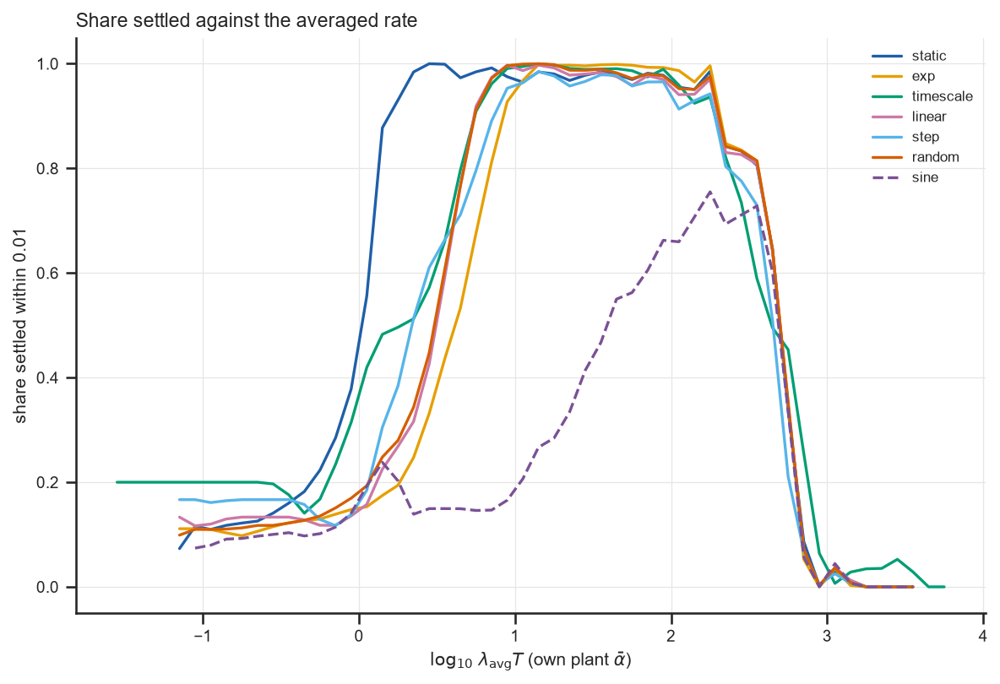

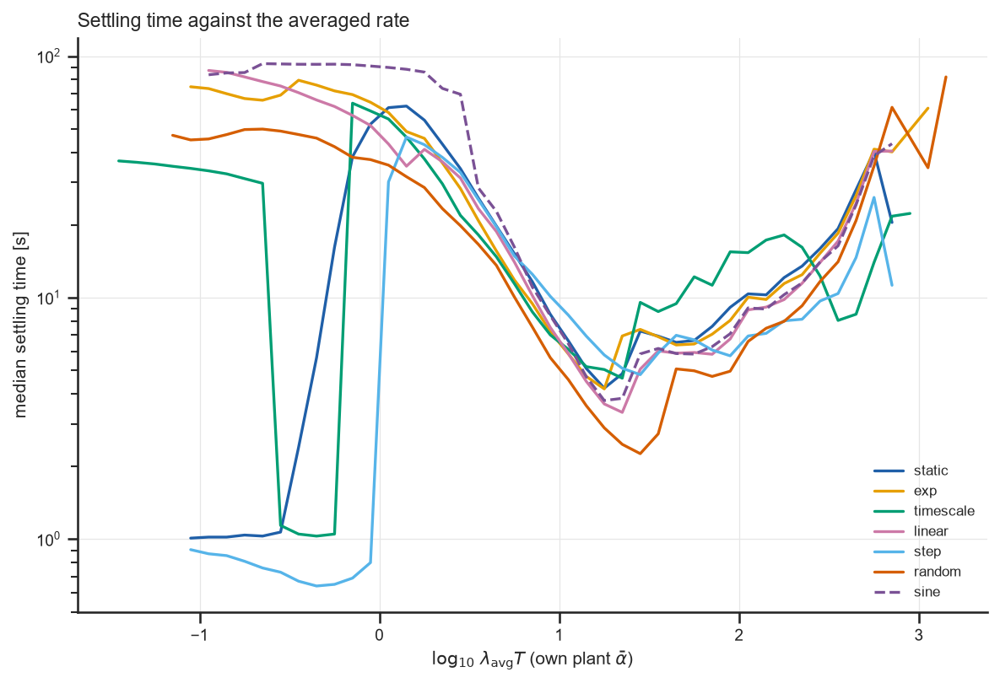

In [13]:
show_separate(panels_1e)

**What this shows.** Every non-sine family has its left (too slow) edge at a $\lambda_\mathrm{avg} T$ of order one to a few
(printed): static plants need the least, drifting plants somewhat more, because a slow ESC lags behind an ideal ratio
that keeps moving. The right (too fast: overshoot and instability) edge is at about the same $\lambda_\mathrm{avg} T$ for the
families with the nominal time scale but not for the timescale family; Section 3 shows which quantity fixes it. Inside the
averaged-ESC window almost all runs settle. Settling time falls with $\lambda_\mathrm{avg} T$ to a floor of a few seconds, then
rises again near the upper edge. Sine plants settle less at every rate: they need tracking, not just convergence. The floor of
about 10-20 % settled runs at very small $\lambda_\mathrm{avg} T$, with settling times of about a second, comes from plants whose
ideal ratio is already (or steps to) within 0.01 of 0.5: there the run counts as settled although the ESC has hardly
moved.

## 2. Energy (optimal) region

**What and why.** A safe ESC can still give away energy: it may converge late, or its dither may cost more than the plant
offers. For each set the energy score $\eta$ = gain / margin is computed on every non-sine plant whose margin is at least
the margin floor; the set is judged by its *worst* plant (an operator does not know the plant) and, for comparison, by
its median plant. The dither loss $L_\mathrm{dith}$ (nominal $\bar\alpha$) is the energy the dither itself costs over the run
on a perfectly converged ESC. The last map shows, among the sets that settle on every plant, how the worst $\eta$ depends
on $a$ and $f$, with contours of $L_\mathrm{dith}$.

eta is computed on 518 plants (not sine, margin >= 2)
quasi-random sets with worst-plant eta >= 0.9: 164 (8.2%), bootstrap range 164-205; with median eta >= 0.9: 971
  margin floor 1: 28 convergence plants left out, 137 sets with worst eta >= 0.9
  margin floor 2: 55 convergence plants left out, 164 sets with worst eta >= 0.9
  margin floor 5: 112 convergence plants left out, 166 sets with worst eta >= 0.9
plant group with the worst eta, per set: {'time x3': 858, 'time x0.5': 830, 'step': 142, 'random': 122, 'time x2': 38, 'exp': 6, 'linear': 3, 'static': 1}
sets that settle everywhere: 506; of these with worst eta >= 0.9: 156


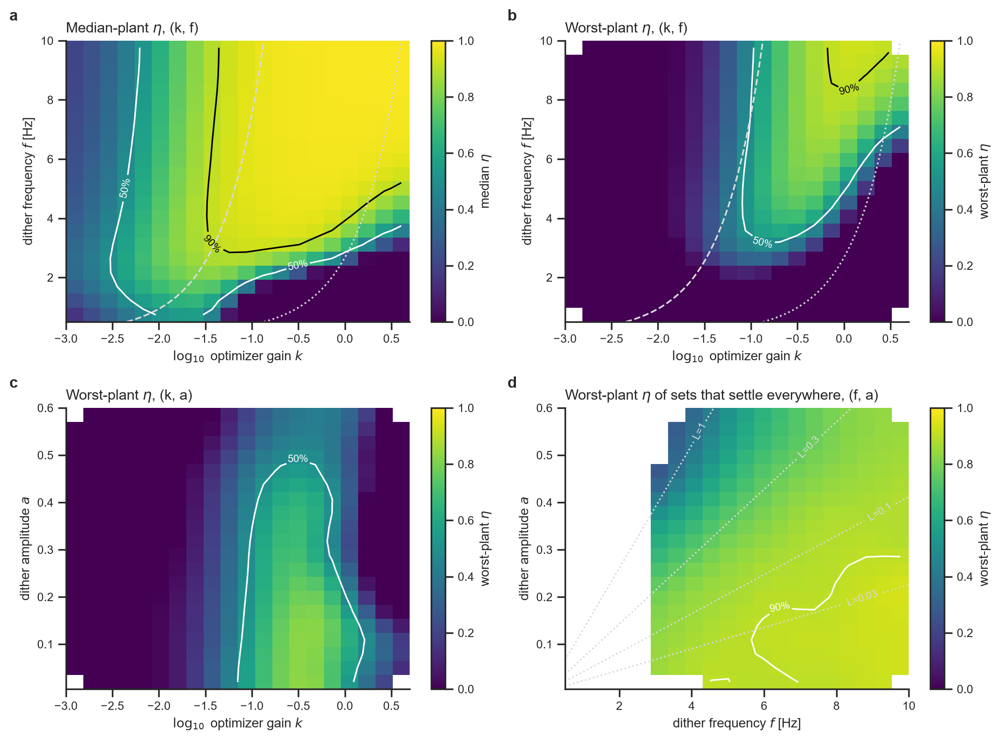

In [14]:
en = conv[conv.eta.notna()]
eta_tab = en.set_index(['set', 'plant'])['eta'].unstack()
per_set['eta_worst'] = eta_tab.min(axis=1)
per_set['eta_median'] = eta_tab.median(axis=1)
per_set['L_dith'] = esc.dither_loss(per_set.dither_amplitude, per_set.dither_frequency)
per_set['lamT'] = esc.lam_avg(per_set.optimizer_gain, per_set.dither_frequency) * T
per_set['rho'] = per_set.lamT / T / (2 * per_set.dither_frequency)
print(f'eta is computed on {eta_tab.shape[1]} plants (not sine, margin >= {MARGIN_FLOOR:g})')
n_eta, ci_eta = boot_pass(eta_tab < ETA_MIN)
print(f'quasi-random sets with worst-plant eta >= {ETA_MIN}: {n_eta} ({n_eta / len(per_set):.1%}), bootstrap range '
      f'{ci_eta[0]:.0f}-{ci_eta[1]:.0f}; with median eta >= {ETA_MIN}: {(per_set.eta_median >= ETA_MIN).sum()}')
for floor in [1.0, 2.0, 5.0]:
    d = conv[conv.margin >= floor]
    w = (d.energy_gain / d.margin).groupby(d.set).min()
    print(f'  margin floor {floor:g}: {conv[conv.margin < floor].plant.nunique()} convergence plants left out, '
          f'{(w >= ETA_MIN).sum()} sets with worst eta >= {ETA_MIN}')
worst_eta_plant = en.loc[en.groupby('set').eta.idxmin()]
print('plant group with the worst eta, per set:', worst_eta_plant.group.value_counts().to_dict())
both_ok = per_set.settled_all & (per_set.eta_worst >= ETA_MIN)
print(f'sets that settle everywhere: {per_set.settled_all.sum()}; of these with worst eta >= {ETA_MIN}: {both_ok.sum()}')
per_set['eta_worst_clip'] = per_set.eta_worst.clip(-1, 1)
Z2 = {'med': bmap(per_set, 'kf', 'eta_median'), 'worst_kf': bmap(per_set, 'kf', 'eta_worst_clip', statistic='median'),
      'worst_ka': bmap(per_set, 'ka', 'eta_worst_clip', statistic='median'),
      'worst_fa': bmap(per_set[per_set.settled_all], 'fa', 'eta_worst_clip', statistic='median')}


def p_fa(ax):
    draw_map(ax, Z2['worst_fa'], 'fa', r'worst-plant $\eta$', levels=(ETA_MIN,))
    ff, aa = np.meshgrid(np.linspace(0.5, 10, 200), np.linspace(0.005, 0.6, 200))
    cs = ax.contour(ff, aa, esc.dither_loss(aa, ff), levels=[0.03, 0.1, 0.3, 1], colors='0.85', linestyles=':', linewidths=1.2)
    ax.clabel(cs, fmt=lambda v: f'L={v:g}', fontsize=8)


panels_2a = [('Median-plant $\\eta$, (k, f)', lambda ax: (draw_map(ax, Z2['med'], 'kf', r'median $\eta$', levels=(0.5, ETA_MIN)), lam_lines(ax))),
             ('Worst-plant $\\eta$, (k, f)', lambda ax: (draw_map(ax, Z2['worst_kf'], 'kf', r'worst-plant $\eta$', levels=(0.5, ETA_MIN)), lam_lines(ax))),
             ('Worst-plant $\\eta$, (k, a)', lambda ax: draw_map(ax, Z2['worst_ka'], 'ka', r'worst-plant $\eta$', levels=(0.5, ETA_MIN))),
             ('Worst-plant $\\eta$ of sets that settle everywhere, (f, a)', p_fa)]
show(panels_2a, 2)

The same maps, one per figure.

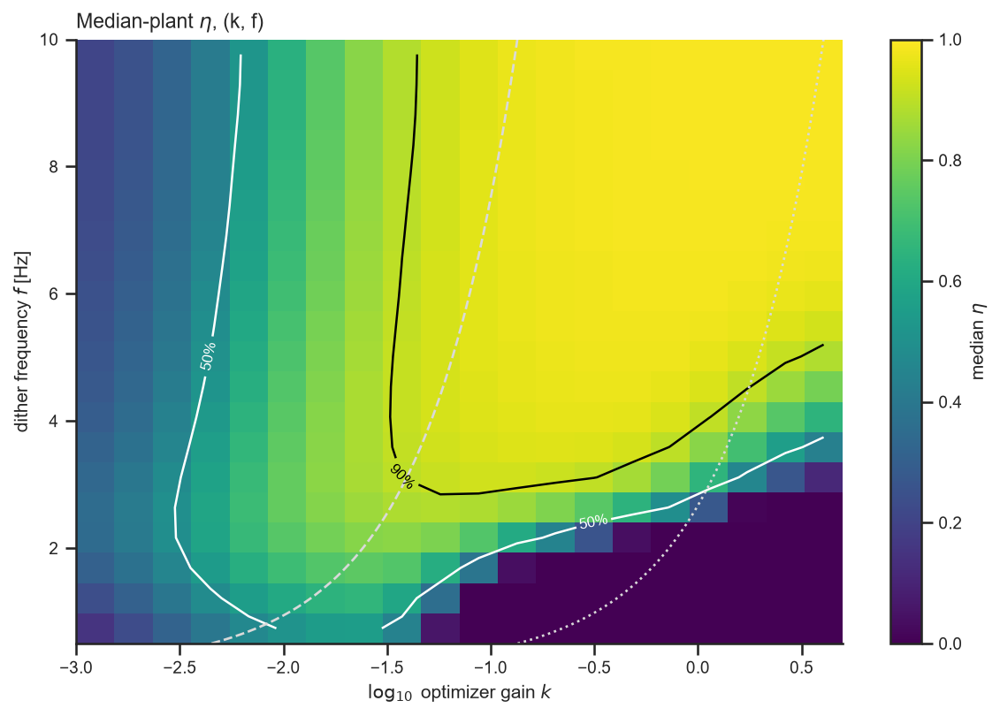

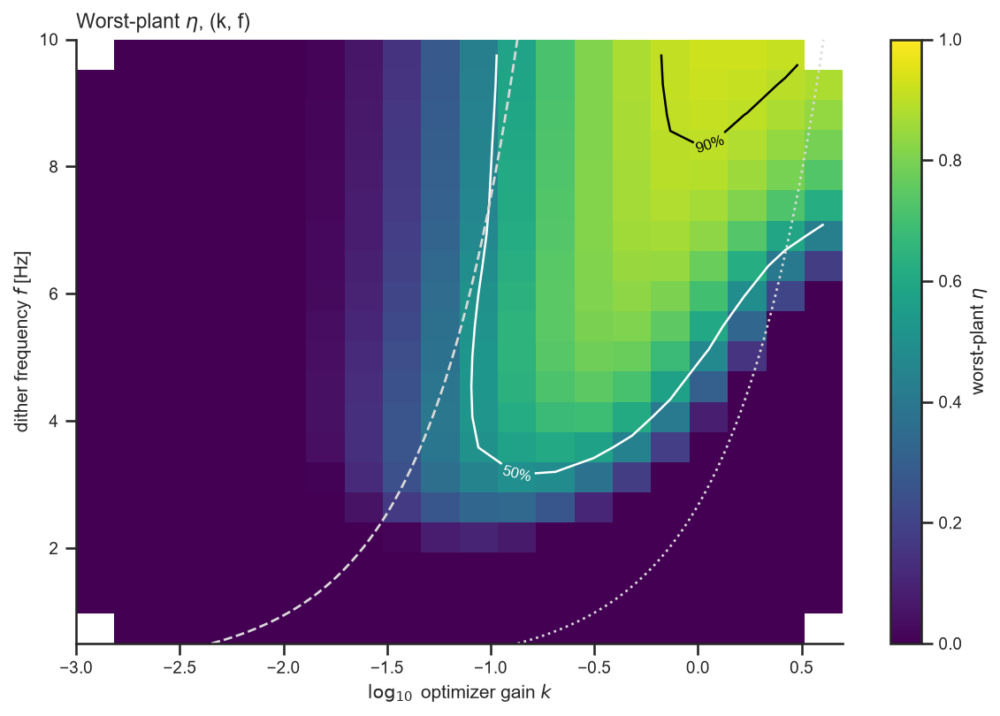

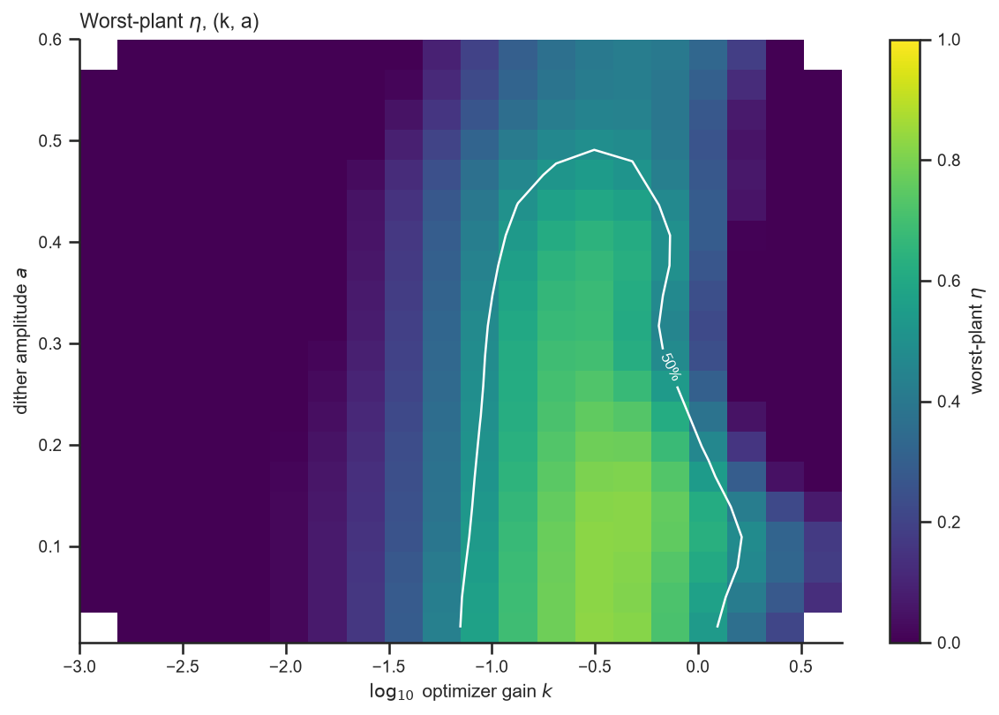

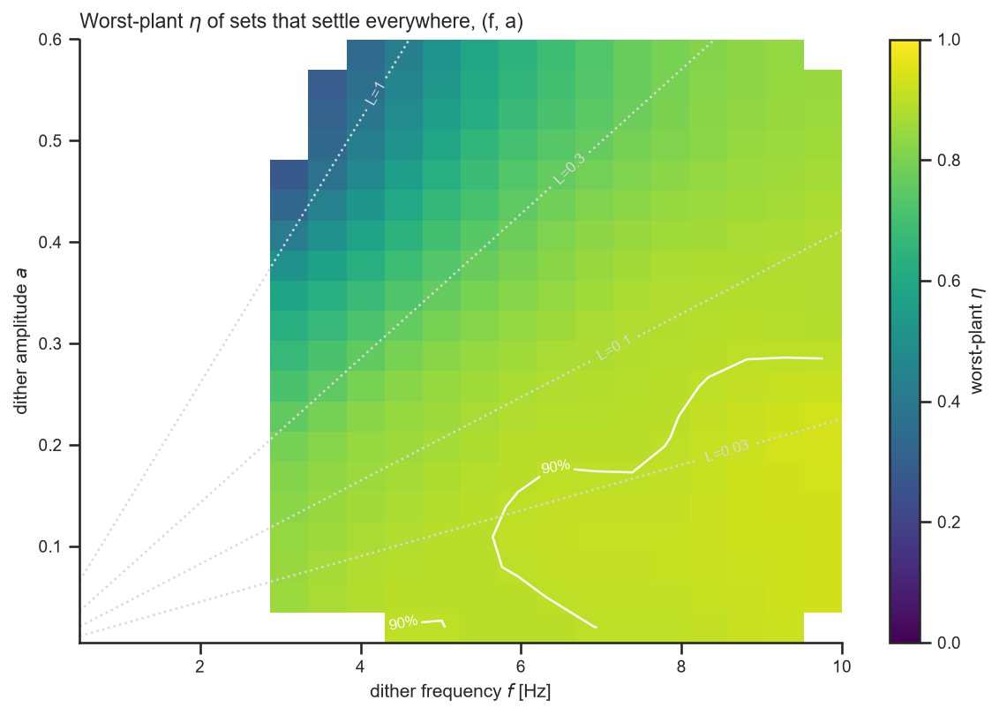

In [15]:
show_separate(panels_2a)

**What this shows.** The median plant is easy: most of the settling band collects nearly all of its margin. The worst
plant is much stricter. It is usually a slow or a fast plant of the timescale family (printed above), and it removes the
low-frequency part of the band and the largest gains. In the $(f, a)$ plane the worst $\eta$ falls where the dither loss is
large (large amplitude at low frequency), as the $L_\mathrm{dith}$ contours predict: the dither costs energy in
proportion to $a^2$ and less at high frequency, because the plasma then filters it out.

### 2.1 Recommended operating window

**What and why.** The window combines both criteria. A set is inside when
1. it settles within 0.01 on every convergence plant at the steady start,
2. it settles within 0.01 on every one of the 30 plants at *both* off-0.5 starts,
3. its worst settling time at the steady start is at most `T_MAX`, and
4. its worst-plant $\eta$ is at least `ETA_MIN`.

The energy score is not used for the off-0.5 starts: there the fixed ratio sits at 0.5 from the first second while ESC
has to travel 0.2, so $\eta$ against $r = 0.5$ mostly measures the start, not the controller.

The window is then described in two ways: as ranges of $(k, a, f)$ of the sets inside, and as a simple rule in normalised
terms ($\lambda_\mathrm{avg} T$, $\rho = \lambda_\mathrm{avg}/(2f)$, $L_\mathrm{dith}$, all with the nominal $\bar\alpha$, so the rule
can be used without knowing the plant). The rule's three limits are found by a search over a grid of round values that
maximises its overlap (Jaccard index) with the window.

In [16]:
off_settled = off[off.set >= 5].set_index(['set', 'plant', 'block'])['settled_0.01'].unstack('block')
fail_off = ~(off_settled['from0.3'] & off_settled['from0.7']).unstack('plant')
fail_time = (t_settle > T_MAX) | t_settle.isna()
fail_eta = (eta_tab < ETA_MIN).reindex(columns=t_settle.columns, fill_value=False)
per_set['settled_off'] = ~fail_off.any(axis=1)
per_set['t_worst_off'] = off[off.set >= 5].groupby('set')['t_0.01'].max()
per_set['window'] = per_set.settled_all & per_set.settled_off & (per_set.t_worst <= T_MAX) & (per_set.eta_worst >= ETA_MIN)
steps = [('settle on every convergence plant (steady)', per_set.settled_all),
         ('... and on every off-start plant, both starts', per_set.settled_all & per_set.settled_off),
         (f'... and worst settling time <= {T_MAX:g} s', per_set.settled_all & per_set.settled_off & (per_set.t_worst <= T_MAX)),
         (f'... and worst-plant eta >= {ETA_MIN}', per_set.window)]
for name, mask in steps:
    print(f'{name:48s}: {mask.sum():5d} of {len(per_set)} quasi-random sets ({mask.mean():.1%})')
n_win, ci_win = boot_pass(fail_settle | fail_time | fail_eta, fail_off)
print(f'window: {n_win} sets; bootstrap range {ci_win[0]:.0f}-{ci_win[1]:.0f} (plants resampled)')
for tmax in [20, 30, 40, np.inf]:
    for emin in [0.8, 0.9, 0.95]:
        m = per_set.settled_all & per_set.settled_off & (per_set.t_worst <= tmax) & (per_set.eta_worst >= emin)
        print(f'  T_MAX {tmax:>4g} s, ETA_MIN {emin}: {m.sum()} sets', end='\n' if emin == 0.95 else ';')

W = per_set[per_set.window]
cols = ['optimizer_gain', 'dither_amplitude', 'dither_frequency', 'lamT', 'rho', 'L_dith', 't_worst', 'eta_worst']
print('\nsets inside the window (quasi-random):')
print(W[cols].describe(percentiles=[0.05, 0.5, 0.95]).loc[['min', '5%', '50%', '95%', 'max']].round(3).to_string())

best = []
for lo in [10, 20, 30, 40, 50, 60, 80]:
    for hi in [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]:
        for lmax in [0.03, 0.05, 0.1, 0.15, 0.2, 0.3]:
            rule = (per_set.lamT >= lo) & (per_set.rho <= hi) & (per_set.L_dith <= lmax)
            tp = (rule & per_set.window).sum(); fp = (rule & ~per_set.window).sum(); fn = (~rule & per_set.window).sum()
            best.append((tp / (tp + fp + fn), lo, hi, lmax, tp, fp, fn))
J_RULE, LAMT_MIN, RHO_MAX, LDITH_MAX, tp, fp, fn = max(best)
per_set['rule'] = (per_set.lamT >= LAMT_MIN) & (per_set.rho <= RHO_MAX) & (per_set.L_dith <= LDITH_MAX)
print(f'\nbest simple rule: lam_avg T >= {LAMT_MIN}, lam_avg/(2f) <= {RHO_MAX}, L_dith <= {LDITH_MAX} energy units')
print(f'  Jaccard with the window {J_RULE:.2f}: {tp} window sets inside the rule, {fn} window sets outside it, '
      f'{fp} rule sets that fail the window ({per_set.rule.sum()} sets satisfy the rule)')
why = per_set[per_set.rule & ~per_set.window]
print(f'  why those {len(why)} fail: not settled everywhere {(~why.settled_all).sum()}, not settled from 0.3/0.7 '
      f'{(~why.settled_off).sum()}, worst time > {T_MAX:g} s {(why.t_worst > T_MAX).sum()}, worst eta < {ETA_MIN} {(why.eta_worst < ETA_MIN).sum()}')
print(f'  in plant terms: lam_avg = {LAMT_MIN / T:g} 1/s, i.e. the ESC time constant 1/lam_avg <= {T / LAMT_MIN:g} s; '
      f'ESC at most {RHO_MAX:.0%} as fast as its filters; dither loss <= {LDITH_MAX / esc.E_MAX:.4%} of the maximum energy '
      f'(= {LDITH_MAX / MARGIN_FLOOR:.0%} of the margin floor)')

settle on every convergence plant (steady)      :   506 of 2000 quasi-random sets (25.3%)
... and on every off-start plant, both starts   :   502 of 2000 quasi-random sets (25.1%)
... and worst settling time <= 30 s             :   410 of 2000 quasi-random sets (20.5%)
... and worst-plant eta >= 0.9                  :   142 of 2000 quasi-random sets (7.1%)
window: 142 sets; bootstrap range 142-187 (plants resampled)
  T_MAX   20 s, ETA_MIN 0.8: 81 sets;  T_MAX   20 s, ETA_MIN 0.9: 44 sets;  T_MAX   20 s, ETA_MIN 0.95: 8 sets
  T_MAX   30 s, ETA_MIN 0.8: 301 sets;  T_MAX   30 s, ETA_MIN 0.9: 142 sets;  T_MAX   30 s, ETA_MIN 0.95: 48 sets
  T_MAX   40 s, ETA_MIN 0.8: 322 sets;  T_MAX   40 s, ETA_MIN 0.9: 153 sets;  T_MAX   40 s, ETA_MIN 0.95: 53 sets
  T_MAX  inf s, ETA_MIN 0.8: 326 sets;  T_MAX  inf s, ETA_MIN 0.9: 153 sets;  T_MAX  inf s, ETA_MIN 0.95: 53 sets

sets inside the window (quasi-random):
     optimizer_gain  dither_amplitude  dither_frequency     lamT    rho  L_dith  t_wors

Where the five chosen sets lie. They are not part of the quasi-random sample, so their criteria are computed here in the
same way.

In [17]:
def set_summary(ids):
    d = pairs[pairs.set.isin(ids) & (pairs.family != 'sine')]
    o = off[off.set.isin(ids)]
    e = d[d.eta.notna()]
    s = sets.set_index('set').loc[ids, ['chosen', *esc.ESC_PARAMS]].copy()
    s['settled_all'] = d.groupby('set')['settled_0.01'].all()
    s['settled_off'] = o.groupby('set')['settled_0.01'].all()
    s['t_worst'] = d.groupby('set')['t_0.01'].max().where(s.settled_all)
    s['t_worst_off'] = o.groupby('set')['t_0.01'].max().where(s.settled_off)
    s['eta_worst'] = e.groupby('set').eta.min()
    s['eta_median'] = e.groupby('set').eta.median()
    s['lamT'] = esc.lam_avg(s.optimizer_gain, s.dither_frequency) * T
    s['rho'] = s.lamT / T / (2 * s.dither_frequency)
    s['L_dith'] = esc.dither_loss(s.dither_amplitude, s.dither_frequency)
    s['window'] = s.settled_all & s.settled_off & (s.t_worst <= T_MAX) & (s.eta_worst >= ETA_MIN)
    s['rule'] = (s.lamT >= LAMT_MIN) & (s.rho <= RHO_MAX) & (s.L_dith <= LDITH_MAX)
    return s


chosen = set_summary([0, 1, 2, 3, 4])
print(chosen.round({'t_worst': 1, 't_worst_off': 1, 'eta_worst': 3, 'eta_median': 3, 'lamT': 1, 'rho': 3, 'L_dith': 4}).to_string())
print('\nplant group with the worst eta for each chosen set:',
      pairs[pairs.set.isin(range(5)) & (pairs.family != 'sine') & pairs.eta.notna()]
      .pipe(lambda d: d.loc[d.groupby('set').eta.idxmin()]).set_index('set').group.to_dict())

                 chosen  optimizer_gain  dither_amplitude  dither_frequency  settled_all  settled_off  t_worst  t_worst_off  eta_worst  eta_median   lamT    rho  L_dith  window   rule
set                                                                                                                                                                                    
0             reference          1.0000            0.2000              6.00         True         True     25.3         42.6      0.934       0.992  126.3  0.105  0.0656    True   True
1               fastest          0.2550            0.0517              8.41         True         True     24.8         29.2      0.834       0.991   22.7  0.013  0.0022   False  False
2       fastest a>=0.15          0.2650            0.1920              9.09         True         True     24.8         28.9      0.831       0.989   21.7  0.012  0.0263   False  False
3          fastest f<=3          0.0982            0.0556              2.97     

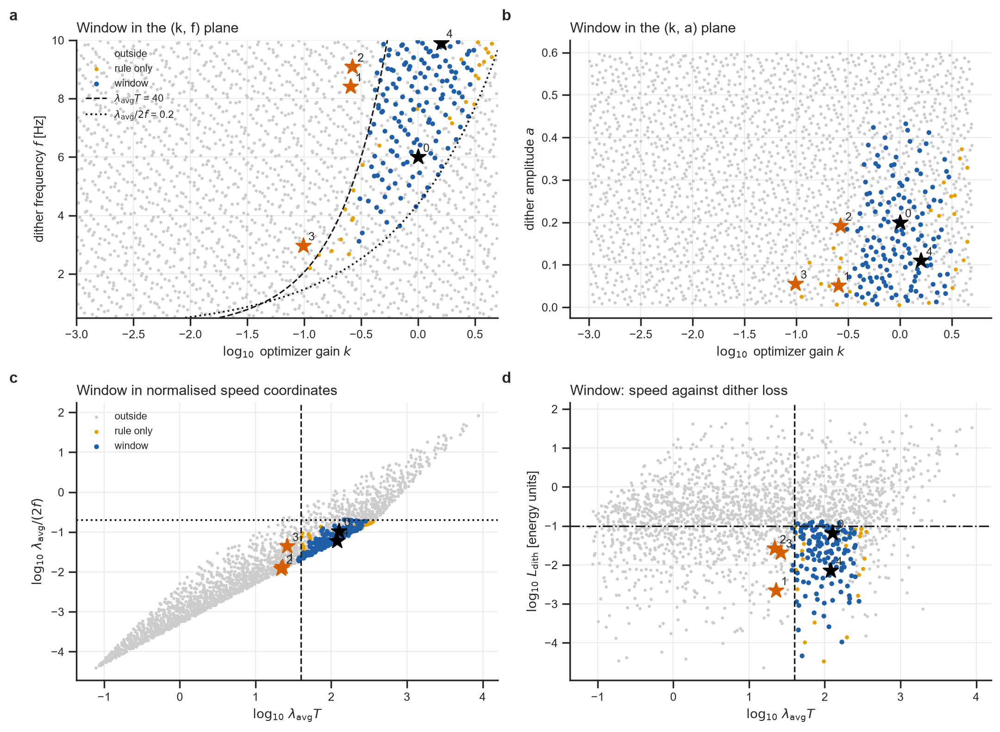

In [18]:
PS = per_set.assign(c=np.where(per_set.window, 'window', np.where(per_set.rule, 'rule only', 'outside')))
for d in (PS, chosen):
    d['log10_gain'] = np.log10(d.optimizer_gain); d['x'] = np.log10(d.lamT); d['y'] = np.log10(d.rho); d['yl'] = np.log10(d.L_dith)
STYLE = {'outside': dict(color='0.8', s=6, label='outside'), 'rule only': dict(color=esc.COLORS['fixed'], s=10, label='rule only'),
         'window': dict(color=esc.COLORS['esc'], s=14, label='window')}


def scatter_sets(ax, x, y):
    for c, kw in STYLE.items():
        d = PS[PS.c == c]
        ax.scatter(d[x], d[y], lw=0, **kw)
    for i, r in chosen.iterrows():
        ax.scatter(r[x], r[y], marker='*', s=150, color='black' if r.window else esc.COLORS['bad'], zorder=5)
        ax.annotate(str(i), (r[x], r[y]), xytext=(4, 4), textcoords='offset points', fontsize=9)


def p_win_kf(ax):
    scatter_sets(ax, 'log10_gain', 'dither_frequency')
    ax.plot(np.log10(k_for(F_LINE, lam=LAMT_MIN / T)), F_LINE, 'k--', lw=1.2, label=rf'$\lambda_\mathrm{{avg}}T$ = {LAMT_MIN}')
    ax.plot(np.log10(k_for(F_LINE, rho=RHO_MAX)), F_LINE, 'k:', lw=1.4, label=rf'$\lambda_\mathrm{{avg}}/2f$ = {RHO_MAX}')
    ax.set_xlim(EDGES['log10_gain'][[0, -1]]); ax.set_ylim(0.5, 10)
    ax.set_xlabel(esc.label('log10_gain')); ax.set_ylabel(esc.label('dither_frequency')); ax.legend(fontsize=8, loc='upper left')


def p_win_ka(ax):
    scatter_sets(ax, 'log10_gain', 'dither_amplitude')
    ax.set_xlabel(esc.label('log10_gain')); ax.set_ylabel(esc.label('dither_amplitude'))


def p_win_norm(ax):
    scatter_sets(ax, 'x', 'y')
    ax.axvline(np.log10(LAMT_MIN), color='k', ls='--', lw=1.2); ax.axhline(np.log10(RHO_MAX), color='k', ls=':', lw=1.4)
    ax.set_xlabel(r'$\log_{10}\,\lambda_\mathrm{avg} T$'); ax.set_ylabel(r'$\log_{10}\,\lambda_\mathrm{avg}/(2f)$'); ax.legend(fontsize=8, loc='upper left')


def p_win_ldith(ax):
    scatter_sets(ax, 'x', 'yl')
    ax.axvline(np.log10(LAMT_MIN), color='k', ls='--', lw=1.2); ax.axhline(np.log10(LDITH_MAX), color='k', ls='-.', lw=1.2)
    ax.set_xlabel(r'$\log_{10}\,\lambda_\mathrm{avg} T$'); ax.set_ylabel(r'$\log_{10}\,L_\mathrm{dith}$ [energy units]')


panels_2b = [('Window in the (k, f) plane', p_win_kf), ('Window in the (k, a) plane', p_win_ka),
             ('Window in normalised speed coordinates', p_win_norm), ('Window: speed against dither loss', p_win_ldith)]
show(panels_2b, 2)

The same plots, one per figure. Stars are the five chosen sets (black: inside the window, red: outside), numbered by set.

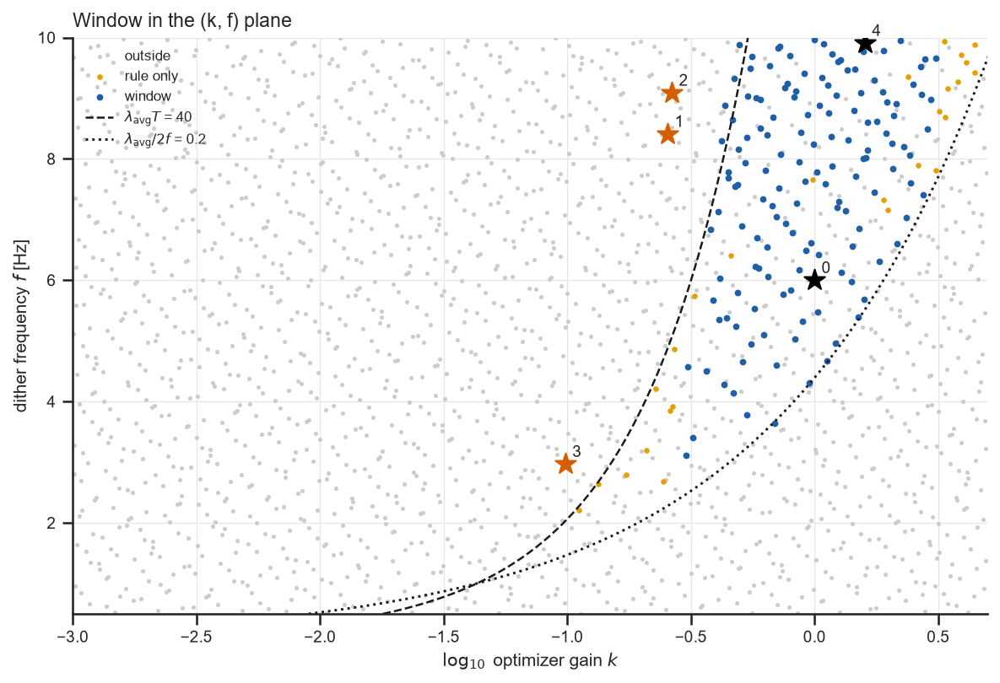

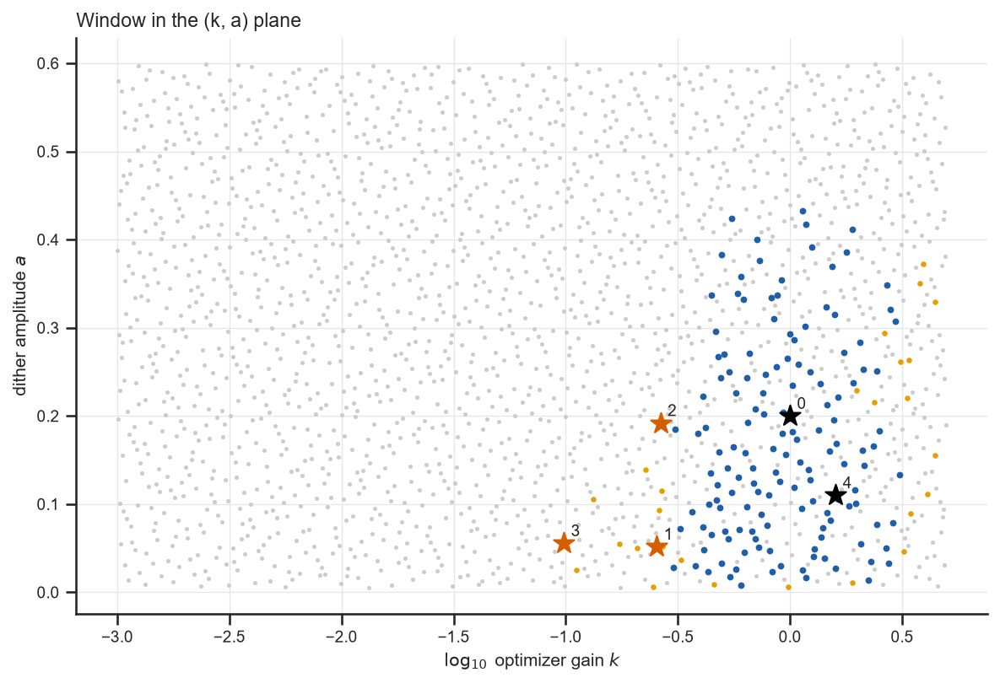

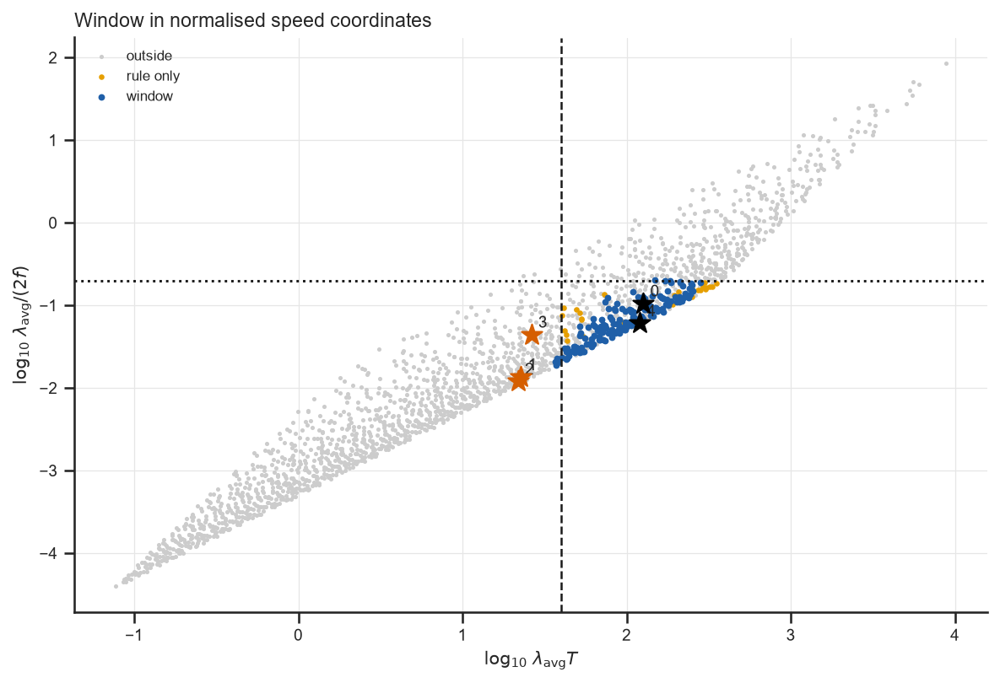

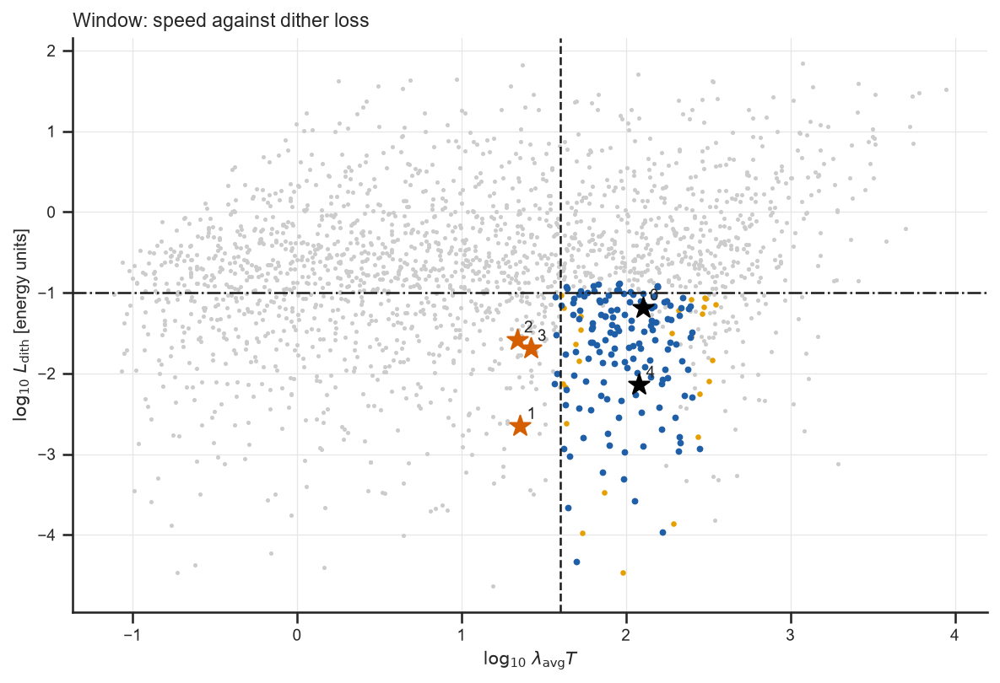

In [19]:
show_separate(panels_2b)

**Sine plants with the window sets.** How well do the window sets track an ideal ratio that oscillates? Share of runs
that stay within 0.01 and median $\eta$, by sine amplitude and period.

In [20]:
sine_w = pairs[(pairs.family == 'sine') & pairs.set.isin(W.index)]
print(f'{sine_w.plant.nunique()} sine plants x {len(W)} window sets')
print('share settled (tracks within 0.01 to the end), rows = sine amplitude, columns = period [s]:')
print(sine_w.pivot_table(index='drift_size', columns='drift_time', values='settled_0.01', aggfunc='mean').round(2).to_string())
print('median eta (plants with margin >= floor):')
print(sine_w.pivot_table(index='drift_size', columns='drift_time', values='eta', aggfunc='median').round(2).to_string())

27 sine plants x 142 window sets
share settled (tracks within 0.01 to the end), rows = sine amplitude, columns = period [s]:
drift_time   10    30   100
drift_size                 
0.01        0.57  1.00  1.0
0.03        0.13  1.00  1.0
0.06        0.00  0.91  1.0
median eta (plants with margin >= floor):
drift_time   10    30    100
drift_size                  
0.01        0.98  0.99  0.99
0.03        0.84  0.99  0.99
0.06        0.68  0.98  1.00


**What this shows.** The window is a compact block: moderate to large gains, dither frequencies of a few hertz and
above, and small to moderate amplitudes (ranges printed above). In normalised terms it needs three things, which the
simple rule captures: the ESC must be fast enough to finish within the run ($\lambda_\mathrm{avg} T$ above a minimum), slow
compared with its own filters ($\lambda_\mathrm{avg}/(2f)$ below a maximum), and the dither must be cheap ($L_\mathrm{dith}$ below
a small fraction of the smallest margin that is counted). The rule is not exact (the printed Jaccard index): it
misses sets at the edges, where one slow or fast plant decides. Of the five chosen sets, only those printed as inside
pass all four criteria; the others fail mainly on the worst-plant $\eta$, on a slow plant of the timescale family (see
the printed worst groups): they converge fast on nominal plants but are too slow on plants three times slower. On sine
plants the window sets follow oscillations with periods of 30 s and more; a 10 s period cannot be followed within 0.01
and costs energy at larger amplitudes, whatever the setting.

## 3. Does the region depend on the plant?

**What and why.** If the good region were the same for every plant, one tuning would fit all. The plants are split into
eight groups: five families (static, exp, linear, step, random) and the timescale family split by its confinement-time
factor ($\times 0.5$, $\times 2$, $\times 3$), because these are plants that react faster or slower. Sine plants are left out
(tracking, Section 1.2). For each group a set is *good* when it settles within 0.01 on every plant of the group and its
worst $\eta$ in the group is at least `ETA_MIN`. No time limit is used here, because a settling time in seconds is
expected to scale with the plant's own time constant (checked below).

Four tests:
1. Overlap of the good sets of the groups: the Jaccard index (sets good in both / sets good in either) for each pair of
   groups, and the share of sets that all groups classify the same way.
2. Do normalised coordinates collapse the groups? Where does the share of settled runs cross 50 % (lower and upper
   edge) in raw $\log_{10} k$, in $\lambda_\mathrm{avg} T$ with the nominal $\bar\alpha$, in $\lambda_\mathrm{avg} T$ with the
   group's own $\bar\alpha$, and in $\rho = \lambda_\mathrm{avg}/(2f)$ with the group's own $\bar\alpha$? A coordinate collapses the
   groups when the edges of all groups fall at the same value (small spread).
3. The same for energy: the share of well-tuned runs with $\eta \ge$ `ETA_MIN` against the raw dither loss
   $L_\mathrm{dith}$ and against $L_\mathrm{dith}$/margin.
4. One rule for all groups, written once in raw and once in normalised coordinates: which describes every group's good
   sets better? And do the group regions overlap better in a normalised plane than in the raw one?

In [21]:
grp = conv
good = {}
for g in GROUPS:
    d = grp[grp.group == g]
    ok = d.groupby('set')['settled_0.01'].all()
    e = d[d.eta.notna()].groupby('set').eta.min().reindex(ok.index)
    good[g] = ok & ~(e < ETA_MIN)
good = pd.DataFrame(good)
print('plants per group:', grp.drop_duplicates('plant').group.value_counts().reindex(GROUPS).to_dict())
print('good sets per group:', good.sum().to_dict())
J = pd.DataFrame({g: [(good[g] & good[h]).sum() / max((good[g] | good[h]).sum(), 1) for h in GROUPS] for g in GROUPS}, index=GROUPS)
off_diag = J.values[~np.eye(len(GROUPS), dtype=bool)]
print(f'Jaccard index between groups: median {np.median(off_diag):.2f}, range {off_diag.min():.2f}-{off_diag.max():.2f}')
fam5 = GROUPS[:5]
J5 = J.loc[fam5, fam5].values[~np.eye(5, dtype=bool)]
print(f'  among the five families with the nominal time scale: median {np.median(J5):.2f}, range {J5.min():.2f}-{J5.max():.2f}')
agree_all = (good.all(axis=1) | ~good.any(axis=1)).mean()
agree5 = (good[fam5].all(axis=1) | ~good[fam5].any(axis=1)).mean()
print(f'sets classified the same by all 8 groups: {agree_all:.1%}; by the 5 nominal families: {agree5:.1%}')
print(f'good on every group: {good.all(axis=1).sum()}; good on at least one: {good.any(axis=1).sum()}')
lo_pair = J.where(~np.eye(len(GROUPS), dtype=bool)).stack().idxmin()
print(f'least similar pair: {lo_pair} (Jaccard {J.loc[lo_pair]:.2f})')

# settling time in plant time units, for sets good on every group
ga = good.index[good.all(axis=1)]
d = grp[grp.set.isin(ga)]
tt = d.groupby(['set', 'group'])['t_0.01'].max().unstack()[GROUPS]
ab = grp.groupby('group').alpha_bar.first()[GROUPS]
print('worst settling time of sets good everywhere, median over sets [s]:', tt.median().round(1).to_dict())
print('the same times alpha_bar (plant time units):', (tt * ab).median().round(1).to_dict())

plants per group: {'static': 41, 'exp': 72, 'linear': 30, 'step': 36, 'random': 364, 'time x0.5': 10, 'time x2': 10, 'time x3': 10}
good sets per group: {'static': 572, 'exp': 430, 'linear': 327, 'step': 238, 'random': 274, 'time x0.5': 315, 'time x2': 514, 'time x3': 456}
Jaccard index between groups: median 0.53, range 0.27-0.83
  among the five families with the nominal time scale: median 0.64, range 0.41-0.83
sets classified the same by all 8 groups: 69.6%; by the 5 nominal families: 80.5%
good on every group: 156; good on at least one: 764
least similar pair: ('time x0.5', 'time x3') (Jaccard 0.27)
worst settling time of sets good everywhere, median over sets [s]: {'static': 12.2, 'exp': 11.3, 'linear': 10.0, 'step': 7.6, 'random': 8.9, 'time x0.5': 5.5, 'time x2': 15.3, 'time x3': 22.1}
the same times alpha_bar (plant time units): {'static': 7.2, 'exp': 6.7, 'linear': 5.9, 'step': 4.5, 'random': 5.3, 'time x0.5': 6.6, 'time x2': 4.5, 'time x3': 4.4}


In [22]:
coords = {'log10 k': lambda d: np.log10(d.optimizer_gain),
          'log10 lamT, nominal abar': lambda d: np.log10(esc.lam_avg(d.optimizer_gain, d.dither_frequency) * T),
          'log10 lamT, own abar': lambda d: np.log10(d.lamT),
          'log10 rho, own abar': lambda d: np.log10(d.rho)}
CB = {'log10 k': np.arange(-3, 0.71, 0.1), 'log10 lamT, nominal abar': np.arange(-2, 3.81, 0.1),
      'log10 lamT, own abar': np.arange(-2, 3.81, 0.1), 'log10 rho, own abar': np.arange(-6, 1.01, 0.1)}
edge_rows = []
for g in GROUPS:
    d = grp[grp.group == g]
    row = {'group': g}
    for name, fn in coords.items():
        lo, hi = crossings(np.asarray(fn(d)), d['settled_0.01'].values, CB[name])
        row[(name, 'lower')] = lo; row[(name, 'upper')] = hi
    edge_rows.append(row)
edges = pd.DataFrame(edge_rows).set_index('group')
edges.columns = pd.MultiIndex.from_tuples(edges.columns)
print('50 % crossings of the share settled (log10 of the coordinate):')
print(edges.round(2).to_string())
spread = (edges.max() - edges.min()).unstack()
print('\nspread over the groups [decades] (max - min; NaN edges are ignored):')
print(spread.round(2).to_string())
print('upper edge in rho, own abar, as a plain number:', (10 ** edges[('log10 rho, own abar', 'upper')]).round(2).to_dict())
TS = ['time x0.5', 'time x2', 'time x3']
for name, gs in [('three time-scale groups', TS), ('five nominal families', GROUPS[:5])]:
    sp = (edges.loc[gs].max() - edges.loc[gs].min()).unstack()
    print(f'spread among the {name}: lower edge {sp.loc["log10 k", "lower"]:.2f} decades in k, '
          f'{sp.loc["log10 lamT, nominal abar", "lower"]:.2f} in lamT (nominal), {sp.loc["log10 lamT, own abar", "lower"]:.2f} in lamT (own abar); '
          f'upper edge {sp.loc["log10 lamT, own abar", "upper"]:.2f} in lamT (own), {sp.loc["log10 rho, own abar", "upper"]:.2f} in rho')

50 % crossings of the share settled (log10 of the coordinate):
          log10 k       log10 lamT, nominal abar       log10 lamT, own abar       log10 rho, own abar      
            lower upper                    lower upper                lower upper               lower upper
group                                                                                                      
static      -2.23  0.61                     0.02  2.70                 0.02  2.70               -3.12 -0.14
exp         -1.64  0.61                     0.62  2.70                 0.62  2.70               -2.45 -0.15
linear      -1.75  0.62                     0.49  2.70                 0.49  2.70               -2.57 -0.15
step        -1.87  0.58                     0.34  2.65                 0.34  2.65               -2.67 -0.23
random      -1.81  0.62                     0.48  2.70                 0.48  2.70               -2.58 -0.15
time x0.5   -2.38  0.37                    -0.10  2.46                 0.

In [23]:
# energy: eta >= ETA_MIN against the raw and the normalised dither loss, for well-tuned runs
tuned = conv[conv.eta.notna() & (conv.lamT >= LAMT_MIN) & (conv.rho <= RHO_MAX) & conv['settled_0.01']]
tuned = tuned.assign(ok=tuned.eta >= ETA_MIN, xr=np.log10(tuned.L_dith), xn=np.log10(tuned.L_dith / tuned.margin))
EB_raw, EB_norm = np.arange(-5, 1.51, 0.1), np.arange(-7, 0.51, 0.1)
rows = []
for g in GROUPS:
    d = tuned[tuned.group == g]
    _, hr = crossings(d.xr.values, d.ok.values, EB_raw); _, hn = crossings(d.xn.values, d.ok.values, EB_norm)
    rows.append({'group': g, 'runs': len(d), 'L_dith where share(eta >= ETA_MIN) = 50 %': 10**hr,
                 'L_dith/margin where share = 50 %': 10**hn})
e_edges = pd.DataFrame(rows).set_index('group')
print(f'well-tuned runs (settled, lamT >= {LAMT_MIN}, rho <= {RHO_MAX}, margin >= floor): {len(tuned):,}')
print(e_edges.round(3).to_string())
lr = np.log10(e_edges.iloc[:, 1]); ln = np.log10(e_edges.iloc[:, 2])
print(f'spread over the groups: raw L_dith {lr.max() - lr.min():.2f} decades, L_dith/margin {ln.max() - ln.min():.2f} decades')

well-tuned runs (settled, lamT >= 40, rho <= 0.2, margin >= floor): 175,054
             runs  L_dith where share(eta >= ETA_MIN) = 50 %  L_dith/margin where share = 50 %
group                                                                                         
static      12211                                        NaN                             0.090
exp         22496                                      1.479                             0.080
linear       9478                                      1.884                             0.081
step        12201                                      1.088                             0.074
random     110272                                      1.617                             0.091
time x0.5    3086                                      0.823                             0.085
time x2      2817                                        NaN                               NaN
time x3      2493                                        NaN         

**One rule for all groups.** If normalised coordinates remove the plant dependence, a single rule written in them should
describe the good sets of every group equally well. The rule has the form of Section 2: $\lambda_\mathrm{avg} T \ge A$,
$\rho \le B$ and a dither-loss limit $\le C$. In the *normalised* version, $\lambda_\mathrm{avg} T$ and $\rho$ use the group's own
$\bar\alpha$ and the dither limit is $L_\mathrm{dith}$ (own $\bar\alpha$) divided by the group's smallest margin above the floor.
In the *raw* version all three use the nominal plant and $L_\mathrm{dith}$ in energy units, i.e. what can be computed without
knowing the plant. For each version, $(A, B, C)$ is searched on a grid to maximise the mean Jaccard index over the eight
groups; the per-group Jaccard index then shows how well one rule fits each group.

The contour plots show the same in two dimensions: the 50 % contour of each group's share of good sets, over the raw
$(k, f)$ plane and over the normalised $(\lambda_\mathrm{avg} T, f)$ plane (own $\bar\alpha$; $\rho$ is then a straight line). To
keep the third coordinate out of a two-dimensional plot, only sets whose dither is cheap by the corresponding rule are
used. The overlap of the gridded regions (Jaccard index of the cells inside, over cells sampled by every group) measures
how well each plane lines the groups up.

In [24]:
import itertools
S_g = sets[halton].set_index('set')
feat, m_min = {}, {}
for g in GROUPS:
    d = grp[grp.group == g]
    abar = esc.ALPHA_BAR / d.tau_scale.iloc[0]
    m_min[g] = d.loc[d.margin >= MARGIN_FLOOR, 'margin'].min()
    lamT_g = esc.lam_avg(S_g.optimizer_gain, S_g.dither_frequency, abar) * T
    feat[g] = pd.DataFrame({'lamT': lamT_g, 'rho': lamT_g / T / (2 * S_g.dither_frequency),
                            'Lr': esc.dither_loss(S_g.dither_amplitude, S_g.dither_frequency, abar) / m_min[g]}, index=S_g.index)
print('smallest margin >= floor per group:', {g: round(float(v), 2) for g, v in m_min.items()})


def jac(p, t):
    return (p & t).sum() / max((p | t).sum(), 1)


grid_A, grid_B = [5, 10, 20, 30, 40, 60, 80], [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
res_n = [(np.mean(js := [jac((feat[g].lamT >= A) & (feat[g].rho <= B) & (feat[g].Lr <= C), good[g]) for g in GROUPS]), A, B, C, js)
         for A, B, C in itertools.product(grid_A, grid_B, [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.1, 0.15])]
res_r = [(np.mean(js := [jac((per_set.lamT >= A) & (per_set.rho <= B) & (per_set.L_dith <= C), good[g]) for g in GROUPS]), A, B, C, js)
         for A, B, C in itertools.product(grid_A, grid_B, [0.03, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 1.0])]
bn, br = max(res_n, key=lambda r: r[0]), max(res_r, key=lambda r: r[0])
rule_tab = pd.DataFrame({'normalised rule': bn[4], 'raw rule': br[4]}, index=GROUPS)
print(f'best normalised rule: own lamT >= {bn[1]}, own rho <= {bn[2]}, L_dith/smallest margin <= {bn[3]}; mean Jaccard {bn[0]:.2f}')
print(f'best raw rule:        nominal lamT >= {br[1]}, nominal rho <= {br[2]}, L_dith <= {br[3]} energy units; mean Jaccard {br[0]:.2f}')
print('Jaccard index of each rule with the good sets of each group:')
print(rule_tab.round(2).T.to_string())
print(f'time-scale groups: normalised {rule_tab.loc[TS, "normalised rule"].min():.2f}-{rule_tab.loc[TS, "normalised rule"].max():.2f}, '
      f'raw {rule_tab.loc[TS, "raw rule"].min():.2f}-{rule_tab.loc[TS, "raw rule"].max():.2f}')

NX = np.linspace(-2.5, 3.8, NB + 1)
zr, zn, reg_raw, reg_norm, support = {}, {}, {}, {}, {}
cheap_raw = per_set.L_dith <= br[3]
for g in GROUPS:
    F = feat[g]; cheap = F.Lr <= bn[3]
    zr[g] = esc.binned_map(np.log10(S_g.optimizer_gain[cheap_raw]), S_g.dither_frequency[cheap_raw],
                           good[g][cheap_raw].astype(float), EDGES['log10_gain'], EDGES['dither_frequency'])
    zn[g] = esc.binned_map(np.log10(F.lamT[cheap]), S_g.dither_frequency[cheap], good[g][cheap].astype(float), NX, EDGES['dither_frequency'])
    reg_raw[g], reg_norm[g] = np.nan_to_num(zr[g]) >= 0.5, np.nan_to_num(zn[g]) >= 0.5
    support[g] = np.histogram2d(np.log10(F.lamT), S_g.dither_frequency, bins=[NX, EDGES['dither_frequency']])[0] > 0
common = np.logical_and.reduce([support[g] for g in GROUPS])


def grid_jaccard(reg, mask, gs=GROUPS):
    return np.array([np.sum(reg[g] & reg[h] & mask) / max(np.sum((reg[g] | reg[h]) & mask), 1)
                     for i, g in enumerate(gs) for h in gs[i + 1:]])


all_cells = np.ones_like(common)
jr, jn = grid_jaccard(reg_raw, all_cells), grid_jaccard(reg_norm, common)
print(f'overlap of the group regions (grid Jaccard), raw (k, f): median {np.median(jr):.2f}, min {jr.min():.2f}; '
      f'normalised (lamT, f): median {np.median(jn):.2f}, min {jn.min():.2f} ({common.sum()} cells sampled by every group)')
jr_ts, jn_ts = grid_jaccard(reg_raw, all_cells, TS), grid_jaccard(reg_norm, common, TS)
print(f'  three time-scale groups: raw {np.round(jr_ts, 2).tolist()}, normalised {np.round(jn_ts, 2).tolist()}')

smallest margin >= floor per group: {'static': 2.94, 'exp': 4.74, 'linear': 3.07, 'step': 2.02, 'random': 2.04, 'time x0.5': 6.79, 'time x2': 6.66, 'time x3': 6.49}
best normalised rule: own lamT >= 20, own rho <= 0.3, L_dith/smallest margin <= 0.08; mean Jaccard 0.73
best raw rule:        nominal lamT >= 20, nominal rho <= 0.5, L_dith <= 0.2 energy units; mean Jaccard 0.63
Jaccard index of each rule with the good sets of each group:
                 static   exp  linear  step  random  time x0.5  time x2  time x3
normalised rule    0.62  0.79    0.71  0.76    0.72       0.73     0.77     0.77
raw rule           0.61  0.75    0.78  0.65    0.65       0.50     0.59     0.48
time-scale groups: normalised 0.73-0.77, raw 0.48-0.59
overlap of the group regions (grid Jaccard), raw (k, f): median 0.60, min 0.35; normalised (lamT, f): median 0.83, min 0.32 (197 cells sampled by every group)
  three time-scale groups: raw [0.45, 0.35, 0.76], normalised [0.88, 0.91, 0.96]


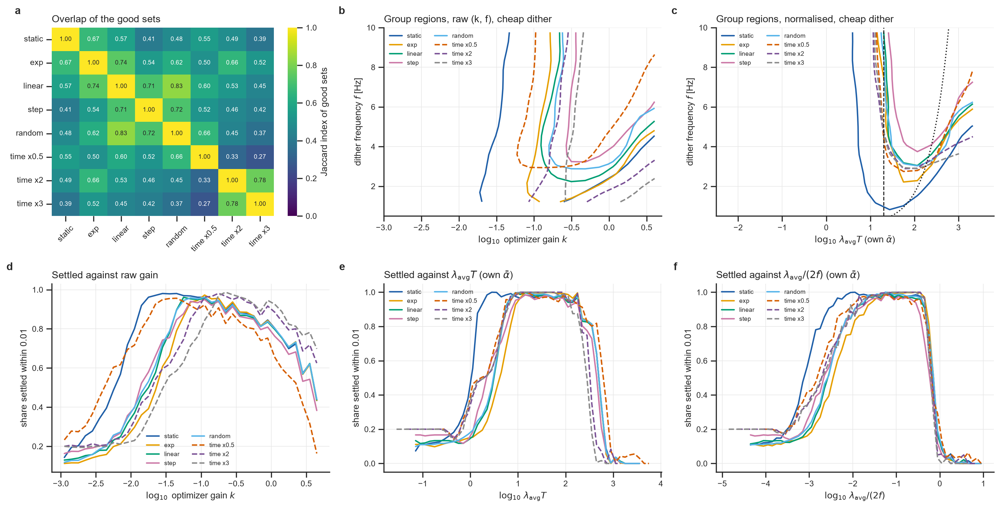

In [25]:
def p_jaccard(ax):
    sns.heatmap(J, ax=ax, vmin=0, vmax=1, cmap='viridis', annot=True, fmt='.2f', annot_kws={'fontsize': 7},
                cbar_kws={'label': 'Jaccard index of good sets'})
    ax.tick_params(axis='x', rotation=45); ax.tick_params(axis='y', rotation=0)


def p_contours(z, xe, ye, xlabel, ylabel):
    def draw(ax):
        xm, ym = 0.5 * (xe[1:] + xe[:-1]), 0.5 * (ye[1:] + ye[:-1])
        for g in GROUPS:
            ax.contour(xm, ym, z[g].T, levels=[0.5], colors=[GROUP_COLOR[g]], linewidths=1.6,
                       linestyles='--' if g.startswith('time') else '-')
            ax.plot([], [], color=GROUP_COLOR[g], ls='--' if g.startswith('time') else '-', label=g)
        ax.set_xlim(xe[[0, -1]]); ax.set_ylim(ye[[0, -1]]); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        ax.legend(fontsize=7, loc='upper left', ncol=2)
    return draw


def p_edge_curve(name, xlabel):
    def draw(ax):
        for g in GROUPS:
            d = grp[grp.group == g]
            share_curve(ax, np.asarray(coords[name](d)), d['settled_0.01'].values, CB[name], color=GROUP_COLOR[g], label=g,
                        ls='--' if g.startswith('time') else '-')
        ax.set_xlabel(xlabel); ax.set_ylabel('share settled within 0.01'); ax.legend(fontsize=7, ncol=2)
    return draw


def p_contours_norm(ax):
    p_contours(zn, NX, EDGES['dither_frequency'], r'$\log_{10}\,\lambda_\mathrm{avg} T$ (own $\bar\alpha$)', esc.label('dither_frequency'))(ax)
    ax.axvline(np.log10(bn[1]), color='k', ls='--', lw=1.1)
    ax.plot(np.log10(bn[2] * 2 * F_LINE * T), F_LINE, 'k:', lw=1.3)


panels_3a = [('Overlap of the good sets', p_jaccard),
             ('Group regions, raw (k, f), cheap dither', p_contours(zr, EDGES['log10_gain'], EDGES['dither_frequency'],
                                                                     esc.label('log10_gain'), esc.label('dither_frequency'))),
             ('Group regions, normalised, cheap dither', p_contours_norm),
             ('Settled against raw gain', p_edge_curve('log10 k', esc.label('log10_gain'))),
             ('Settled against $\\lambda_\\mathrm{avg} T$ (own $\\bar\\alpha$)', p_edge_curve('log10 lamT, own abar', r'$\log_{10}\,\lambda_\mathrm{avg} T$')),
             ('Settled against $\\lambda_\\mathrm{avg}/(2f)$ (own $\\bar\\alpha$)', p_edge_curve('log10 rho, own abar', r'$\log_{10}\,\lambda_\mathrm{avg}/(2f)$'))]
show(panels_3a, 3, size=(5.2, 4.0))

The same panels, one per figure.

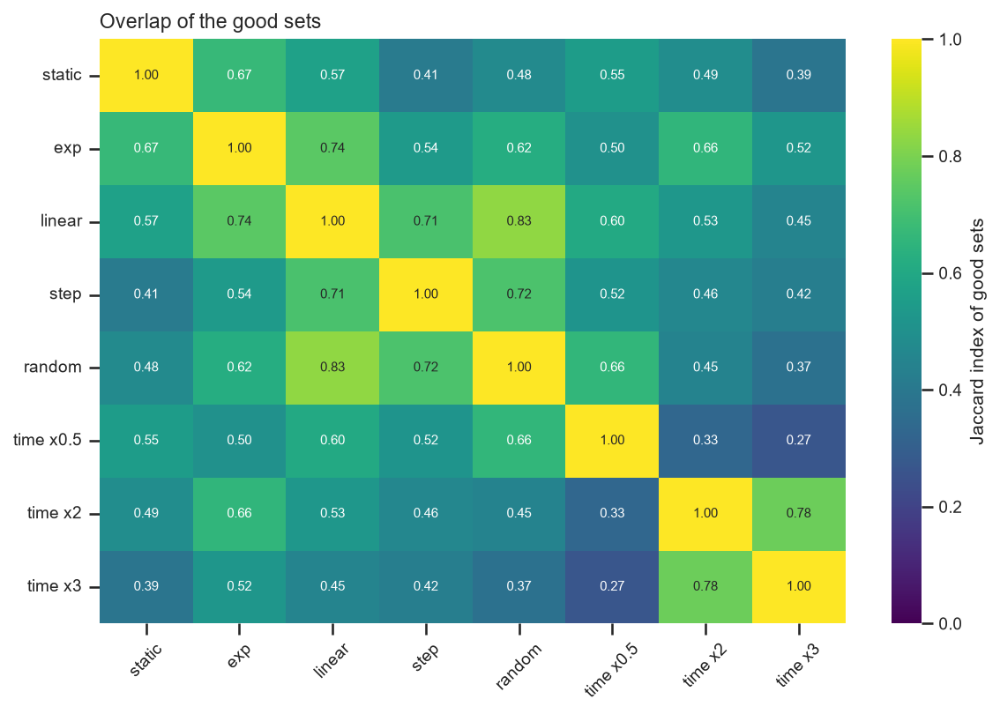

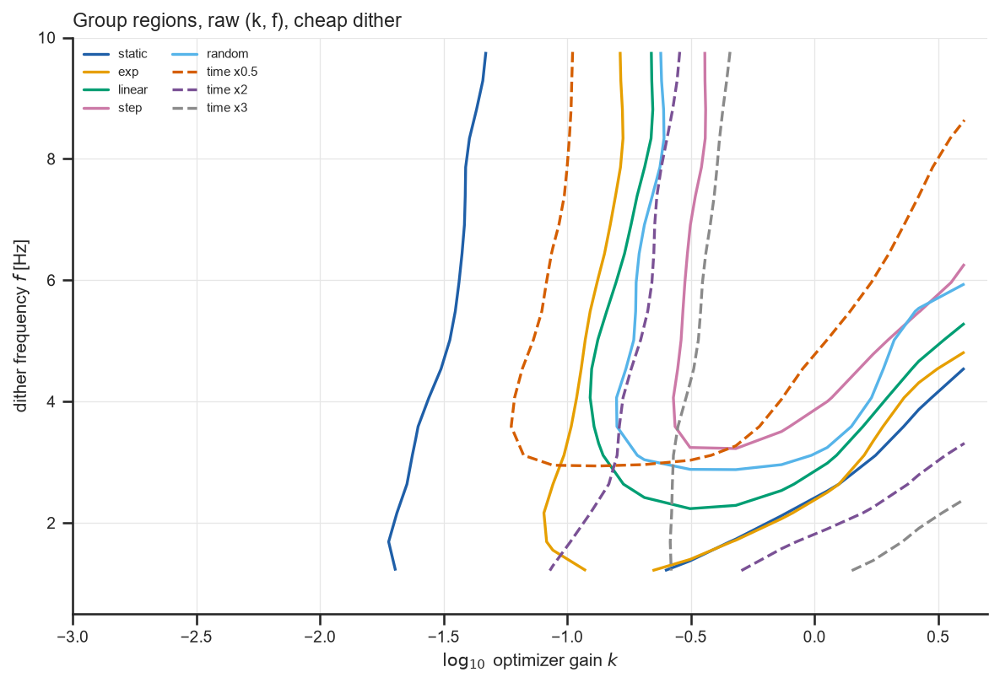

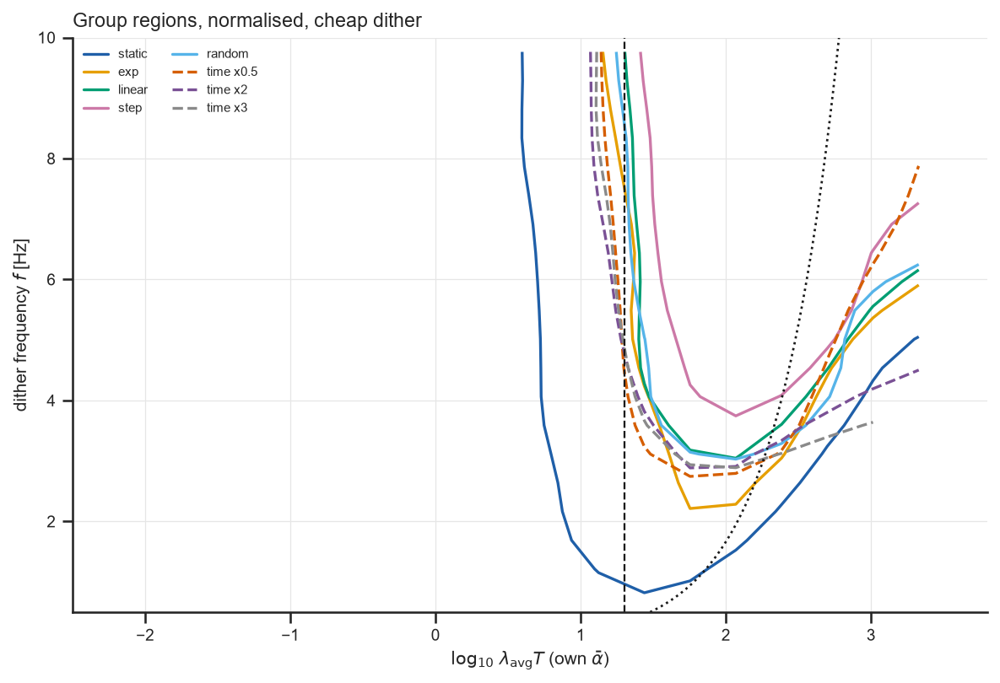

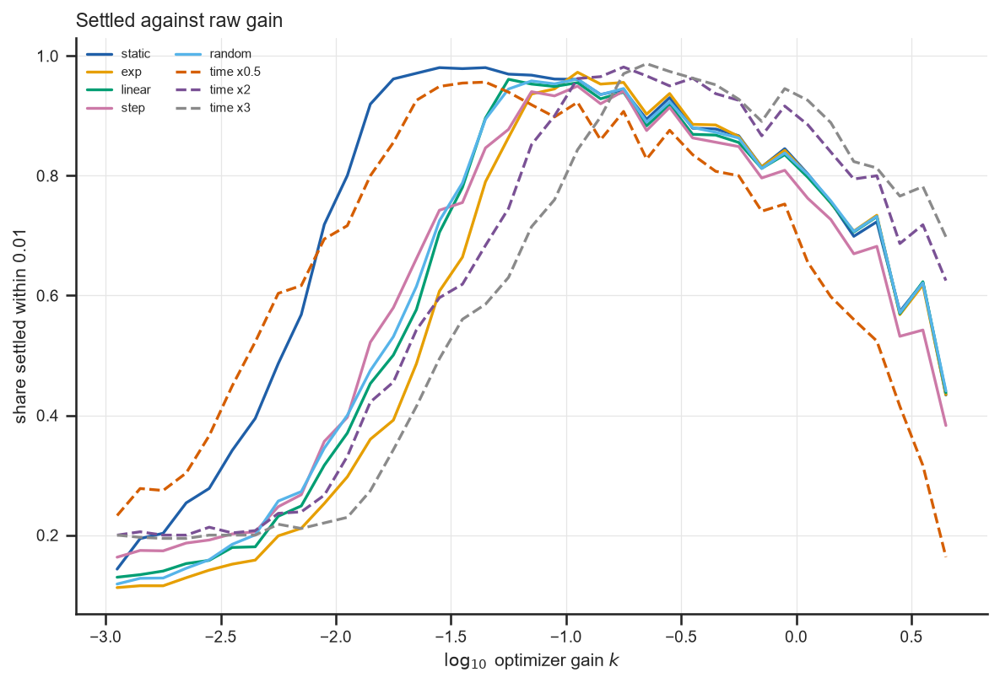

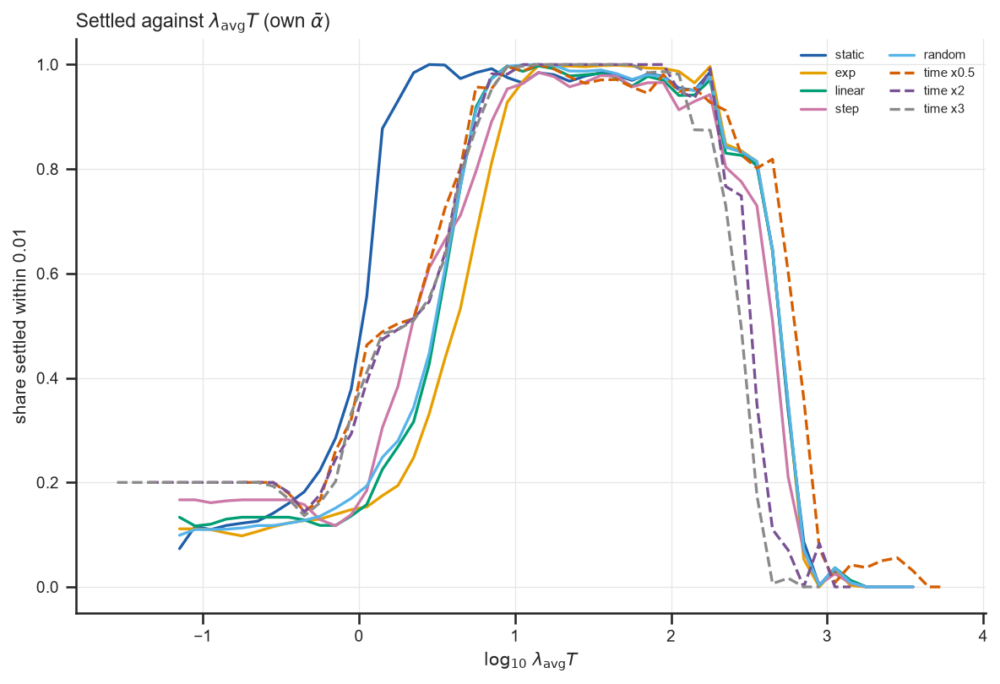

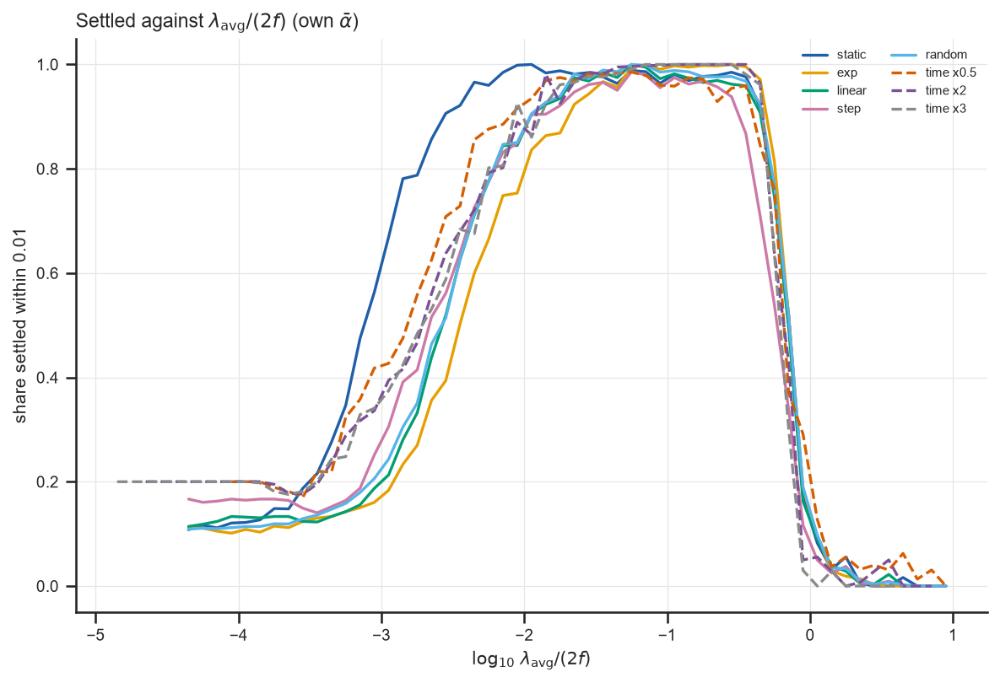

In [26]:
show_separate(panels_3a)

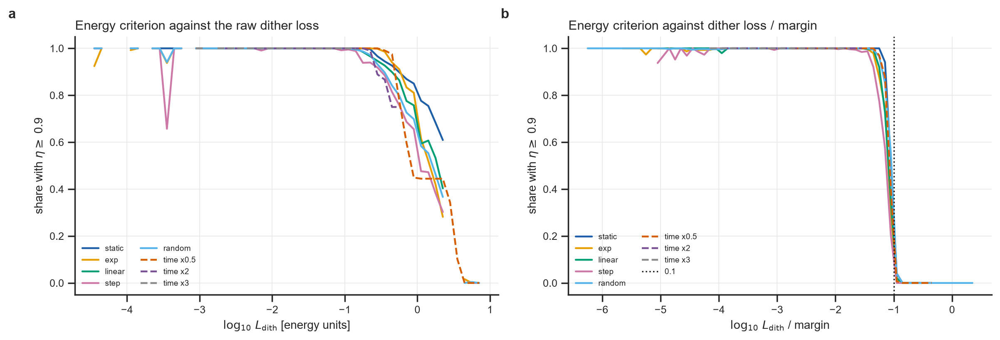

In [27]:
def p_energy(col, bins, xlabel, vline=None):
    def draw(ax):
        for g in GROUPS:
            d = tuned[tuned.group == g]
            share_curve(ax, d[col].values, d.ok.values, bins, color=GROUP_COLOR[g], label=g, ls='--' if g.startswith('time') else '-')
        if vline is not None:
            ax.axvline(vline, color='k', ls=':', lw=1.2, label=f'{10**vline:g}')
        ax.set_xlabel(xlabel); ax.set_ylabel(rf'share with $\eta \geq$ {ETA_MIN}'); ax.legend(fontsize=7, ncol=2)
    return draw


panels_3b = [('Energy criterion against the raw dither loss', p_energy('xr', EB_raw, r'$\log_{10}\,L_\mathrm{dith}$ [energy units]')),
             ('Energy criterion against dither loss / margin', p_energy('xn', EB_norm, r'$\log_{10}\,L_\mathrm{dith}$ / margin',
                                                                       vline=np.log10(1 - ETA_MIN)))]
show(panels_3b, 2, size=(6.0, 4.2))

The same curves, one per figure.

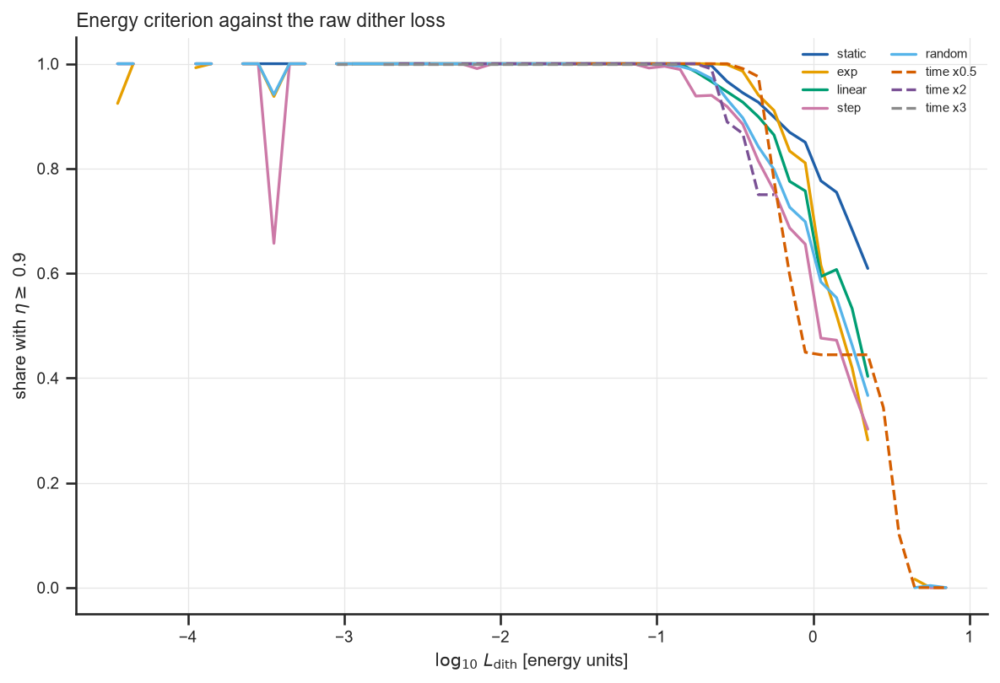

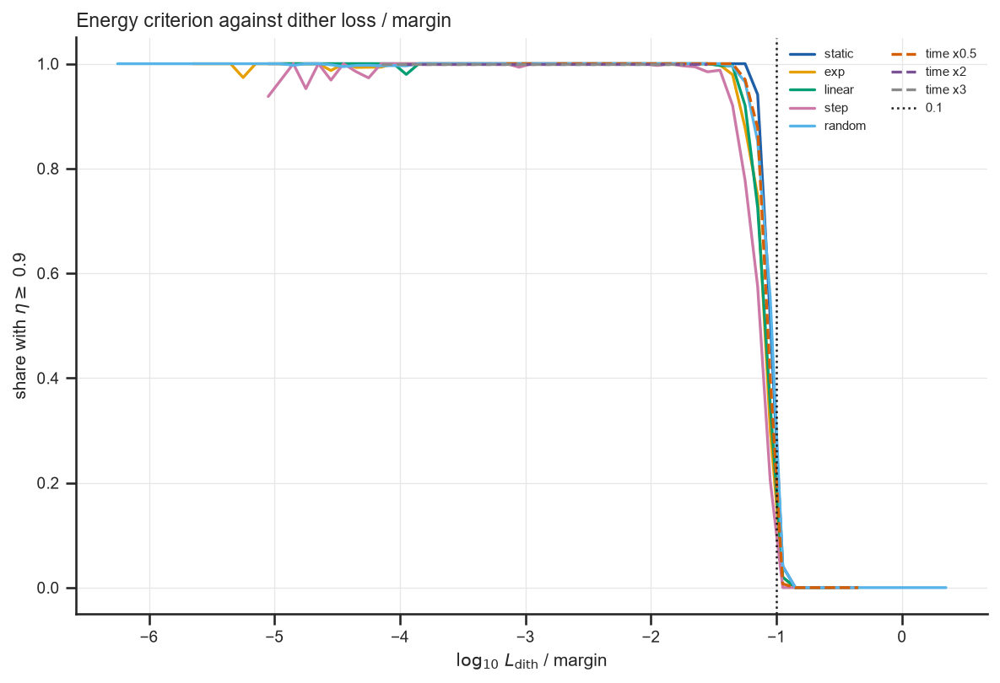

In [28]:
show_separate(panels_3b)

**What this shows.**
- In raw settings the groups do not share one region: the good-set masks overlap only partly (Jaccard indices printed),
  and the least similar pair is the fastest against the slowest plants. Part of the difference between families is the
  number of plants: a worst case over many plants (random) is stricter than over a few.
- The plant's time scale explains most of the shift, and normalised coordinates remove it. Among the three time-scale
  groups the lower (too slow) edge moves by most of a decade in $k$ but hardly at all in $\lambda_\mathrm{avg} T$ computed with the
  plant's own $\bar\alpha$. The upper (too fast) edge does not line up in $\lambda_\mathrm{avg} T$; it lines up in
  $\rho = \lambda_\mathrm{avg}/(2f)$, the ESC rate compared with the cut-off of its own filters, for every group (spreads printed).
  This is the averaging condition: the gradient estimate is only valid when the ESC is slower than its filters.
- What normalisation does not remove is the drift: among the nominal families the lower edge still differs, because a
  drifting ideal ratio needs a faster ESC than a fixed one (static plants need the least).
- The energy criterion lines up in $L_\mathrm{dith}$/margin: for every group a well-tuned run keeps $\eta \ge$ `ETA_MIN` while the
  dither loss stays below a little less than $1 -$ `ETA_MIN` of the margin (dotted line); in raw $L_\mathrm{dith}$ the groups
  differ. Note that the dither loss itself depends on the plant: a faster plasma follows the dither more and loses more.
- One rule in normalised coordinates describes the good sets of every group about equally well, clearly better than the
  best rule in raw coordinates on the fast and slow plants (per-group Jaccard printed), and with the dither kept cheap the
  group regions overlap much better in the normalised plane than in the raw one.
- Settling time in seconds is plant-dependent, but in plant time units ($t \bar\alpha$) it is similar (printed above).
- So the *shape* of the good region is the same for every plant in normalised terms; what depends on the plant is (i) its
  time scale $\bar\alpha$, which shifts the region in $k$ and $f$ and changes the dither loss, (ii) its margin, which sets how
  small the dither loss must be, and (iii) how fast its ideal ratio drifts. A window for an unknown plant must cover the
  slowest and the fastest plant expected and the smallest margin that matters.

## 4. The two peaks of the gain distribution, across plants

**What and why.** In OTO-Plant_fix the energy of random ESC settings had two peaks. The explanation given there: the
energy score follows an S-curve in $\lambda_\mathrm{avg} T$,
$$\eta_S = 1 - \frac{1 - e^{-2\lambda_\mathrm{avg} T}}{2\lambda_\mathrm{avg} T}$$
(for a plant whose ideal ratio does not move), so a log-uniform $k$ puts many runs on the flat left part (gain near 0) and
many on the flat right part (gain near margin $- L_\mathrm{dith}$). If that is right, every plant should show it, and the
model $\eta_\mathrm{model} = \eta_S(\lambda_\mathrm{avg} T) - L_\mathrm{dith}/\mathrm{margin}$, with no fitted numbers, should reproduce the
distributions. Here $k$ is log-uniform from $10^{-3}$ (OTO-Plant_fix went down to $10^{-5}$), which changes how many runs land
on the left part. The model does not include instability, so runs with $\rho$ above the upper edge of Section 3 are counted
apart. Histograms use narrow bins (0.02 in $\eta$) and the energy densities a 1-unit kernel: the default kernel width
hides the peaks.

In [29]:
def eta_S(x):
    x = np.asarray(x, float)
    return 1 - (1 - np.exp(-2 * x)) / (2 * x)


RHO_UNSTABLE = 10 ** np.nanmedian(edges[('log10 rho, own abar', 'upper')])
q = conv[conv.eta.notna()].copy()
q['eta_model'] = eta_S(q.lamT) - q.L_dith / q.margin
parts = {'left plateau (lamT < 0.3)': q.lamT < 0.3, 'transition (0.3-30)': q.lamT.between(0.3, 30),
         'right plateau (lamT > 30)': (q.lamT > 30) & (q.rho <= RHO_UNSTABLE), f'beyond the upper edge (rho > {RHO_UNSTABLE:.2f})': q.rho > RHO_UNSTABLE}
print(f'{len(q):,} runs (quasi-random sets, plants with margin >= floor, no sine); where the sampling puts them:')
for name, mask in parts.items():
    print(f'  {name:36s} {mask.mean():.1%} of runs; median measured eta {q.eta[mask].median():.3f}, model {q.eta_model[mask].median():.3f}')
stable = q[q.rho <= RHO_UNSTABLE]
print(f'stable runs: median |eta - eta_model| = {np.median(np.abs(stable.eta - stable.eta_model)):.3f}; '
      f'90th percentile {np.quantile(np.abs(stable.eta - stable.eta_model), 0.9):.3f}')

# per plant: does every plant have the two plateaus, and does the model predict their size?
pp = q.groupby('plant').agg(group=('group', 'first'), margin=('margin', 'first'),
                            left=('eta', lambda e: (e < 0.2).mean()), right=('eta', lambda e: (e > 0.8).mean()))
pm = q.groupby('plant').eta_model.agg(left_m=lambda e: (e < 0.2).mean(), right_m=lambda e: (e > 0.8).mean())
pp = pp.join(pm)
print(f'per plant ({len(pp)} plants): share of runs with eta > 0.8 from {pp.right.min():.1%} to {pp.right.max():.1%} '
      f'(model {pp.right_m.min():.1%}-{pp.right_m.max():.1%}), correlation measured/model {pp[["right", "right_m"]].corr().iloc[0, 1]:.2f}; '
      f'share with eta < 0.2 from {pp.left.min():.1%} to {pp.left.max():.1%} (model {pp.left_m.min():.1%}-{pp.left_m.max():.1%})')
print('median share of runs with eta > 0.8 per group:', pp.groupby('group').right.median().reindex(GROUPS).round(2).to_dict())

# model only: the same (a, f) values, but k log-uniform from 1e-5 as in OTO-Plant_fix
rng = np.random.default_rng(1)
k_ext = 10 ** rng.uniform(-5, np.log10(5), len(q))
lamT_ext = esc.lam_avg(k_ext, q.dither_frequency.values, q.alpha_bar.values) * T
eta_ext = eta_S(lamT_ext) - q.L_dith.values / q.margin.values
print(f'model only, k from 1e-5: {np.mean(lamT_ext < 0.3):.1%} of runs on the left plateau (lamT < 0.3), '
      f'against {np.mean(q.lamT < 0.3):.1%} with k from 1e-3')

W_ids = per_set.index[per_set.window]
qw = q[q.set.isin(W_ids)]
print(f'window sets: {len(qw):,} runs; eta from {qw.eta.min():.3f} to {qw.eta.max():.3f}, median {qw.eta.median():.3f}; '
      f'share with eta > 0.8: {(qw.eta > 0.8).mean():.1%}')

1,036,000 runs (quasi-random sets, plants with margin >= floor, no sine); where the sampling puts them:
  left plateau (lamT < 0.3)            8.0% of runs; median measured eta 0.179, model 0.149
  transition (0.3-30)                  52.2% of runs; median measured eta 0.792, model 0.778
  right plateau (lamT > 30)            30.7% of runs; median measured eta 0.980, model 0.984
  beyond the upper edge (rho > 0.68)   9.2% of runs; median measured eta -1.116, model 0.909
stable runs: median |eta - eta_model| = 0.033; 90th percentile 0.160
per plant (518 plants): share of runs with eta > 0.8 from 26.6% to 68.5% (model 39.5%-68.0%), correlation measured/model 0.85; share with eta < 0.2 from 5.1% to 45.4% (model 5.8%-25.4%)
median share of runs with eta > 0.8 per group: {'static': 0.63, 'exp': 0.52, 'linear': 0.6, 'step': 0.53, 'random': 0.6, 'time x0.5': 0.44, 'time x2': 0.57, 'time x3': 0.55}
model only, k from 1e-5: 39.0% of runs on the left plateau (lamT < 0.3), against 8.0% with k fro

representative plant per group (margin closest to the group median): {'static': 'plant 8, margin 47.0', 'exp': 'plant 87, margin 21.7', 'linear': 'plant 151, margin 21.0', 'step': 'plant 181, margin 17.2', 'random': 'plant 422, margin 18.4', 'time x3': 'plant 134, margin 8.0'}


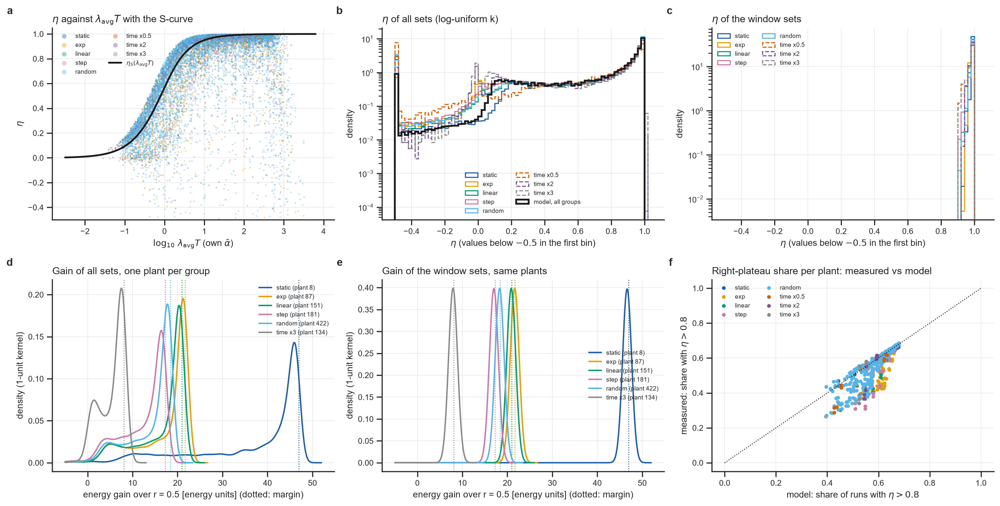

In [30]:
HB = np.arange(-0.5, 1.06, 0.02)
REP = {}
for g in GROUPS[:5] + ['time x3']:
    d = pp[pp.group == g]
    REP[g] = (d.margin - d.margin.median()).abs().idxmin()
print('representative plant per group (margin closest to the group median):',
      {g: f'plant {p}, margin {pp.margin[p]:.1f}' for g, p in REP.items()})


def kde(values, grid, width=1.0):
    v = np.asarray(values, float)[:, None]
    return np.exp(-0.5 * ((grid[None, :] - v) / width) ** 2).sum(0) / (len(v) * width * np.sqrt(2 * np.pi))


def p_scurve(ax):
    s = q.sample(15000, random_state=0)
    for g in GROUPS:
        d = s[s.group == g]
        ax.scatter(np.log10(d.lamT), d.eta, s=3, alpha=0.4, color=GROUP_COLOR[g], lw=0, label=g)
    x = np.logspace(-2.5, 3.8, 300)
    ax.plot(np.log10(x), eta_S(x), 'k-', lw=2, label=r'$\eta_S(\lambda_\mathrm{avg}T)$')
    ax.set_ylim(-0.5, 1.05); ax.set_xlabel(r'$\log_{10}\,\lambda_\mathrm{avg} T$ (own $\bar\alpha$)'); ax.set_ylabel(r'$\eta$')
    ax.legend(fontsize=7, ncol=2, markerscale=3)


def p_hist(d, title_model=True):
    def draw(ax):
        for g in GROUPS:
            e = d[d.group == g].eta.clip(HB[0], HB[-1])
            ax.hist(e, HB, density=True, histtype='step', color=GROUP_COLOR[g], lw=1.2, label=g, ls='--' if g.startswith('time') else '-')
        if title_model:
            ax.hist(d.eta_model.clip(HB[0], HB[-1]), HB, density=True, histtype='step', color='k', lw=2, label='model, all groups')
        ax.set_xlabel(r'$\eta$ (values below $-0.5$ in the first bin)'); ax.set_ylabel('density'); ax.set_yscale('log')
        ax.legend(fontsize=7, ncol=2)
    return draw


def p_gain(ids_all=True):
    def draw(ax):
        for g, p in REP.items():
            d = q[q.plant == p] if ids_all else qw[qw.plant == p]
            m = pp.margin[p]
            grid = np.linspace(-5, m + 5, 600)
            ax.plot(grid, kde(d.energy_gain, grid), color=GROUP_COLOR[g], label=f'{g} (plant {p})')
            ax.axvline(m, color=GROUP_COLOR[g], ls=':', lw=1)
        ax.set_xlabel('energy gain over r = 0.5 [energy units] (dotted: margin)'); ax.set_ylabel('density (1-unit kernel)')
        ax.legend(fontsize=7)
    return draw


def p_perplant(ax):
    for g in GROUPS:
        d = pp[pp.group == g]
        ax.scatter(d.right_m, d.right, s=10, color=GROUP_COLOR[g], label=g)
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlabel(r'model: share of runs with $\eta > 0.8$'); ax.set_ylabel(r'measured: share with $\eta > 0.8$')
    ax.legend(fontsize=7, ncol=2)


panels_4 = [('$\\eta$ against $\\lambda_\\mathrm{avg} T$ with the S-curve', p_scurve),
            ('$\\eta$ of all sets (log-uniform k)', p_hist(q)),
            ('$\\eta$ of the window sets', p_hist(qw, title_model=False)),
            ('Gain of all sets, one plant per group', p_gain(True)),
            ('Gain of the window sets, same plants', p_gain(False)),
            ('Right-plateau share per plant: measured vs model', p_perplant)]
show(panels_4, 3, size=(5.2, 4.0))

The same panels, one per figure.

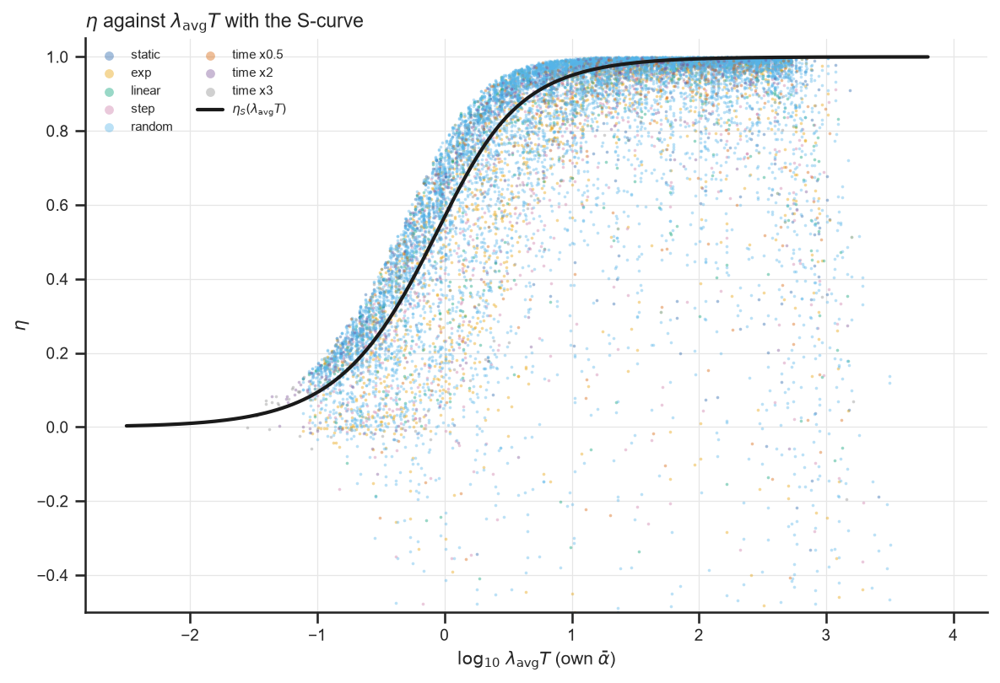

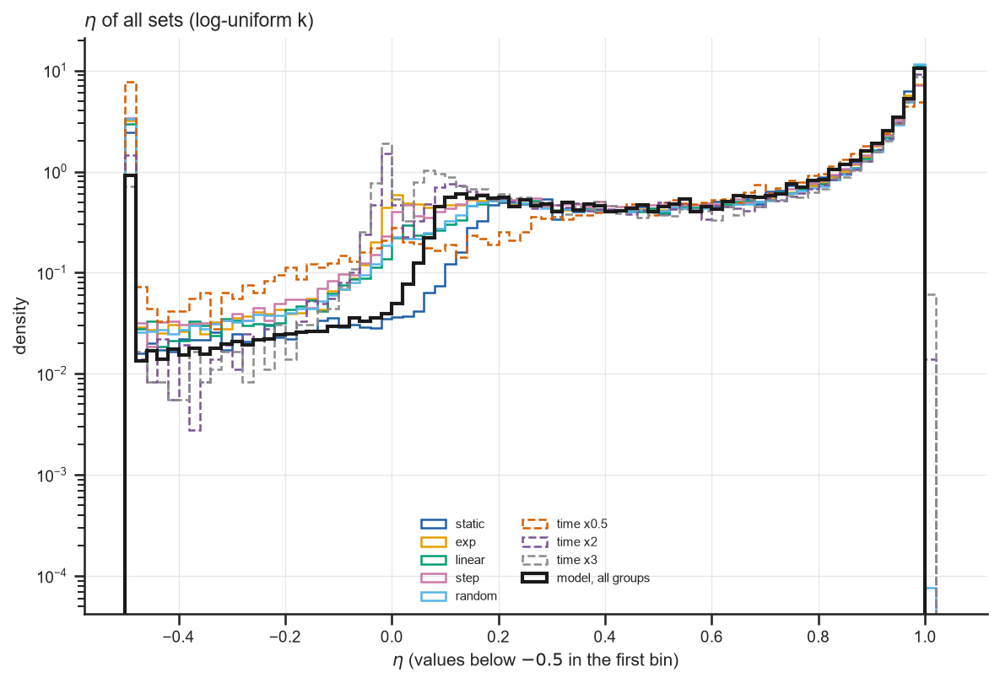

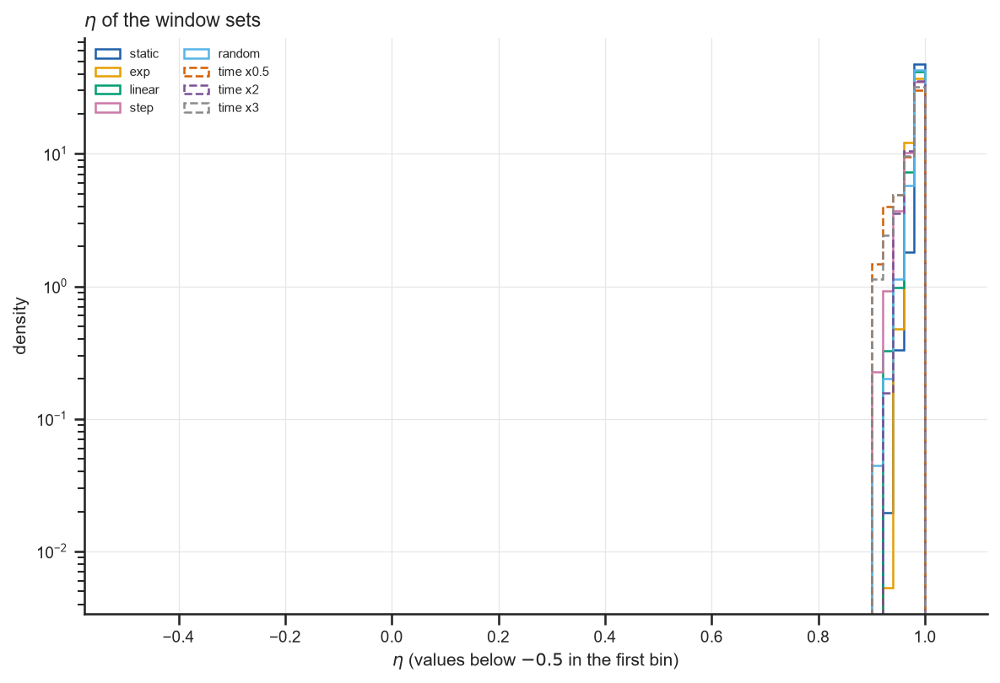

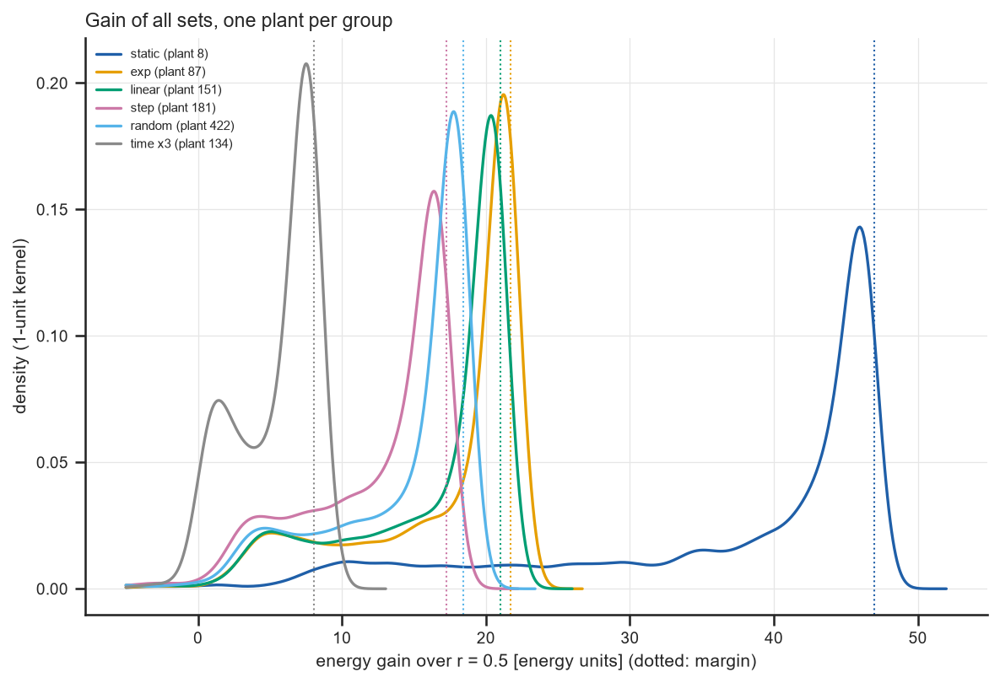

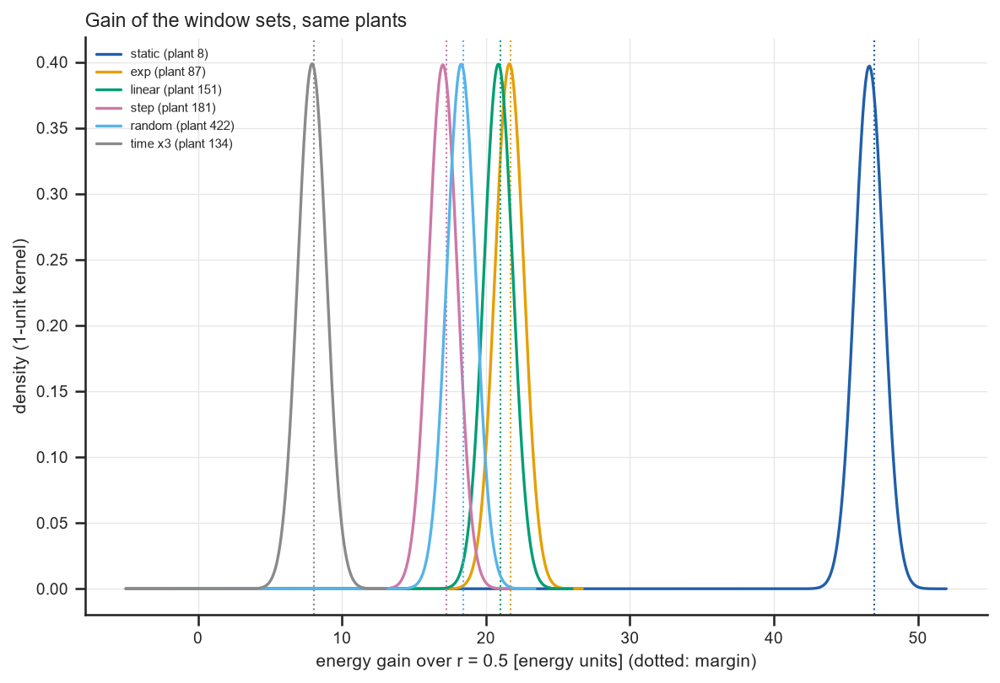

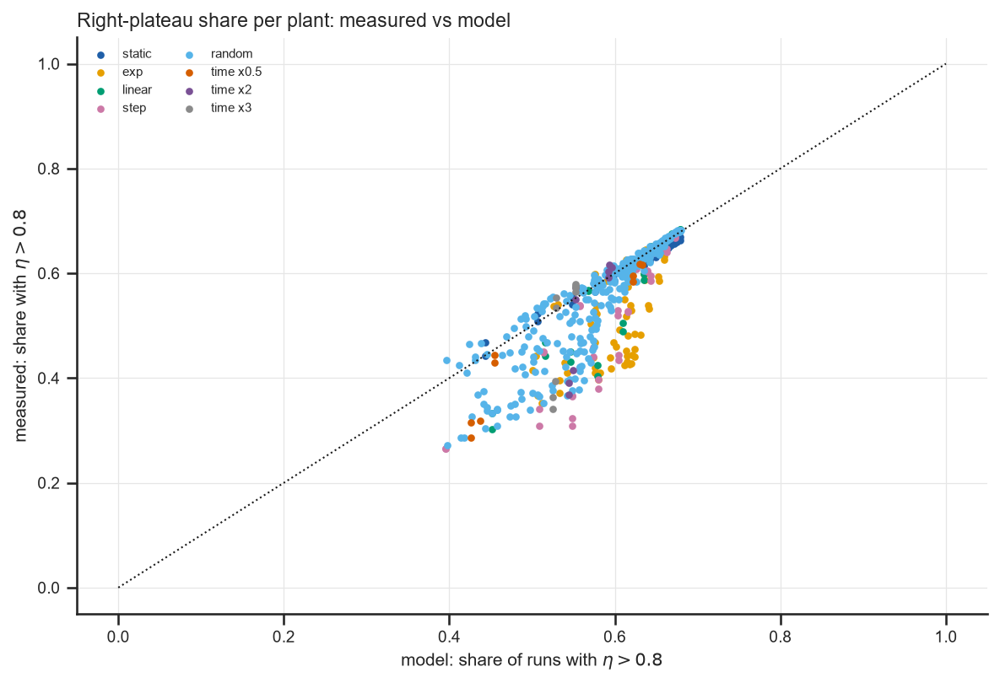

In [31]:
show_separate(panels_4)

**What this shows.** Every group and every plant shows the same structure, and the S-curve explains it: runs follow
$\eta_S(\lambda_\mathrm{avg} T)$ up to the upper (instability) edge, the right plateau holds most runs, and the share of
right-plateau runs per plant follows the model (correlation printed above), although the model, made for a plant whose
ideal ratio does not move, puts somewhat too many runs there on drifting plants. With $k$ from $10^{-3}$ the left plateau is
thin, because few sets have $\lambda_\mathrm{avg} T < 0.3$; with $k$ from $10^{-5}$, as in OTO-Plant_fix, the same model puts
several times more runs there (printed), which is why the left peak was so strong in that notebook. The peaks
therefore come from how $k$ is sampled and from the S-curve, not from one plant. In energy units each plant's right
peak sits just below its own margin, and the left peak near zero is clearest on the slow plants, whose own
$\lambda_\mathrm{avg} T$ is smaller, so peaks of different plants fall at different places; pooling plants would blur
them. The model misses the runs beyond the upper edge (the pile at the left end of the histogram), which are unstable
runs it does not describe. Restricted to the window, only one narrow peak near $\eta = 1$ is left.

## 5. Time-step sensitivity of the region (input for JJ)

**What and why.** The simulation updates the loop every $dt = 0.01$ s, i.e. a 100 Hz digital ESC. The time-step check
(`checks/ESC_time_step_check.ipynb`) found that at high dither frequency this sampled loop converges faster than the
continuous-time averaged rate predicts, by a factor that the sampled-loop formula
$\mathrm{Re}\{G(z)H(z)\}$ gives ($G$ the sampled plant, $H$ the sampled high-pass filter, $z = e^{i\omega\,dt}$). The `dt0.002`
block repeats the five chosen sets and the first 200 quasi-random sets, which spread over the whole parameter box
(printed), on 50 plants at $dt = 0.002$ s; the same (set, plant) pairs exist at $dt = 0.01$ in the steady blocks. Each block
is compared with its own references.

Three measurements:
1. Run by run: settled or not, settling time, $\eta$ and gain at the two time steps, and window membership on this subset.
2. Convergence speed: for slow, overdamped runs ($\lambda_\mathrm{avg} < \bar\alpha/4$) the settling time scales as one over the
   rate, so $t(0.002)/t(0.01)$ measures how much faster the $dt = 0.01$ loop is. It is compared with the formula
   $\mathrm{Re}\{GH\}_{dt=0.01} / \mathrm{Re}\{GH\}_{dt=0.002}$ against the dither frequency.
3. Region edges: in three frequency bands, the lower (too slow) and upper (unstable) 50 % edges of the share of settled runs,
   from a logistic fit of "settled" against $\log_{10}$ of the speed coordinate, separately for each time step; the interval
   comes from a bootstrap over the ESC sets (paired: the same sets at both time steps). This is done twice: with the
   continuous $\lambda_\mathrm{avg} T$ (own $\bar\alpha$), where the edges should move by the formula's factor, and with the sampled
   rate $\lambda_d T = 2 n_\mathrm{ref}^2 k\,\mathrm{Re}\{G(z)H(z)\}\,T$ of each time step, where they should not move if the formula
   explains the shift. An edge counts as resolved only when at least 30 runs lie beyond it.

In [32]:
from scipy.special import expit


def c_sampled(f, dt, alpha_bar=esc.ALPHA_BAR):
    # c(omega) of the loop as the simulation samples it (from checks/ESC_time_step_check.ipynb): Re{G(z) H(z)}
    w = 2 * np.pi * np.asarray(f, dtype=float)
    z = np.exp(1j * w * dt)
    A = np.exp(-np.asarray(alpha_bar) * dt)
    p = np.exp(-(w / np.pi) * dt)
    return np.real((1 - A) / (1 - A / z) * (1 - 1 / z) / (1 - p / z))


qs = sets[sets.set.isin(dt2.set.unique()) & (sets.set >= 5)]
print(f'dt0.002 block: {dt2.set.nunique()} sets x {dt2.plant.nunique()} plants = {len(dt2):,} runs; '
      f'plants per family {dt2.drop_duplicates("plant").family.value_counts().to_dict()}')
print(f'its {len(qs)} quasi-random sets (ids {qs.set.min()}-{qs.set.max()}) cover k {qs.optimizer_gain.min():.3f}-{qs.optimizer_gain.max():.2f} '
      f'(all sets: {sets.optimizer_gain[halton].min():.3f}-{sets.optimizer_gain[halton].max():.2f}), '
      f'f {qs.dither_frequency.min():.2f}-{qs.dither_frequency.max():.2f} Hz (all: {sets.dither_frequency[halton].min():.2f}-'
      f'{sets.dither_frequency[halton].max():.2f}), a {qs.dither_amplitude.min():.3f}-{qs.dither_amplitude.max():.3f}')

KEEP = ['set', 'plant', 'family', 'group', 'alpha_bar', 'optimizer_gain', 'dither_amplitude', 'dither_frequency', 'lam', 'lamT',
        'rho', 'L_dith', 'settled_0.01', 't_0.01', 'eta', 'energy_gain', 'margin']
cmp = pairs[KEEP].merge(dt2[['set', 'plant', 'settled_0.01', 't_0.01', 'eta', 'energy_gain', 'margin']],
                        on=['set', 'plant'], suffixes=('_01', '_002'))
cmp = cmp[cmp.family != 'sine'].reset_index(drop=True)
for dt, sfx in [(0.01, '01'), (0.002, '002')]:
    cmp[f'lamT_d{sfx}'] = 2 * esc.N_REF**2 * cmp.optimizer_gain * c_sampled(cmp.dither_frequency, dt, cmp.alpha_bar) * T
print(f'compared pairs (no sine): {len(cmp):,}; margin difference between the two blocks: '
      f'max |dmargin| = {np.abs(cmp.margin_002 - cmp.margin_01).max():.4f} energy units')
for name, col in [('dt = 0.01', 'settled_0.01_01'), ('dt = 0.002', 'settled_0.01_002')]:
    sh, ci = boot_share(cmp.rename(columns={col: 'x'}), 'x')
    print(f'  settled within 0.01 at {name}: {pct(sh, ci)}')
a, b = cmp['settled_0.01_01'], cmp['settled_0.01_002']
print(f'  settled at both {np.mean(a & b):.1%}, only at dt = 0.01 {np.mean(a & ~b):.1%}, only at dt = 0.002 {np.mean(~a & b):.1%}, '
      f'neither {np.mean(~a & ~b):.1%}')
bt = cmp[a & b].assign(ratio=lambda d: d['t_0.01_002'] / d['t_0.01_01'])
print(f'  settling time, runs settled at both: median {bt["t_0.01_01"].median():.1f} s (dt = 0.01) vs '
      f'{bt["t_0.01_002"].median():.1f} s (dt = 0.002); median ratio t(0.002)/t(0.01) {bt.ratio.median():.2f}')
ee = cmp[cmp.eta_01.notna() & cmp.eta_002.notna()]
de = ee.eta_002 - ee.eta_01; dg = cmp.energy_gain_002 - cmp.energy_gain_01
print(f'  eta(0.002) - eta(0.01): median {de.median():+.4f}, 5-95 % range {de.quantile(0.05):+.3f} to {de.quantile(0.95):+.3f}')
print(f'  gain(0.002) - gain(0.01): median {dg.median():+.3f}, 5-95 % range {dg.quantile(0.05):+.2f} to {dg.quantile(0.95):+.2f} energy units')
big = ee[np.abs(de) > 0.1]
print(f'  runs with |eta difference| > 0.1: {len(big)} of {len(ee)}: {np.mean(big.lamT < 30):.1%} are slow runs on the rising part of '
      f'the S-curve (lamT < 30), {np.mean(big.rho > 0.4):.1%} are near the upper edge (rho > 0.4); '
      f'of the slow ones, {np.mean(de[big.index][big.lamT < 30] < 0):.1%} collect less at dt = 0.002')
tuned_dt = cmp.set.isin(range(5))
print(f'  the five chosen sets: median |gain difference| {dg[tuned_dt].abs().median():.3f}, max {dg[tuned_dt].abs().max():.3f} energy units')

dt0.002 block: 205 sets x 50 plants = 10,250 runs; plants per family {'random': 11, 'exp': 8, 'static': 7, 'timescale': 6, 'linear': 6, 'step': 6, 'sine': 6}
its 200 quasi-random sets (ids 5-204) cover k 0.001-4.68 (all sets: 0.001-4.96), f 0.52-9.92 Hz (all: 0.50-9.99), a 0.007-0.595
compared pairs (no sine): 9,020; margin difference between the two blocks: max |dmargin| = 0.0120 energy units
  settled within 0.01 at dt = 0.01: 61.8% [58.5%, 65.4%]
  settled within 0.01 at dt = 0.002: 59.6% [56.0%, 63.6%]
  settled at both 58.9%, only at dt = 0.01 2.9%, only at dt = 0.002 0.7%, neither 37.5%
  settling time, runs settled at both: median 8.4 s (dt = 0.01) vs 8.1 s (dt = 0.002); median ratio t(0.002)/t(0.01) 1.03
  eta(0.002) - eta(0.01): median -0.0099, 5-95 % range -0.122 to +0.026
  gain(0.002) - gain(0.01): median -0.194, 5-95 % range -5.21 to +0.71 energy units
  runs with |eta difference| > 0.1: 1118 of 8815: 71.4% are slow runs on the rising part of the S-curve (lamT < 30), 28.6%

In [33]:
# 1. window membership on this subset (no off-0.5 starts at dt = 0.002, so criterion 2 is left out)
def membership(sfx):
    g = cmp.groupby('set')
    settled = g[f'settled_0.01_{sfx}'].all()
    t = g[f't_0.01_{sfx}'].max().where(settled)
    e = cmp[cmp[f'eta_{sfx}'].notna()].groupby('set')[f'eta_{sfx}'].min()
    return settled & (t <= T_MAX) & (e.reindex(settled.index) >= ETA_MIN), settled, e


win01, set01, e01 = membership('01'); win002, set002, e002 = membership('002')
print(f'sets that settle on all {cmp.plant.nunique()} non-sine plants of the subset: dt = 0.01 {set01.sum()}, dt = 0.002 {set002.sum()}')
print(f'sets in the window (criteria 1, 3 and 4 on this subset): dt = 0.01 {win01.sum()}, dt = 0.002 {win002.sum()}; '
      f'in both {(win01 & win002).sum()}, only dt = 0.01 {(win01 & ~win002).sum()}, only dt = 0.002 {(~win01 & win002).sum()}')
moved = sets.set_index('set').loc[win01.index[win01 ^ win002], esc.ESC_PARAMS].assign(in_at=np.where(win01[win01 ^ win002], 'dt = 0.01 only', 'dt = 0.002 only'))
print('sets that change membership:'); print(moved.round(3).to_string())
print(f'median gain of the sets in the window only at dt = 0.01: {moved.optimizer_gain[moved.in_at == "dt = 0.01 only"].median():.2f}; '
      f'only at dt = 0.002: {moved.optimizer_gain[moved.in_at == "dt = 0.002 only"].median():.2f}')
print('chosen sets: in window at dt = 0.01', win01.loc[range(5)].to_dict(), '; at dt = 0.002', win002.loc[range(5)].to_dict())
print('chosen sets, worst eta at dt = 0.01:', e01.loc[range(5)].round(3).to_dict(), '; at dt = 0.002:', e002.loc[range(5)].round(3).to_dict())

# 2. convergence speed of slow, overdamped runs
slow = bt[(bt.lam < bt.alpha_bar / 4) & (bt.family != 'step')].copy()
slow['pred'] = c_sampled(slow.dither_frequency, 0.01, slow.alpha_bar) / c_sampled(slow.dither_frequency, 0.002, slow.alpha_bar)
slow['fbin'] = pd.cut(slow.dither_frequency, np.arange(0.5, 10.51, 1.0))
tab = slow.groupby('fbin', observed=True).agg(runs=('ratio', 'size'), f=('dither_frequency', 'median'),
                                              measured=('ratio', 'median'), predicted=('pred', 'median'))
tab['measured/predicted'] = tab.measured / tab.predicted
print(f'\nslow runs settled at both time steps (lam_avg < alpha_bar/4, no step plants): {len(slow)}')
print('speed ratio = t(0.002)/t(0.01) (> 1: the dt = 0.01 loop is faster):')
print(tab.round(3).to_string())
print(f'median |measured / predicted - 1| over these runs: {np.median(np.abs(slow.ratio / slow.pred - 1)):.1%}; '
      f'measured / predicted per bin {tab["measured/predicted"].min():.2f}-{tab["measured/predicted"].max():.2f}')
for f in [1, 3, 6, 10]:
    print(f'  formula at {f:>2} Hz: dt 0.01 vs 0.002 {c_sampled(f, 0.01) / c_sampled(f, 0.002):.2f}; dt 0.01 vs continuous '
          f'{c_sampled(f, 0.01) / esc.c_factor(f):.2f}; dt 0.002 vs continuous {c_sampled(f, 0.002) / esc.c_factor(f):.2f}')

sets that settle on all 44 non-sine plants of the subset: dt = 0.01 65, dt = 0.002 61
sets in the window (criteria 1, 3 and 4 on this subset): dt = 0.01 27, dt = 0.002 26; in both 21, only dt = 0.01 6, only dt = 0.002 5
sets that change membership:
     optimizer_gain  dither_amplitude  dither_frequency            in_at
set                                                                     
1             0.255             0.052             8.410   dt = 0.01 only
2             0.265             0.192             9.090   dt = 0.01 only
3             0.098             0.056             2.970   dt = 0.01 only
17            0.349             0.291             6.960   dt = 0.01 only
67            4.377             0.042             7.112  dt = 0.002 only
73            0.219             0.174             9.392   dt = 0.01 only
83            3.138             0.394             8.328  dt = 0.002 only
107           2.105             0.316             6.504  dt = 0.002 only
157           0.162  

In [34]:
# 3. region edges per frequency band: logistic fit of settled against log10(speed), bootstrap over sets
BANDS = [(0.5, 3.0), (3.0, 6.5), (6.5, 10.0)]
SIDE_WINDOW = {'lower': (-np.inf, 1.4), 'upper': (1.9, np.inf)}     # log10 lamT ranges that hold one edge each
B_EDGE = 200


def x50(x, y):
    # 50 % point of a logistic fit (iteratively reweighted least squares, small ridge for stability)
    X = np.column_stack([np.ones_like(x), x]); beta = np.zeros(2)
    for _ in range(50):
        p = expit(X @ beta); W = p * (1 - p) + 1e-9
        step = np.linalg.solve(X.T @ (X * W[:, None]) + 1e-3 * np.eye(2), X.T @ (y - p) - 1e-3 * beta)
        beta += step
        if np.abs(step).max() < 1e-7:
            break
    return -beta[0] / beta[1]


def fit_edge(d, side, coord, col):
    x = np.log10(d[coord].values); y = d[col].values.astype(float)
    lo, hi = SIDE_WINDOW[side]; m = (x > lo) & (x < hi)
    e = x50(x[m], y[m])
    beyond = np.sum(x[m] > e) if side == 'upper' else np.sum(x[m] < e)
    return e, beyond


set_rows = {s: idx.values for s, idx in cmp.groupby('set').groups.items()}
rows = []
for lo_f, hi_f in BANDS:
    band = cmp[cmp.dither_frequency.between(lo_f, hi_f)]
    f_med = band.dither_frequency.median()
    band_sets = band.set.unique()
    for side in ['lower', 'upper']:
        for cname, c1, c2 in [('continuous', 'lamT', 'lamT'), ('sampled', 'lamT_d01', 'lamT_d002')]:
            e1, n1 = fit_edge(band, side, c1, 'settled_0.01_01'); e2, n2 = fit_edge(band, side, c2, 'settled_0.01_002')
            row = {'band [Hz]': f'{lo_f:g}-{hi_f:g}', 'f median': f_med, 'edge': side, 'coordinate': cname,
                   'edge dt=0.01': e1, 'edge dt=0.002': e2, 'shift': e2 - e1, 'ci low': np.nan, 'ci high': np.nan,
                   'formula': np.log10(c_sampled(f_med, 0.01) / c_sampled(f_med, 0.002)) if cname == 'continuous' else 0.0}
            if min(n1, n2) < 30:
                row.update({'edge dt=0.01': np.nan, 'edge dt=0.002': np.nan, 'shift': np.nan})
            else:
                boots = []
                for _ in range(B_EDGE):
                    pick = RNG.choice(band_sets, len(band_sets))
                    dd = cmp.loc[np.concatenate([set_rows[s] for s in pick])]
                    boots.append(fit_edge(dd, side, c2, 'settled_0.01_002')[0] - fit_edge(dd, side, c1, 'settled_0.01_01')[0])
                row['ci low'], row['ci high'] = np.percentile(boots, [2.5, 97.5])
            rows.append(row)
edge_tab = pd.DataFrame(rows)
print('50 % edges of the share settled, log10 of the coordinate (shift = dt 0.002 minus dt 0.01, decades; NaN = fewer than 30 runs '
      'beyond the edge, i.e. not reached inside the sampled box):')
print(edge_tab.round(3).to_string(index=False))
ec = edge_tab[(edge_tab.coordinate == 'continuous')].dropna(subset=['shift'])
es = edge_tab[(edge_tab.coordinate == 'sampled')].dropna(subset=['shift'])
print(f'continuous coordinate: measured shifts {ec["shift"].min():+.3f} to {ec["shift"].max():+.3f} decades, formula '
      f'{ec.formula.min():+.3f} to {ec.formula.max():+.3f}; measured/formula {np.median(ec["shift"] / ec.formula):.2f} (median)')
print(f'sampled-rate coordinate: remaining shifts {es["shift"].min():+.3f} to {es["shift"].max():+.3f} decades')

50 % edges of the share settled, log10 of the coordinate (shift = dt 0.002 minus dt 0.01, decades; NaN = fewer than 30 runs beyond the edge, i.e. not reached inside the sampled box):
band [Hz]  f median  edge coordinate  edge dt=0.01  edge dt=0.002  shift  ci low  ci high  formula
    0.5-3     1.731 lower continuous         0.433          0.463  0.030   0.010    0.047    0.051
    0.5-3     1.731 lower    sampled         0.503          0.478 -0.026  -0.040   -0.006    0.000
    0.5-3     1.731 upper continuous         2.354          2.346 -0.009  -0.032    0.012    0.051
    0.5-3     1.731 upper    sampled         2.422          2.360 -0.063  -0.092   -0.034    0.000
    3-6.5     4.764 lower continuous         0.281          0.388  0.106   0.081    0.130    0.134
    3-6.5     4.764 lower    sampled         0.462          0.429 -0.033  -0.062   -0.006    0.000
    3-6.5     4.764 upper continuous         2.704          2.817  0.114   0.079    0.182    0.134
    3-6.5     4.764 upper

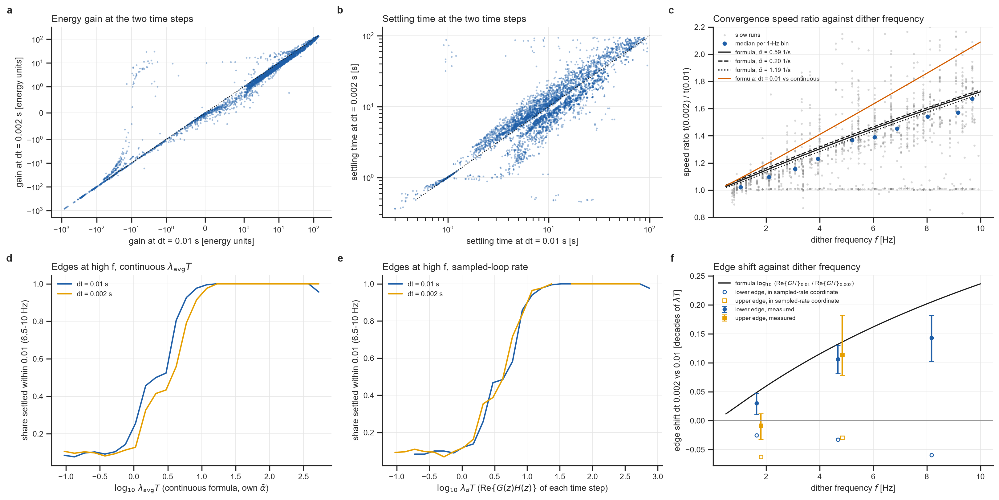

In [35]:
FF = np.linspace(0.5, 10, 200)
HIGH = cmp[cmp.dither_frequency.between(*BANDS[-1])]
LBF = np.arange(-2.0, 3.31, 0.15)


def p_dt_gain(ax):
    ax.scatter(cmp.energy_gain_01, cmp.energy_gain_002, s=4, alpha=0.4, lw=0, color=esc.COLORS['esc'])
    lim = [-50, 140]; ax.plot(lim, lim, 'k:', lw=1)
    ax.set_xscale('symlog', linthresh=1); ax.set_yscale('symlog', linthresh=1)
    ax.set_xlabel('gain at dt = 0.01 s [energy units]'); ax.set_ylabel('gain at dt = 0.002 s [energy units]')


def p_dt_time(ax):
    ax.scatter(bt['t_0.01_01'], bt['t_0.01_002'], s=4, alpha=0.4, lw=0, color=esc.COLORS['esc'])
    ax.plot([0.5, 100], [0.5, 100], 'k:', lw=1); ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('settling time at dt = 0.01 s [s]'); ax.set_ylabel('settling time at dt = 0.002 s [s]')


def p_dt_ratio(ax):
    ax.scatter(slow.dither_frequency, slow.ratio, s=6, alpha=0.3, lw=0, color='0.5', label='slow runs')
    ax.plot(tab.f, tab.measured, 'o', color=esc.COLORS['esc'], label='median per 1-Hz bin')
    for ab, ls in [(esc.ALPHA_BAR, '-'), (esc.ALPHA_BAR / 3, '--'), (esc.ALPHA_BAR * 2, ':')]:
        ax.plot(FF, c_sampled(FF, 0.01, ab) / c_sampled(FF, 0.002, ab), 'k', ls=ls, lw=1.3,
                label=rf'formula, $\bar\alpha$ = {ab:.2f} 1/s')
    ax.plot(FF, c_sampled(FF, 0.01) / esc.c_factor(FF), color=esc.COLORS['bad'], lw=1.3, label='formula: dt = 0.01 vs continuous')
    ax.set_ylim(0.8, 2.2); ax.set_xlabel(esc.label('dither_frequency')); ax.set_ylabel('speed ratio t(0.002) / t(0.01)')
    ax.legend(fontsize=7)


def p_dt_edges(col01, col002, xlabel):
    def draw(ax):
        for col, ycol, lab, c in [(col01, 'settled_0.01_01', 'dt = 0.01 s', esc.COLORS['esc']),
                                  (col002, 'settled_0.01_002', 'dt = 0.002 s', esc.COLORS['fixed'])]:
            share_curve(ax, np.log10(HIGH[col].values), HIGH[ycol].values, LBF, min_count=20, color=c, label=lab)
        ax.set_xlabel(xlabel); ax.set_ylabel(f'share settled within 0.01 ({BANDS[-1][0]:g}-{BANDS[-1][1]:g} Hz)')
        ax.legend(fontsize=8)
    return draw


def p_dt_shift(ax):
    ax.plot(FF, np.log10(c_sampled(FF, 0.01) / c_sampled(FF, 0.002)), 'k-', lw=1.3, label=r'formula $\log_{10}$ (Re$\{GH\}_{0.01}$ / Re$\{GH\}_{0.002}$)')
    for side, mk, off_ in [('lower', 'o', -0.08), ('upper', 's', 0.08)]:
        d = ec[ec.edge == side]
        ax.errorbar(d['f median'] + off_, d['shift'], yerr=[d['shift'] - d['ci low'], d['ci high'] - d['shift']], fmt=mk,
                    color=esc.COLORS['esc'] if side == 'lower' else esc.COLORS['fixed'], capsize=3, label=f'{side} edge, measured')
        d = es[es.edge == side]
        ax.plot(d['f median'] + off_, d['shift'], mk, mfc='none', color=esc.COLORS['esc'] if side == 'lower' else esc.COLORS['fixed'],
                label=f'{side} edge, in sampled-rate coordinate')
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set_xlabel(esc.label('dither_frequency')); ax.set_ylabel(r'edge shift dt 0.002 vs 0.01 [decades of $\lambda T$]')
    ax.legend(fontsize=7)


panels_5 = [('Energy gain at the two time steps', p_dt_gain), ('Settling time at the two time steps', p_dt_time),
            ('Convergence speed ratio against dither frequency', p_dt_ratio),
            ('Edges at high f, continuous $\\lambda_\\mathrm{avg}T$', p_dt_edges('lamT', 'lamT', r'$\log_{10}\,\lambda_\mathrm{avg} T$ (continuous formula, own $\bar\alpha$)')),
            ('Edges at high f, sampled-loop rate', p_dt_edges('lamT_d01', 'lamT_d002', r'$\log_{10}\,\lambda_d T$ (Re$\{G(z)H(z)\}$ of each time step)')),
            ('Edge shift against dither frequency', p_dt_shift)]
show(panels_5, 3, size=(5.4, 4.1))

The same panels, one per figure.

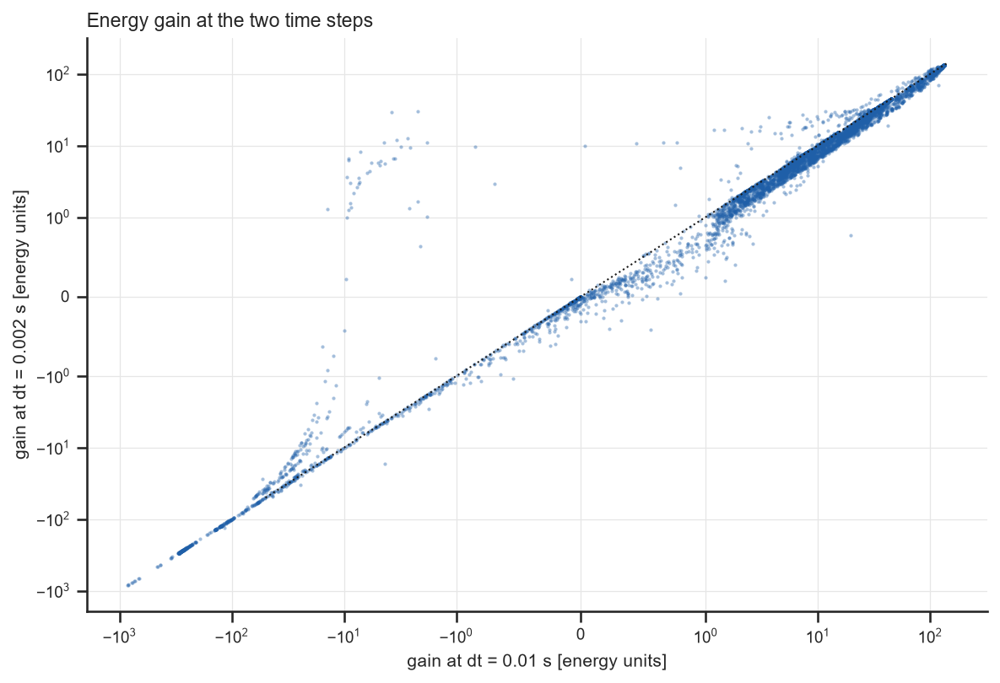

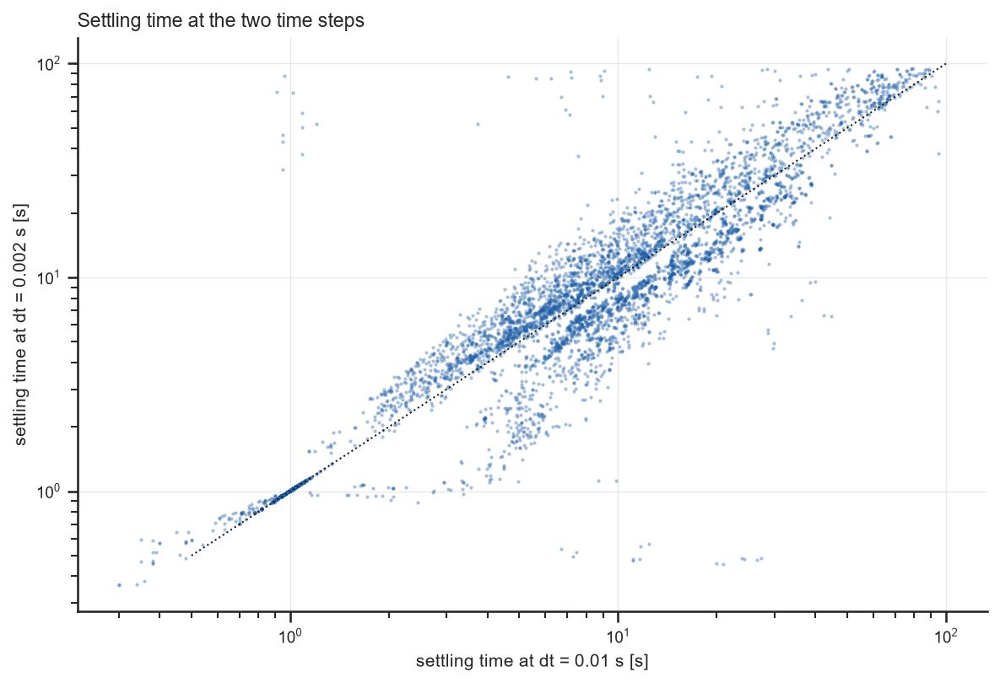

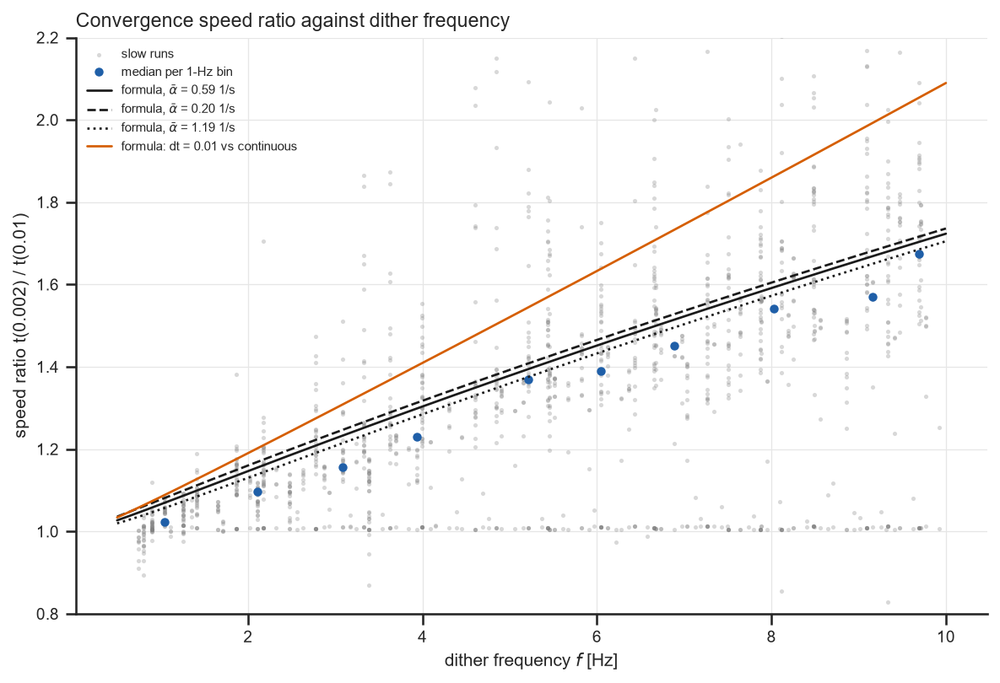

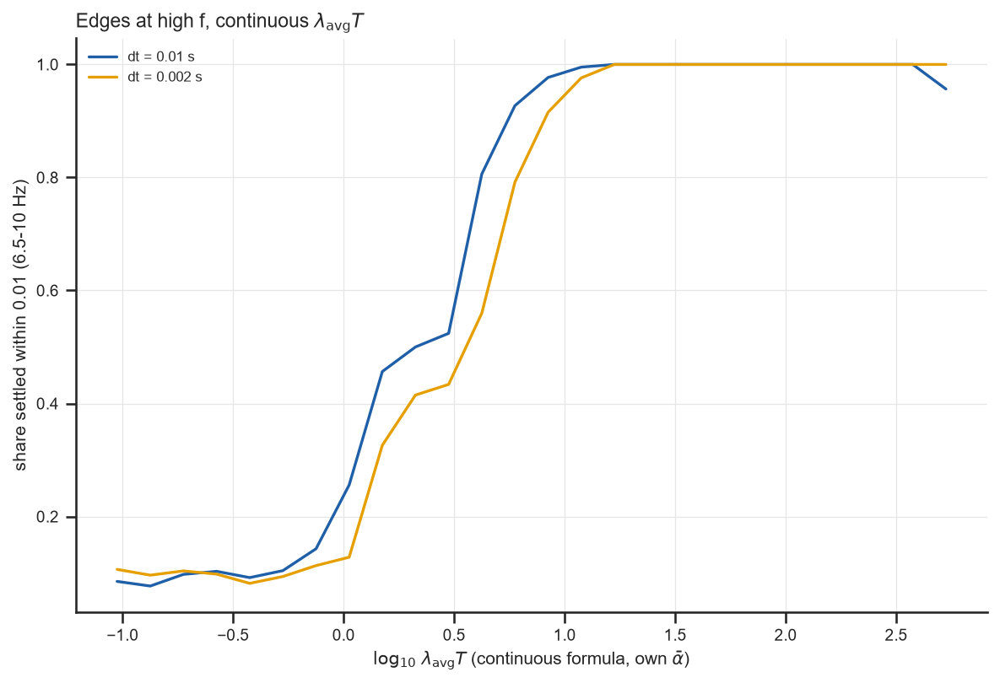

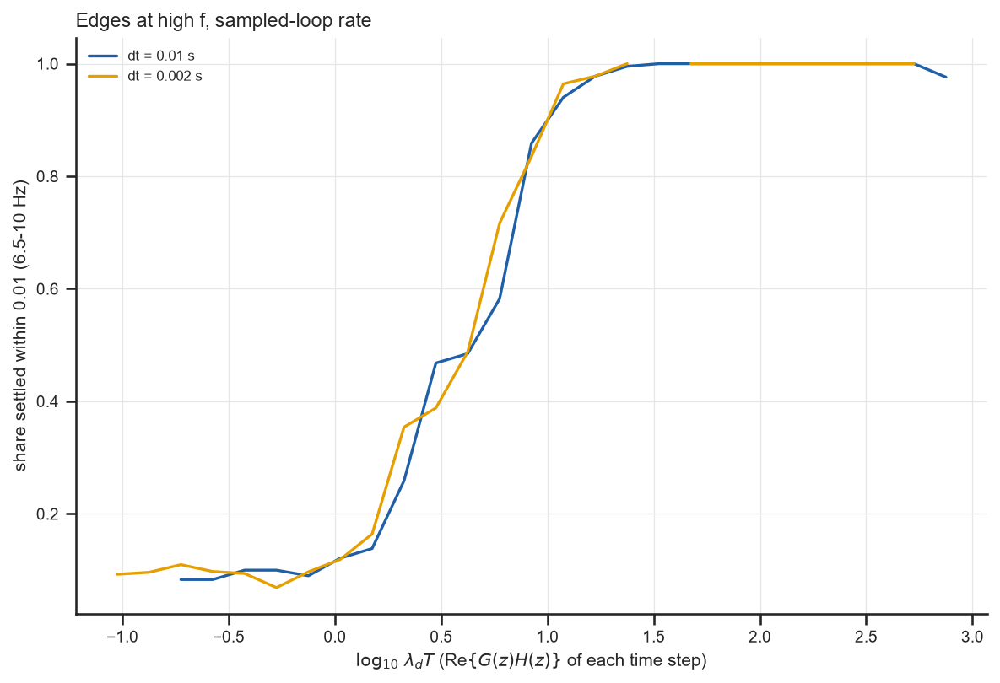

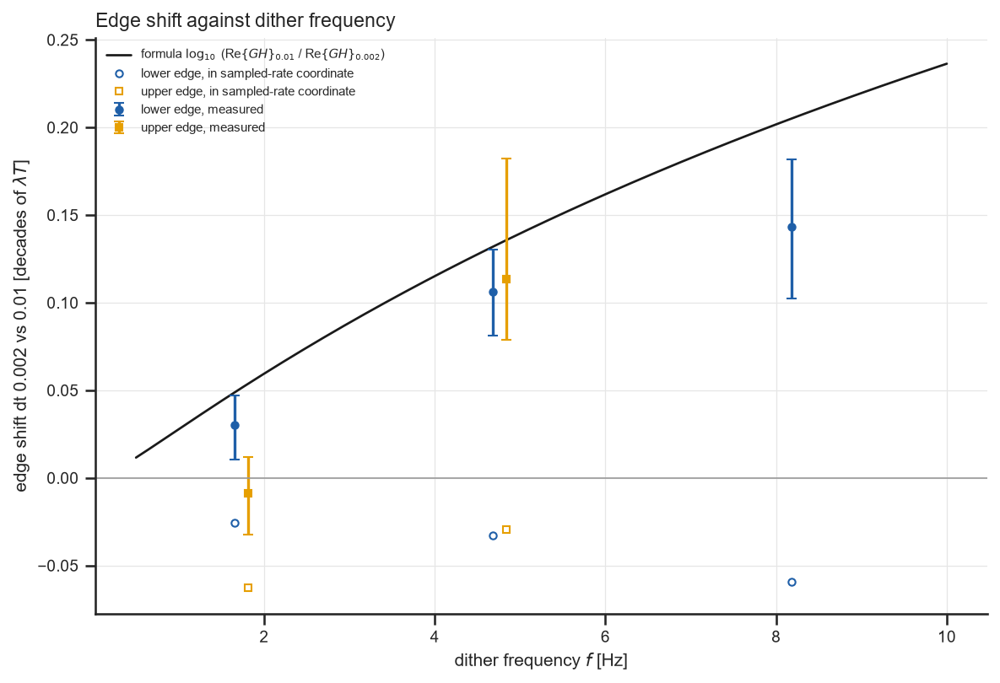

In [36]:
show_separate(panels_5)

**What this shows (for JJ).**
- Energy hardly depends on the time step: gains and $\eta$ at $dt = 0.002$ s and $0.01$ s agree closely run by run (printed
  medians). The larger differences are slow runs on the rising part of the S-curve, which collect a little less with the
  slower $dt = 0.002$ loop, and runs near the unstable edge.
- Speed does depend on it, as the sampled-loop formula predicts: for slow runs the $dt = 0.01$ loop is faster by a factor that
  grows with the dither frequency, from almost nothing at 1 Hz to well over a half near 10 Hz, and the measured medians follow
  $\mathrm{Re}\{G(z)H(z)\}$ across the whole frequency range, a few percent below it (settling time also contains the plasma's
  own response, which does not speed up).
- Both region edges are now measured directly. The lower (too slow) edge moves to larger $\lambda_\mathrm{avg} T$, i.e. larger gains,
  at $dt = 0.002$, by an amount that grows with frequency and is somewhat below the formula's prediction. The upper (unstable)
  edge moves by about the formula's amount at 3-6.5 Hz, hardly at all below 3 Hz, and above 6.5 Hz it lies beyond the
  largest gain tested. In the sampled-rate coordinate the shifts become small and of the opposite sign (printed), so
  $\mathrm{Re}\{G(z)H(z)\}$ accounts for most of the effect and slightly over-predicts it, as it does for the speed ratio.
- Consequence for the window: on this subset it shifts to larger gains at $dt = 0.002$. Sets at its slow edge, among them the
  three "fastest" chosen sets, drop out, and high-gain sets that overshoot at $dt = 0.01$ come in (printed list). The window
  is about the same size. The shifts, at most about 0.15-0.2 decades at the highest frequencies, are small compared with
  the plant-to-plant shifts of Section 3, but they decide membership for sets on an edge.
- Note that $dt = 0.002$ s is itself not fully continuous at high frequency (formula printed): against a continuous-time ESC
  the $dt = 0.01$ loop is faster still. Whether the study describes a 100 Hz digital ESC or a continuous-time ESC is the
  question for JJ; with $\lambda_\mathrm{avg}$ replaced by the sampled-loop rate, the same region description holds for either.

## 6. Conclusion

All numbers below are printed from the variables computed above.

In [37]:
print('RECOMMENDED OPERATING WINDOW')
print(f'  criteria: settle within 0.01 on all {fail_settle.shape[1]} convergence plants (steady start) and on all 30 plants started at 0.3 and 0.7;')
print(f'            worst settling time <= {T_MAX:g} s; worst-plant eta >= {ETA_MIN} (plants with margin >= {MARGIN_FLOOR:g} energy units)')
print(f'  {n_win} of {len(per_set)} quasi-random sets ({n_win / len(per_set):.1%}) are inside; bootstrap range {ci_win[0]:.0f}-{ci_win[1]:.0f}')
print(f'  ranges of the sets inside (5-95 %): k {W.optimizer_gain.quantile(0.05):.2f}-{W.optimizer_gain.quantile(0.95):.2f}, '
      f'a {W.dither_amplitude.quantile(0.05):.3f}-{W.dither_amplitude.quantile(0.95):.3f}, f {W.dither_frequency.quantile(0.05):.1f}-'
      f'{W.dither_frequency.quantile(0.95):.1f} Hz (full: k {W.optimizer_gain.min():.2f}-{W.optimizer_gain.max():.2f}, '
      f'a {W.dither_amplitude.min():.3f}-{W.dither_amplitude.max():.3f}, f {W.dither_frequency.min():.1f}-{W.dither_frequency.max():.1f} Hz)')
print(f'  simple rule (nominal plant): lam_avg T >= {LAMT_MIN}, lam_avg/(2f) <= {RHO_MAX}, L_dith <= {LDITH_MAX} '
      f'(Jaccard {J_RULE:.2f} with the window)')
print(f'  chosen sets inside the window: {chosen.index[chosen.window].tolist()} '
      f'({", ".join(chosen.chosen[chosen.window])}); outside: {chosen.index[~chosen.window].tolist()}')
print(f'  chosen sets, worst-plant eta: {chosen.eta_worst.round(3).to_dict()}; worst settling time [s]: {chosen.t_worst.round(1).to_dict()}')
print('PLANT DEPENDENCE')
print(f'  good-set Jaccard index between groups: median {np.median(off_diag):.2f} (min {off_diag.min():.2f}); '
      f'five nominal families: median {np.median(J5):.2f}; same classification by all groups {agree_all:.1%}')
sp_ts = (edges.loc[TS].max() - edges.loc[TS].min()).unstack()
print(f'  time-scale groups (x0.5, x2, x3): lower edge spread {sp_ts.loc["log10 k", "lower"]:.2f} decades in k, '
      f'{sp_ts.loc["log10 lamT, own abar", "lower"]:.2f} in lamT (own abar); upper edge spread {sp_ts.loc["log10 rho, own abar", "upper"]:.2f} in rho')
print(f'  all eight groups: lower edge spread {spread.loc["log10 k", "lower"]:.2f} decades in k, {spread.loc["log10 lamT, own abar", "lower"]:.2f} '
      f'in lamT (own abar; the rest is static vs drifting plants)')
print(f'  upper edge spread: {spread.loc["log10 lamT, own abar", "upper"]:.2f} decades in lamT (own abar), '
      f'{spread.loc["log10 rho, own abar", "upper"]:.2f} in rho = lam_avg/(2f); upper edge at rho ~ {RHO_UNSTABLE:.2f}')
print(f'  energy edge spread: {lr.max() - lr.min():.2f} decades in L_dith, {ln.max() - ln.min():.2f} in L_dith/margin')
print(f'  one rule for all groups: normalised mean Jaccard {bn[0]:.2f} (time-scale groups {rule_tab.loc[TS, "normalised rule"].min():.2f}-'
      f'{rule_tab.loc[TS, "normalised rule"].max():.2f}), raw {br[0]:.2f} ({rule_tab.loc[TS, "raw rule"].min():.2f}-{rule_tab.loc[TS, "raw rule"].max():.2f})')
print(f'  region overlap of the groups (grid Jaccard, cheap dither): raw median {np.median(jr):.2f}, normalised median {np.median(jn):.2f}; '
      f'time-scale groups raw {np.round(jr_ts, 2).tolist()}, normalised {np.round(jn_ts, 2).tolist()}')
print('TWO PEAKS')
print(f'  right plateau (eta > 0.8) per plant {pp.right.min():.1%}-{pp.right.max():.1%}, model correlation '
      f'{pp[["right", "right_m"]].corr().iloc[0, 1]:.2f}; left plateau with k from 1e-3: {np.mean(q.lamT < 0.3):.1%} of runs, '
      f'model with k from 1e-5: {np.mean(lamT_ext < 0.3):.1%}')
print('TIME STEP')
print(f'  window on the dt subset: {win01.sum()} sets at dt = 0.01, {win002.sum()} at dt = 0.002, {(win01 & win002).sum()} in both; '
      f'chosen sets inside: dt = 0.01 {win01.loc[range(5)][win01.loc[range(5)]].index.tolist()}, dt = 0.002 {win002.loc[range(5)][win002.loc[range(5)]].index.tolist()}')
print(f'  slow-run speed ratio t(0.002)/t(0.01): {tab.measured.iloc[0]:.2f} at {tab.f.iloc[0]:.1f} Hz to {tab.measured.iloc[-1]:.2f} at '
      f'{tab.f.iloc[-1]:.1f} Hz; formula {tab.predicted.iloc[0]:.2f} to {tab.predicted.iloc[-1]:.2f} (measured/formula {tab["measured/predicted"].min():.2f}-{tab["measured/predicted"].max():.2f})')
for _, r in ec.iterrows():
    print(f'  {r["edge"]} edge, {r["band [Hz]"]} Hz: shift {r["shift"]:+.3f} [{r["ci low"]:+.3f}, {r["ci high"]:+.3f}] decades in continuous lamT; formula {r["formula"]:+.3f}')
print(f'  in the sampled-rate coordinate the edges move by {es["shift"].min():+.3f} to {es["shift"].max():+.3f} decades')

RECOMMENDED OPERATING WINDOW
  criteria: settle within 0.01 on all 573 convergence plants (steady start) and on all 30 plants started at 0.3 and 0.7;
            worst settling time <= 30 s; worst-plant eta >= 0.9 (plants with margin >= 2 energy units)
  142 of 2000 quasi-random sets (7.1%) are inside; bootstrap range 142-187
  ranges of the sets inside (5-95 %): k 0.41-2.49, a 0.026-0.383, f 4.5-9.8 Hz (full: k 0.30-3.09, a 0.008-0.432, f 3.1-10.0 Hz)
  simple rule (nominal plant): lam_avg T >= 40, lam_avg/(2f) <= 0.2, L_dith <= 0.1 (Jaccard 0.73 with the window)
  chosen sets inside the window: [0, 4] (reference, best energy a>=0.1); outside: [1, 2, 3]
  chosen sets, worst-plant eta: {0: 0.934, 1: 0.834, 2: 0.831, 3: 0.772, 4: 0.969}; worst settling time [s]: {0: 25.3, 1: 24.8, 2: 24.8, 3: 32.6, 4: 23.5}
PLANT DEPENDENCE
  good-set Jaccard index between groups: median 0.53 (min 0.27); five nominal families: median 0.64; same classification by all groups 69.6%
  time-scale groups (x0.

**In plain words.**
- **Where to operate.** Use a dither frequency of a few hertz or more, a gain that makes the ESC finish well within the run
  but stays well below the speed of its own filters, and a small dither amplitude. The exact ranges, the simple rule and
  how many sets pass are printed above. Inside this window ESC settles on every plant tested (sine plants aside), also from a start far
  from 0.5, and collects at least 90 % of what the plant offers on the worst plant.
- **What does not depend on the plant.** In normalised terms the region has the same shape for every plant: the lower
  edge is a minimum $\lambda_\mathrm{avg} T$, the upper edge a maximum $\lambda_\mathrm{avg}/(2f)$, and the energy limit a maximum
  $L_\mathrm{dith}$/margin. The drift shape (exponential, linear, step, random) hardly matters, although a drifting
  ideal ratio needs a somewhat faster ESC than a fixed one.
- **What depends on the plant.** The plant's time scale $\bar\alpha$ shifts the region in raw $k$ and $f$: slow plants need
  more gain, fast plants tolerate less. The plant's margin sets how cheap the dither must be. A window for an unknown
  plant has to cover the slowest and fastest plants and the smallest margin that matters. Oscillating ideal ratios (sine
  plants) are a tracking problem that no setting solves for fast oscillations.
- **Two peaks.** They come from log-uniform sampling of $k$ through the S-curve $\eta_S(\lambda_\mathrm{avg} T)$ on every plant,
  not from one plant.
- **Time step.** The 100 Hz sampled loop ($dt = 0.01$ s) converges faster than the continuous formula says at high dither
  frequency, as $\mathrm{Re}\{G(z)H(z)\}$ predicts; this is now measured over the whole frequency range. Both region edges
  move to smaller gains at $dt = 0.01$ than at $dt = 0.002$, by up to about 0.15-0.2 decades at the highest frequencies, close to
  the formula; energies are unchanged except for slow runs and runs near the unstable edge. Sets on an edge (the three
  "fastest" chosen sets) change membership. Whether the study should describe a 100 Hz digital ESC or a continuous-time ESC
  is the question for JJ; using the sampled-loop rate instead of $\lambda_\mathrm{avg}$ keeps the region description valid for either.